# FTW field-boundary predictions for Türkiye: a reproducible national characterisation

## Introduction

This notebook is the sole numerical source for a reproducible characterisation of the
distributed Fields of The World (FTW) annual field-boundary prediction product over
Türkiye. It writes the figures and tables used in the accompanying article while keeping the full
analytical path visible.

> **Interpretation guardrails.** FTW polygons are AI-detected remote-sensing field
> units. They are not cadastral or legal parcels, agricultural holdings, farms,
> ownership units, or ÇKS records. The cross-layer comparison measures consistency
> between model-output layers. It is not evidence of agricultural change, field
> loss or gain, consolidation, or land-use transition. The results characterise the
> distributed product and do not independently validate it.

FTW is a wall-to-wall field-boundary prediction product distributed through Source
Cooperative under CC-BY-4.0. The product uses Sentinel-2 imagery and a PRUE
segmentation workflow. The provider documents the confidence surface as a reliability
screen, rather than a per-polygon validity label. Annual labels identify prediction
layers rather than image-observation dates.


In [1]:
from __future__ import annotations

import json
import hashlib
import math
import os
import platform
import re
import shutil
import ssl
import subprocess
import sys
import urllib.request
import unicodedata
from datetime import date, datetime, timezone
from importlib.metadata import version
from pathlib import Path
from textwrap import dedent
from urllib.request import Request, urlopen
from urllib.error import URLError

import duckdb
import certifi
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LogNorm, Normalize
from pyproj import Geod
from jsonschema import Draft202012Validator, FormatChecker
from shapely import Point, box, from_wkb

from helpers import (
    batched_geometry_quality,
    fetch_json,
    grid_neighbour_diagnostic,
    size_band_decomposition,
    lin_concordance,
    read_xlsx_cell_rows,
)

PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
EXTERNAL_DIR = DATA_DIR / "external"
INTERIM_DIR = DATA_DIR / "interim"
FIGURES_DIR = PROJECT_ROOT / "figures"
TABLES_DIR = PROJECT_ROOT / "tables"
PROTOCOL_DIR = PROJECT_ROOT / "protocol"
PROTOCOL_SCHEMA_PATH = PROTOCOL_DIR / "protocol_decision_record.schema.json"
PROTOCOL_RECORD_PATH = PROTOCOL_DIR / "ftw_turkiye_decision_record.json"

for directory in (RAW_DIR, EXTERNAL_DIR, INTERIM_DIR, FIGURES_DIR, TABLES_DIR, PROTOCOL_DIR):
    directory.mkdir(parents=True, exist_ok=True)
DUCKDB_TEMP_DIR = INTERIM_DIR / f"duckdb_temp_{os.getpid()}"
DUCKDB_TEMP_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
DATA_VERSION = "alpha"
ACCESS_DATE = "2026-07-18"  # Fixed FTW/Natural Earth access date.
HGM_AREA_ACCESS_DATE = "2026-07-18"  # Fixed HGM workbook access date.
HGM_BOUNDARY_ACCESS_DATE = "2026-07-31"  # Fixed HGM boundary-product access date.
RAW_PARQUET_S3_VERSION_ID = "xenG_6E1OYHASAduQdF4GQVAaWhx9Z.S"
RAW_PARQUET_SIZE_BYTES = 5_907_043_512
RAW_PARQUET_SHA256 = "423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a4395fde9c5d745774d"
EXPECTED_ROW_COUNT = 29_258_428
VALID_TR_PROVINCE_REGEX = r'^(0[1-9]|[1-7][0-9]|8[0-1])$'
EXPECTED_ALPHA_SUBDIVISION_CODES = {'A', 'AG', 'AJ', 'AR', 'DA', 'HA', 'HL', 'ID', 'RA', 'SH', 'SJ'}
AREA_FLOOR_M2 = 0.0
AREA_FLOOR_SENSITIVITY_M2 = (0.0, 50.0, 100.0, 200.0, 400.0, 800.0)
DOCUMENTED_MINIMUM_MAPPING_UNIT_M2 = 400.0
AREA_FLOOR_STABILITY_COUNT_PCT = 5.0
AREA_FLOOR_STABILITY_MEDIAN_PCT = 5.0
AREA_FLOOR_STABILITY_TOTAL_AREA_PCT = 0.1
AREA_FLOOR_STABILITY_SMALL_SHARE_PP = 3.0
CONFIDENCE_THRESHOLDS = (69.0, 86.0)
RAW_CONFIDENCE_THRESHOLDS = (0.4, 0.5)
CONFIDENCE_RESCALE_DENOMINATOR = 0.578178
PROVIDER_MEAN_PIXEL_RECALL = 0.852
PROVIDER_LOCO_AUC = 0.842
FTW_EVALUATION_COUNTRIES = (
    "Austria", "Belgium", "Brazil", "Cambodia", "Croatia", "Denmark", "Estonia",
    "Finland", "France", "Germany", "India", "Kenya", "Latvia", "Lithuania",
    "Luxembourg", "the Netherlands", "Portugal", "Rwanda", "Slovakia", "Slovenia",
    "South Africa", "Spain", "Sweden", "Vietnam",
)
GRID_CELL_DEGREES = 0.1
NATIONAL_UNION_TILE_DEGREES = 0.1
DECISION_RECORD_CREATED_AT = "2026-08-01T00:00:00Z"
RAW_PARQUET = RAW_DIR / "ftw_turkiye.parquet"
CLEANED_PARQUET = INTERIM_DIR / "ftw_turkiye_cleaned_as_distributed_deduplicated.parquet"
CLEANED_METADATA = INTERIM_DIR / "ftw_turkiye_cleaned_as_distributed_deduplicated.metadata.json"
FINAL_PARQUET = INTERIM_DIR / "ftw_turkiye_as_distributed_hgm_assigned.parquet"
FINAL_METADATA = INTERIM_DIR / "ftw_turkiye_as_distributed_hgm_assigned.metadata.json"
NE_PROVINCES = EXTERNAL_DIR / "ne_10m_admin_1_turkiye.geojson"
COUNTRY_BOUNDARY = EXTERNAL_DIR / "ne10m_turkiye_boundary_wgs84.geojson"
HGM_AREA_XLSX = EXTERNAL_DIR / "il_ilce_alanlari_2026_hgm.xlsx"
HGM_PROVINCES = EXTERNAL_DIR / "hgm_2026_province_boundaries_wgs84.geojson"
HGM_PROVINCES_METADATA = EXTERNAL_DIR / "hgm_2026_province_boundaries_metadata.json"
HGM_COUNTRY_FACE_AUDIT = EXTERNAL_DIR / "hgm_2026_country_face_selection_audit.csv"
HGM_COMPONENT_AUDIT = EXTERNAL_DIR / "hgm_2026_component_assignment_audit.csv"
HGM_PREPARATION_SCRIPT = PROJECT_ROOT / "scripts" / "prepare_hgm_provinces.py"
NATURAL_EARTH_URL = "https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces.zip"
NATURAL_EARTH_ARCHIVE_SHA256 = "efc59726337323058f9446210adc96673179cd344e053666ee3d28cb58ba2b05"
NATURAL_EARTH_TURKIYE_GEOJSON_SHA256 = "18a5afb0feb78423953fd7d210842cf8876c12d8cbd811b4fe92e64de9275283"
HGM_AREA_PAGE_URL = "https://www.harita.gov.tr/il-ve-ilce-yuzolcumleri"
HGM_AREA_XLSX_URL = "https://www.harita.gov.tr/uploads/files-folder/il_ilce_alanlari.xlsx"
HGM_AREA_XLSX_SHA256 = "e6054762f2e03e72b56ef85cb430ea00b012ccc5eba3a8fea08e3a631d3b6447"
HGM_ARCHIVE_SHA256 = "da8efe4dcbe47e5e8a8a34068e1e729832420634b519fab62303b86254471284"
HGM_PROVINCE_LOOKUP_SHA256 = "6665b02547102d85d07f380147cc52f1baee6e991cc0f94ff0c844f727ec766f"
HGM_PROVINCES_SHA256 = "ae7734d90958810fae9718322788e2932290a7b7f0a9ab2affca0b3938d8c51e"
HGM_PROVINCES_METADATA_SHA256 = "1600d96c750efda2bc8a87549986f9a0aafd9cfe6eaa7432c2d0492a17f8e829"
HGM_COUNTRY_FACE_AUDIT_SHA256 = "e50c816dd53195f1ee63e02d9f4298b0ffddad6c280f15fee119b55177c8aa39"
HGM_COMPONENT_AUDIT_SHA256 = "bddd8887bc1e135eb39a1a78141669d0d9d4b638959914526ca0d6b5e9bed3d9"
HGM_PREPARATION_SCRIPT_SHA256 = "1b086807ad90c577e9acf138099320fc9b0e22101834f8412cf922ece87d8405"
HGM_BOUNDARY_PRODUCT_URL = "https://www.harita.gov.tr/urun/turkiye-mulki-idare-sinirlari/232"
FTW_PRODUCT_URL = "https://source.coop/ftw/global-data"
FTW_CATALOG_URL = "https://data.source.coop/ftw/global-data/catalog.json"
FTW_README_URL = "https://data.source.coop/ftw/global-data/README.md"
FTW_README_LAST_MODIFIED = "26 June 2026 14:27:33 GMT"
FTW_README_ETAG = "3e2421691c7d19b60ef183ae2984c8e3"
FTW_README_S3_VERSION_ID = "vgqkm9qQfklL5Yt8CoKeKfMTvtAIR4Oy"
FTW_VECTOR_METADATA_COMMIT = "e4f15533987340d0937f6b4b7463a4691e18f46b"
FTW_VECTOR_METADATA_URL = (
    "https://raw.githubusercontent.com/fieldsoftheworld/ftw-data-catalog/"
    f"{FTW_VECTOR_METADATA_COMMIT}/catalog/predictions/vectors/collection.json"
)
FTW_VECTOR_METADATA_LAST_MODIFIED = "26 June 2026 19:44:13 GMT"
FTW_VECTOR_METADATA_ETAG = "4a1247cc"
TUIK_HOLDING_SURVEY_URL = "https://veriportali.tuik.gov.tr/en/press/24869"
TUIK_MEAN_PARCEL_AREA_HA = 1.29
TUIK_MEAN_PARCELS_PER_HOLDING = 5.9
REGION_PROVENANCE_URL = "https://ansiklopedi.tubitak.gov.tr/ansiklopedi/bolgesel_kalkinma"
NATURAL_EARTH_VERSION = (
    "Natural Earth 1:10m Admin 1 – States, Provinces; source release label not supplied; "
    f"archive SHA-256 {NATURAL_EARTH_ARCHIVE_SHA256}; Türkiye derivative SHA-256 "
    f"{NATURAL_EARTH_TURKIYE_GEOJSON_SHA256}; {NATURAL_EARTH_URL}; accessed {ACCESS_DATE}"
)
GENERATED_TABLE_PATHS: set[Path] = set()

try:
    CODE_REVISION = subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, text=True
    ).strip()
    working_tree_dirty = subprocess.run(
        ["git", "status", "--porcelain"], cwd=PROJECT_ROOT,
        text=True, capture_output=True, check=True,
    ).stdout.strip()
    if working_tree_dirty:
        CODE_REVISION += "+working-tree"
except (OSError, subprocess.SubprocessError):
    CODE_REVISION = "unknown-revision"

assert RAW_PARQUET.exists(), (
    f"Missing {RAW_PARQUET}. Run `bash data/download_tr.sh` before executing this notebook."
)

def file_sha256(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def notebook_source_sha256(path: Path) -> str:
    document = json.loads(path.read_text(encoding="utf-8"))
    source_only = [
        {
            "cell_type": cell.get("cell_type"),
            "source": (
                "".join(cell.get("source", []))
                if isinstance(cell.get("source", []), list)
                else cell.get("source", "")
            ),
        }
        for cell in document.get("cells", [])
    ]
    payload = json.dumps(
        source_only, ensure_ascii=False, sort_keys=True, separators=(",", ":")
    ).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


ANALYSIS_NOTEBOOK_SOURCE_SHA256 = notebook_source_sha256(
    PROJECT_ROOT / "ftw_turkiye_eda.ipynb"
)
HELPERS_SHA256 = file_sha256(PROJECT_ROOT / "helpers.py")
REQUIREMENTS_LOCK_SHA256 = file_sha256(PROJECT_ROOT / "requirements-lock.txt")
PROTOCOL_SCHEMA_SHA256 = file_sha256(PROTOCOL_SCHEMA_PATH)
HGM_PREPARATION_SCRIPT_OBSERVED_SHA256 = file_sha256(HGM_PREPARATION_SCRIPT)
assert HGM_PREPARATION_SCRIPT_OBSERVED_SHA256 == HGM_PREPARATION_SCRIPT_SHA256


RAW_PARQUET_OBSERVED_SHA256 = file_sha256(RAW_PARQUET)
assert RAW_PARQUET.stat().st_size == RAW_PARQUET_SIZE_BYTES, "Raw GeoParquet byte length changed."
assert RAW_PARQUET_OBSERVED_SHA256 == RAW_PARQUET_SHA256, "Raw GeoParquet SHA-256 changed."

display(Markdown(f"""*Author: Yunus Serhat Bıçakçı*  
*Notebook date: {ACCESS_DATE}*"""))

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)

def sql_path(path: Path) -> str:
    return str(path.resolve()).replace("'", "''")


HTTPS_CONTEXT = ssl.create_default_context(cafile=certifi.where())


def download_file(url: str, path: Path, expected_sha256: str | None = None) -> None:
    request = Request(url, headers={'User-Agent': 'ftw-turkiye-eda/round1'})
    try:
        with urlopen(request, timeout=120, context=HTTPS_CONTEXT) as response:
            path.write_bytes(response.read())
    except (URLError, ssl.SSLError):
        if expected_sha256 is None:
            raise
        subprocess.run(
            ['curl', '-L', '--fail', '--silent', '--show-error', url, '-o', str(path)],
            check=True,
        )
    if expected_sha256 is not None:
        observed_sha256 = hashlib.sha256(path.read_bytes()).hexdigest()
        assert observed_sha256 == expected_sha256, (
            f'Download hash mismatch for {url}: {observed_sha256}'
        )


def save_figure(figure, stem: str) -> None:
    # Save each figure in the two required publication formats.
    figure.savefig(
        FIGURES_DIR / f"{stem}.png", dpi=300, bbox_inches="tight",
        metadata={"Software": "ftw-turkiye-eda"},
    )
    figure.savefig(
        FIGURES_DIR / f"{stem}.pdf", bbox_inches="tight",
        metadata={"Creator": "ftw-turkiye-eda", "CreationDate": None, "ModDate": None},
    )
    plt.show()
    plt.close(figure)


def write_table(frame: pd.DataFrame, filename: str) -> Path:
    # Write a CSV table without an implicit index.
    path = TABLES_DIR / filename
    frame.to_csv(path, index=False, lineterminator="\n")
    GENERATED_TABLE_PATHS.add(path.resolve())
    return path


PACKAGE_NAMES = [
    "duckdb",
    "pandas",
    "pyarrow",
    "numpy",
    "scipy",
    "matplotlib",
    "geopandas",
    "pyogrio",
    "pyproj",
    "shapely",
    "jupyterlab",
    "nbconvert",
    "nbformat",
    "nbclient",
    "ipykernel",
    "jsonschema",
    "certifi",
]
package_versions = pd.DataFrame(
    {"package": PACKAGE_NAMES, "version": [version(name) for name in PACKAGE_NAMES]}
)
write_table(package_versions, "table_s0_reproducibility_environment.csv")
code_source_provenance = pd.DataFrame([
    {
        "path": "ftw_turkiye_eda.ipynb",
        "hash_definition": "SHA-256 of ordered cell_type and source text; outputs and execution metadata excluded",
        "sha256": ANALYSIS_NOTEBOOK_SOURCE_SHA256,
    },
    {
        "path": "helpers.py",
        "hash_definition": "SHA-256 of file bytes",
        "sha256": HELPERS_SHA256,
    },
    {
        "path": "requirements-lock.txt",
        "hash_definition": "SHA-256 of hash-locked transitive dependency resolution",
        "sha256": REQUIREMENTS_LOCK_SHA256,
    },
    {
        "path": "scripts/prepare_hgm_provinces.py",
        "hash_definition": "SHA-256 of file bytes",
        "sha256": HGM_PREPARATION_SCRIPT_OBSERVED_SHA256,
    },
    {
        "path": "protocol/protocol_decision_record.schema.json",
        "hash_definition": "SHA-256 of file bytes",
        "sha256": PROTOCOL_SCHEMA_SHA256,
    },
])
code_source_provenance["git_revision_at_execution"] = CODE_REVISION
write_table(code_source_provenance, "table_s0_code_source_provenance.csv")

print(f"Python: {sys.version.split()[0]}")
print(f"Platform: {platform.platform()}")
print(f"Seed: {SEED}")
print(f"FTW data version: {DATA_VERSION}")
print(f"Access date: {ACCESS_DATE}")
display(package_versions)


*Author: Yunus Serhat Bıçakçı*  
*Notebook date: 2026-07-18*

Python: 3.13.14
Platform: Linux-5.15.0-322.203.3.3.el9uek.x86_64-x86_64-with-glibc2.34
Seed: 42
FTW data version: alpha
Access date: 2026-07-18


,package,version
0,duckdb,1.5.4
1,pandas,3.0.3
2,pyarrow,25.0.0
3,numpy,2.4.6
4,scipy,1.18.0
5,matplotlib,3.11.0
6,geopandas,1.1.4
7,pyogrio,0.13.0
8,pyproj,3.7.2
9,shapely,2.1.2


## Methods at a glance

The notebook reads the local Türkiye GeoParquet partition with DuckDB, applies
deterministic geometric cleaning, and calculates all national and province summaries in
geospatial SQL. It writes each table as CSV and each main figure as PNG and PDF.
Supplementary checks document the extract, metric consistency, selection decisions, and
software environment.


In [2]:
con = duckdb.connect()
con.execute("SET TimeZone = 'UTC'")
con.execute(f"SET threads TO {min(4, max(1, os.cpu_count() or 1))}")
con.execute("SET memory_limit TO '24GB'")
con.execute("SET preserve_insertion_order TO false")
con.execute(f"SET temp_directory TO '{sql_path(DUCKDB_TEMP_DIR)}'")
con.execute("SET enable_progress_bar TO false")

try:
    con.execute("LOAD spatial")
except duckdb.Error:
    con.execute("INSTALL spatial")
    con.execute("LOAD spatial")

con.execute(
    f'''CREATE OR REPLACE VIEW ftw_source AS
    SELECT
        *,
        EXTRACT(YEAR FROM "determination:datetime")::INTEGER AS layer
    FROM read_parquet('{sql_path(RAW_PARQUET)}')'''
)

schema_df = con.execute("DESCRIBE ftw_source").fetchdf()
write_table(schema_df, "table_s0_schema.csv")
schema_columns = set(schema_df['column_name'].astype(str))
assert 'confidence' in schema_columns, 'The distributed confidence field is missing.'
assert not any('probability' in name.lower() for name in schema_columns), (
    'A raw-probability field appeared in the schema and requires explicit review.'
)

row_count = int(con.execute("SELECT count(*) FROM ftw_source").fetchone()[0])
assert row_count == EXPECTED_ROW_COUNT, (
    f"Expected {EXPECTED_ROW_COUNT:,} rows, found {row_count:,}."
)

datetime_qc = con.execute(
    '''SELECT
        "determination:datetime" AS annual_layer_label,
        count(*) AS field_count
    FROM ftw_source
    GROUP BY 1
    ORDER BY 1'''
).fetchdf()
datetime_qc["layer"] = pd.to_datetime(datetime_qc["annual_layer_label"], utc=True).dt.year

derived_layer_values = con.execute(
    "SELECT DISTINCT layer FROM ftw_source ORDER BY layer"
).fetchdf()
derived_layer_years = set(derived_layer_values["layer"].astype(int))
assert derived_layer_years == {2024, 2025}, (
    f"Expected UTC-derived layers {{2024, 2025}}, found {sorted(derived_layer_years)}."
)

method_qc = con.execute(
    '''SELECT "determination:method" AS value, count(*) AS field_count
    FROM ftw_source GROUP BY 1 ORDER BY 1 NULLS FIRST'''
).fetchdf()
country_qc = con.execute(
    '''SELECT "admin:country_code" AS value, count(*) AS field_count
    FROM ftw_source GROUP BY 1 ORDER BY 1 NULLS FIRST'''
).fetchdf()
subdivision_values = con.execute(
    '''SELECT "admin:subdivision_code" AS subdivision_code, count(*) AS field_count
    FROM ftw_source GROUP BY 1 ORDER BY 1 NULLS FIRST'''
).fetchdf()
numeric_qc = con.execute(
    '''SELECT
        min("metrics:area") AS min_area_m2,
        max("metrics:area") AS max_area_m2,
        sum(CASE WHEN "metrics:area" <= 0 OR "metrics:area" IS NULL THEN 1 ELSE 0 END) AS invalid_or_null_area_rows,
        min("metrics:perimeter") AS min_perimeter_m,
        max("metrics:perimeter") AS max_perimeter_m,
        sum(CASE WHEN "metrics:perimeter" <= 0 OR "metrics:perimeter" IS NULL THEN 1 ELSE 0 END) AS invalid_or_null_perimeter_rows,
        min(bbox.xmin) AS min_xmin,
        min(bbox.ymin) AS min_ymin,
        max(bbox.xmax) AS max_xmax,
        max(bbox.ymax) AS max_ymax,
        sum(CASE WHEN bbox IS NULL THEN 1 ELSE 0 END) AS null_bbox_rows,
        sum(CASE WHEN "admin:subdivision_code" IS NULL THEN 1 ELSE 0 END) AS null_subdivision_rows
    FROM ftw_source'''
).fetchdf().iloc[0]

assert len(datetime_qc) == 2, "The extract must contain exactly two annual layer labels."
assert set(datetime_qc["layer"].astype(int)) == {2024, 2025}, (
    "Timestamp labels did not resolve to the expected UTC layer years."
)
assert method_qc["value"].tolist() == ["auto-imagery"], "Unexpected determination method."
assert country_qc["value"].tolist() == ["TR"], "Unexpected country code."
assert int(numeric_qc["invalid_or_null_area_rows"]) == 0, "Invalid source area values found."
assert int(numeric_qc["invalid_or_null_perimeter_rows"]) == 0, "Invalid source perimeter values found."
assert int(numeric_qc["null_bbox_rows"]) == 0, "Null source bounding boxes found."

expected_codes = {f"{number:02d}" for number in range(1, 82)}
observed_codes = set(subdivision_values["subdivision_code"].dropna().astype(str))
unexpected_codes = sorted(observed_codes - expected_codes)
missing_expected_codes = sorted(expected_codes - observed_codes)
unexpected_subdivision_rows = int(
    subdivision_values.loc[
        subdivision_values["subdivision_code"].isin(unexpected_codes), "field_count"
    ].sum()
)
assert missing_expected_codes == ['53'], (
    f'Expected only province code 53 (Rize) to be absent, found {missing_expected_codes}.'
)
assert set(unexpected_codes) == EXPECTED_ALPHA_SUBDIVISION_CODES, (
    f'Unexpected alphabetic-code set changed: {unexpected_codes}.'
)

category_qc = pd.concat(
    [
        datetime_qc.assign(category="determination:datetime").rename(
            columns={"annual_layer_label": "value"}
        )[["category", "value", "field_count"]],
        method_qc.assign(category="determination:method")[["category", "value", "field_count"]],
        country_qc.assign(category="admin:country_code")[["category", "value", "field_count"]],
        subdivision_values.assign(category="admin:subdivision_code").rename(
            columns={"subdivision_code": "value"}
        )[["category", "value", "field_count"]],
    ],
    ignore_index=True,
)
write_table(category_qc, "table_s0_category_qc.csv")
write_table(subdivision_values, "table_s0_subdivision_code_counts_source.csv")

product_extract_characteristics = pd.DataFrame(
    [
        ("Product", "Global Fields of The World (FTW) field-boundary predictions", ""),
        ("Extract", RAW_PARQUET.name, ""),
        ("Immutable S3 version ID", RAW_PARQUET_S3_VERSION_ID, "source object"),
        ("Raw byte length", RAW_PARQUET_SIZE_BYTES, "bytes"),
        ("Raw SHA-256", RAW_PARQUET_SHA256, "verified before analysis"),
        ("Data version", DATA_VERSION, ""),
        ("Access date", ACCESS_DATE, ""),
        ("Source row count", row_count, "rows"),
        ("Expected row-count QC", row_count == EXPECTED_ROW_COUNT, ""),
        ("Geometry CRS", "OGC:CRS84", "longitude-latitude"),
        ("Observed annual layer labels", len(datetime_qc), "distinct values"),
        ("Observed determination method", method_qc.loc[0, "value"], ""),
        ("Observed country code", country_qc.loc[0, "value"], ""),
        ("Distinct non-null subdivision codes", len(observed_codes), "codes"),
        ("Valid Turkish province codes observed", len(observed_codes & expected_codes), "of 81"),
        ("Expected Turkish province code absent", ', '.join(missing_expected_codes), "53 is Rize"),
        ("Alphabetic cross-border suffixes observed", len(unexpected_codes), "audited before analysis"),
        ("Null subdivision-code rows", int(numeric_qc["null_subdivision_rows"]), "rows"),
        ("Minimum provider area", float(numeric_qc["min_area_m2"]), "m²"),
        ("Maximum provider area", float(numeric_qc["max_area_m2"]), "m²"),
        ("Minimum provider perimeter", float(numeric_qc["min_perimeter_m"]), "m"),
        ("Maximum provider perimeter", float(numeric_qc["max_perimeter_m"]), "m"),
        (
            "Bounding-box extent",
            (
                f"{numeric_qc['min_xmin']:.6f}, {numeric_qc['min_ymin']:.6f}, "
                f"{numeric_qc['max_xmax']:.6f}, {numeric_qc['max_ymax']:.6f}"
            ),
            "xmin, ymin, xmax, ymax in degrees",
        ),
        ("Licence", "CC-BY-4.0", "provider attribution"),
        ("Primary reporting geometry", "HGM 2026 Türkiye Mülki İdare Sınırları-derived 81-province geometry", "point-on-surface assignment; indicative/non-legal"),
        ("Primary reporting geometry SHA-256", HGM_PROVINCES_SHA256, "verified before assignment"),
        ("HGM-only derivation", "HGM boundary lines, settlement points, province-area workbook, and pinned face manifest", "no external boundary geometry used for face selection or labelling"),
        ("HGM boundary source access date", HGM_BOUNDARY_ACCESS_DATE, "fixed; never derived from execution day"),
        ("HGM area-workbook access date", HGM_AREA_ACCESS_DATE, "fixed; never derived from execution day"),
        ("HGM derivation audit", "57/130 country faces selected; 353 province faces; 81 province geometries", "face- and component-level ledgers are hash-verified"),
        ("Natural Earth Admin-1 reference", NATURAL_EARTH_VERSION, "assignment sensitivity only"),
    ],
    columns=["characteristic", "value", "unit_or_note"],
)
write_table(product_extract_characteristics, "table_s_product_extract_characteristics.csv")

print(f"Source row-count assertion passed: {row_count:,} rows")
display(schema_df)
display(product_extract_characteristics)
display(datetime_qc)
if unexpected_codes or missing_expected_codes:
    display(
        Markdown(
            f'''**QC discrepancy retained for transparent handling.** The source has
            {len(observed_codes)} distinct non-null subdivision codes. It contains
            {unexpected_subdivision_rows:,} rows with alphabetic subdivision suffixes
            ({', '.join(unexpected_codes)}), and the expected numeric code absent from the
            source is {', '.join(missing_expected_codes)} (Rize). The spatial and ISO
            reconciliation below determines the final analysis scope before any national,
            province or region result is calculated.'''
        )
    )


Source row-count assertion passed: 29,258,428 rows


,column_name,column_type,null,key,default,extra
0,metrics:area,FLOAT,YES,None,None,None
1,metrics:perimeter,FLOAT,YES,None,None,None
2,id,VARCHAR,YES,None,None,None
3,determination:datetime,TIMESTAMP WITH TIME ZONE,YES,None,None,None
4,determination:method,VARCHAR,YES,None,None,None
5,geometry,GEOMETRY('OGC:CRS84'),YES,None,None,None
6,bbox,"STRUCT(xmin DOUBLE, ymin DOUBLE, xmax DOUBLE, ...",YES,None,None,None
7,admin:country_code,VARCHAR,YES,None,None,None
8,admin:subdivision_code,VARCHAR,YES,None,None,None
9,confidence,FLOAT,YES,None,None,None


,characteristic,value,unit_or_note
0,Product,Global Fields of The World (FTW) field-boundar...,
1,Extract,ftw_turkiye.parquet,
2,Immutable S3 version ID,xenG_6E1OYHASAduQdF4GQVAaWhx9Z.S,source object
3,Raw byte length,5907043512,bytes
4,Raw SHA-256,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,verified before analysis
5,Data version,alpha,
6,Access date,2026-07-18,
7,Source row count,29258428,rows
8,Expected row-count QC,True,
9,Geometry CRS,OGC:CRS84,longitude-latitude


,annual_layer_label,field_count,layer
0,2024-01-01 00:00:00+00:00,14161143,2024
1,2025-01-01 00:00:00+00:00,15097285,2025


**QC discrepancy retained for transparent handling.** The source has
            91 distinct non-null subdivision codes. It contains
            948 rows with alphabetic subdivision suffixes
            (A, AG, AJ, AR, DA, HA, HL, ID, RA, SH, SJ), and the expected numeric code absent from the
            source is 53 (Rize). The spatial and ISO
            reconciliation below determines the final analysis scope before any national,
            province or region result is calculated.

### Annual-layer definition

The annual layer is derived from the provider timestamp in a UTC database session. It
distinguishes prediction layers only and is not interpreted as an observation date or a
change indicator.


In [3]:
layer_split_source = datetime_qc[["layer", "annual_layer_label", "field_count"]].copy()
layer_split_source = layer_split_source.sort_values("layer").reset_index(drop=True)
write_table(layer_split_source, "table_s0_source_layer_split.csv")
display(layer_split_source)


,layer,annual_layer_label,field_count
0,2024,2024-01-01 00:00:00+00:00,14161143
1,2025,2025-01-01 00:00:00+00:00,15097285


### Administrative scope, geometry quality, and cleaning

The analysis audits every subdivision code before national or province aggregation.
Alphabetic border-code records are reconciled by point on surface, and every reassignment
or outside-Türkiye exclusion is exported. Batched checks count null, empty, invalid, and
valid geometries before and after cleaning.

The main specification retains the as-distributed positive-area population and removes only
exact duplicate geometries within each annual layer before exhaustive HGM province assignment.
MD5 accelerates grouping only: every repeated digest is joined back to the source and
must contain one identical WKB byte string, otherwise execution stops. Where the same
geometry carries competing provider attributes, the retained row is chosen by an explicit
complete ordering of every non-geometry source field solely for deterministic provenance.
Content-fingerprinted GeoParquet caches preserve the same downstream input across reruns.

#### Minimum-area sensitivity

The 0, 50, 100, 200, 400, and 800 m² specifications distinguish robust ordering from
threshold-sensitive counts, absolute medians, and the smallest-unit tail.


In [4]:
# MD5 is used only as a grouping accelerator. Every digest that occurs more
# than once is joined back to the source and checked for exact WKB byte identity
# before a row can be removed as a duplicate.
duplicate_digest_details = con.execute(
    f"""WITH duplicate_digests AS MATERIALIZED (
        SELECT
            layer,
            md5(ST_AsWKB(geometry)) AS geometry_md5,
            count(*) AS digest_row_count
        FROM ftw_source
        WHERE "metrics:area" >= {AREA_FLOOR_M2}
        GROUP BY 1, 2
        HAVING count(*) > 1
    ), recovered AS (
        SELECT
            source.layer,
            duplicate_digests.geometry_md5,
            duplicate_digests.digest_row_count,
            count(*) AS recovered_row_count,
            count(DISTINCT ST_AsWKB(source.geometry)) AS distinct_wkb_byte_count,
            count(DISTINCT cast(source.id AS VARCHAR)) AS distinct_id_count,
            count(DISTINCT coalesce(source."admin:subdivision_code", '<NULL>'))
                AS distinct_provider_subdivision_code_count,
            string_agg(
                DISTINCT coalesce(source."admin:subdivision_code", '<NULL>'),
                '|' ORDER BY coalesce(source."admin:subdivision_code", '<NULL>')
            ) AS provider_subdivision_code_set,
            count(DISTINCT struct_pack(confidence_value := source.confidence))
                AS distinct_confidence_value_count,
            count(DISTINCT struct_pack(
                source_id := source.id,
                determination_datetime := source."determination:datetime",
                determination_method := source."determination:method",
                provider_area_m2 := source."metrics:area",
                provider_perimeter_m := source."metrics:perimeter",
                bbox_xmin := source.bbox.xmin,
                bbox_ymin := source.bbox.ymin,
                bbox_xmax := source.bbox.xmax,
                bbox_ymax := source.bbox.ymax,
                country_code := source."admin:country_code",
                subdivision_code := source."admin:subdivision_code",
                confidence_value := source.confidence
            )) AS distinct_non_geometry_attribute_tuple_count
        FROM ftw_source AS source
        INNER JOIN duplicate_digests
          ON source.layer = duplicate_digests.layer
         AND md5(ST_AsWKB(source.geometry)) = duplicate_digests.geometry_md5
        WHERE source."metrics:area" >= {AREA_FLOOR_M2}
        GROUP BY 1, 2, 3
    )
    SELECT * FROM recovered ORDER BY layer, geometry_md5"""
).fetchdf()
assert duplicate_digest_details['recovered_row_count'].eq(
    duplicate_digest_details['digest_row_count']
).all(), 'Duplicate-digest audit failed to recover every source row.'
assert duplicate_digest_details['distinct_wkb_byte_count'].eq(1).all(), (
    'An MD5 collision joined non-identical WKB byte strings; exact duplicate removal aborted.'
)
duplicate_digest_audit_rows = []
for audit_layer in (2024, 2025):
    layer_audit = duplicate_digest_details.loc[
        duplicate_digest_details['layer'].eq(audit_layer)
    ]
    duplicate_digest_audit_rows.append({
        'layer': audit_layer,
        'duplicate_digest_group_count': len(layer_audit),
        'rows_in_duplicate_digest_groups': int(layer_audit['digest_row_count'].sum()),
        'exact_wkb_duplicate_rows_removed': int(
            (layer_audit['digest_row_count'] - 1).sum()
        ),
        'maximum_distinct_wkb_byte_count_within_digest': int(
            layer_audit['distinct_wkb_byte_count'].max() if len(layer_audit) else 0
        ),
        'digest_collision_group_count': int(
            layer_audit['distinct_wkb_byte_count'].gt(1).sum()
        ),
        'groups_with_multiple_source_ids': int(
            layer_audit['distinct_id_count'].gt(1).sum()
        ),
        'groups_with_multiple_provider_subdivision_codes': int(
            layer_audit['distinct_provider_subdivision_code_count'].gt(1).sum()
        ),
        'rows_in_provider_subdivision_code_conflict_groups': int(
            layer_audit.loc[
                layer_audit['distinct_provider_subdivision_code_count'].gt(1),
                'digest_row_count',
            ].sum()
        ),
        'duplicate_rows_removed_from_provider_code_conflict_groups': int(
            (
                layer_audit.loc[
                    layer_audit['distinct_provider_subdivision_code_count'].gt(1),
                    'digest_row_count',
                ] - 1
            ).sum()
        ),
        'groups_with_multiple_confidence_values': int(
            layer_audit['distinct_confidence_value_count'].gt(1).sum()
        ),
        'rows_in_confidence_conflict_groups': int(
            layer_audit.loc[
                layer_audit['distinct_confidence_value_count'].gt(1),
                'digest_row_count',
            ].sum()
        ),
        'groups_with_multiple_non_geometry_attribute_tuples': int(
            layer_audit['distinct_non_geometry_attribute_tuple_count'].gt(1).sum()
        ),
        'rows_in_non_geometry_attribute_conflict_groups': int(
            layer_audit.loc[
                layer_audit['distinct_non_geometry_attribute_tuple_count'].gt(1),
                'digest_row_count',
            ].sum()
        ),
        'audit_rule': (
            'MD5 grouping accelerator followed by count(DISTINCT ST_AsWKB(geometry)); '
            'removal proceeds only when every repeated digest has one exact WKB byte string; '
            'the retained row is selected by a complete deterministic scalar-attribute order'
        ),
    })
duplicate_digest_audit = pd.DataFrame(duplicate_digest_audit_rows)
write_table(
    duplicate_digest_audit,
    'table_s_exact_wkb_duplicate_digest_audit.csv',
)
duplicate_provider_code_conflicts = (
    duplicate_digest_details.loc[
        duplicate_digest_details['distinct_provider_subdivision_code_count'].gt(1)
    ]
    .groupby(['layer', 'provider_subdivision_code_set'], as_index=False)
    .agg(
        exact_wkb_group_count=('geometry_md5', 'size'),
        rows_in_groups=('digest_row_count', 'sum'),
    )
)
duplicate_provider_code_conflicts['duplicate_rows_removed'] = (
    duplicate_provider_code_conflicts['rows_in_groups']
    - duplicate_provider_code_conflicts['exact_wkb_group_count']
)
duplicate_provider_code_conflicts['interpretation'] = (
    'Exact same-layer WKB with competing provider subdivision provenance; final aggregation '
    'uses independent HGM point-on-surface assignment'
)
write_table(
    duplicate_provider_code_conflicts,
    'table_s_exact_wkb_duplicate_provider_code_conflicts.csv',
)

cleaning_signature = {
    "raw_file_name": RAW_PARQUET.name,
    "raw_file_size_bytes": RAW_PARQUET_SIZE_BYTES,
    "raw_file_sha256": RAW_PARQUET_SHA256,
    "raw_s3_version_id": RAW_PARQUET_S3_VERSION_ID,
    "timezone": "UTC",
    "area_floor_m2": AREA_FLOOR_M2,
    "duplicate_definition": (
        "exact ST_AsWKB(geometry) byte identity within annual layer; MD5 grouping "
        "accelerator with an asserted byte-equality collision guard; the retained row "
        "is selected by a complete deterministic scalar-attribute order"
    ),
}

cache_is_current = False
if CLEANED_PARQUET.exists() and CLEANED_METADATA.exists():
    try:
        cache_is_current = json.loads(CLEANED_METADATA.read_text(encoding="utf-8")) == cleaning_signature
    except json.JSONDecodeError:
        cache_is_current = False

if not cache_is_current:
    CLEANED_PARQUET.unlink(missing_ok=True)
    CLEANED_METADATA.unlink(missing_ok=True)
    con.execute(
        f"""COPY (
            SELECT * EXCLUDE (geometry_md5, duplicate_rank)
            FROM (
                SELECT
                    *,
                    md5(ST_AsWKB(geometry)) AS geometry_md5,
                    row_number() OVER (
                        PARTITION BY layer, md5(ST_AsWKB(geometry))
                        ORDER BY
                            id,
                            "admin:subdivision_code" NULLS LAST,
                            confidence NULLS LAST,
                            "determination:datetime",
                            "determination:method" NULLS LAST,
                            "admin:country_code" NULLS LAST,
                            "metrics:area",
                            "metrics:perimeter",
                            bbox.xmin, bbox.ymin, bbox.xmax, bbox.ymax
                    ) AS duplicate_rank
                FROM ftw_source
                WHERE "metrics:area" >= {AREA_FLOOR_M2}
            ) AS hashed_rows
            WHERE duplicate_rank = 1
        ) TO '{sql_path(CLEANED_PARQUET)}'
        (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 100000)"""
    )
    CLEANED_METADATA.write_text(json.dumps(cleaning_signature, indent=2), encoding="utf-8")
    cache_message = "A fresh cleaned GeoParquet cache was created."
else:
    cache_message = "The existing cleaned GeoParquet cache matches the source fingerprint."

con.execute(
    f"""CREATE OR REPLACE VIEW ftw_cleaned_all AS
    SELECT * FROM read_parquet('{sql_path(CLEANED_PARQUET)}')"""
)

# Reconcile alphabetic border-code spillovers by point-on-surface before analysis.
if not NE_PROVINCES.exists():
    archive = EXTERNAL_DIR / 'ne_10m_admin_1_states_provinces.zip'
    download_file(NATURAL_EARTH_URL, archive, NATURAL_EARTH_ARCHIVE_SHA256)
    world_admin1 = gpd.read_file(f'zip://{archive}')
    world_admin1.loc[world_admin1['adm0_a3'].eq('TUR')].to_crs('EPSG:4326').to_file(
        NE_PROVINCES, driver='GeoJSON'
    )
    archive.unlink(missing_ok=True)
assert file_sha256(NE_PROVINCES) == NATURAL_EARTH_TURKIYE_GEOJSON_SHA256, (
    'Natural Earth Türkiye GeoJSON digest changed; review sensitivity boundaries.'
)
assert HGM_PROVINCES.exists() and HGM_PROVINCES_METADATA.exists(), (
    'Missing deterministic HGM-derived 81-province reporting geometry or its metadata.'
)
assert file_sha256(HGM_PROVINCES) == HGM_PROVINCES_SHA256
assert file_sha256(HGM_PROVINCES_METADATA) == HGM_PROVINCES_METADATA_SHA256
assert file_sha256(HGM_COUNTRY_FACE_AUDIT) == HGM_COUNTRY_FACE_AUDIT_SHA256
assert file_sha256(HGM_COMPONENT_AUDIT) == HGM_COMPONENT_AUDIT_SHA256
assert file_sha256(HGM_PREPARATION_SCRIPT) == HGM_PREPARATION_SCRIPT_SHA256
hgm_derivation_metadata = json.loads(HGM_PROVINCES_METADATA.read_text(encoding='utf-8'))
assert hgm_derivation_metadata['output_sha256'] == HGM_PROVINCES_SHA256
assert hgm_derivation_metadata['country_face_audit_sha256'] == HGM_COUNTRY_FACE_AUDIT_SHA256
assert hgm_derivation_metadata['component_assignment_audit_sha256'] == HGM_COMPONENT_AUDIT_SHA256
assert hgm_derivation_metadata['province_count'] == 81
assert hgm_derivation_metadata['polygonized_country_face_count'] == 130
assert hgm_derivation_metadata['selected_country_face_count'] == 57
assert hgm_derivation_metadata['polygonized_province_face_count'] == 353
assert hgm_derivation_metadata['country_face_discovery']['exactly_matches_manifest'] is True
assert math.isclose(
    hgm_derivation_metadata['output_area_km2_in_hgm_equal_area_crs'],
    780043.0085719698, abs_tol=1e-6,
)
assert math.isclose(hgm_derivation_metadata['national_area_difference_km2'], 0.0085719698, abs_tol=1e-9)
assert hgm_derivation_metadata['maximum_absolute_province_area_difference_pct'] < 0.12
assert hgm_derivation_metadata['input_sha256']['derivation_script'] == HGM_PREPARATION_SCRIPT_SHA256
assert hgm_derivation_metadata['input_sha256']['hgm_archive'] == HGM_ARCHIVE_SHA256
assert hgm_derivation_metadata['input_sha256']['hgm_area_workbook'] == HGM_AREA_XLSX_SHA256
assert hgm_derivation_metadata['input_sha256']['province_lookup'] == HGM_PROVINCE_LOOKUP_SHA256
reconciliation_provinces = gpd.read_file(HGM_PROVINCES)
assert len(reconciliation_provinces) == 81
assert reconciliation_provinces['province_code'].is_unique
assert reconciliation_provinces.is_valid.all()
assert set(reconciliation_provinces['province_code']) == {f'{number:02d}' for number in range(1, 82)}
garip_island_point = Point(26.785195, 39.006020)
garip_island_matches = reconciliation_provinces.loc[
    reconciliation_provinces.geometry.covers(garip_island_point), 'province_code'
].tolist()
assert garip_island_matches == ['35'], (
    f'Garip Island completeness guard expected İzmir (35), found {garip_island_matches}.'
)
natural_earth_provinces = gpd.read_file(NE_PROVINCES)
natural_earth_provinces['province_code'] = natural_earth_provinces['iso_3166_2'].str.replace(
    'TR-', '', regex=False
)
alpha_source_rows = con.execute(
    f"""SELECT id, layer, "admin:subdivision_code" AS original_subdivision_suffix,
        "metrics:area" AS mapped_area_m2,
        bbox.xmin AS bbox_xmin, bbox.ymin AS bbox_ymin,
        bbox.xmax AS bbox_xmax, bbox.ymax AS bbox_ymax,
        ST_AsWKB(geometry) AS geometry_wkb
    FROM ftw_source
    WHERE NOT regexp_full_match("admin:subdivision_code", '{VALID_TR_PROVINCE_REGEX}')"""
).fetchdf()
alpha_source_geometries = gpd.GeoSeries(
    [from_wkb(bytes(value)) for value in alpha_source_rows['geometry_wkb']], crs='EPSG:4326'
)
alpha_source_features = gpd.GeoDataFrame(
    alpha_source_rows.drop(columns='geometry_wkb'),
    geometry=alpha_source_geometries, crs='EPSG:4326',
)
alpha_source_points = alpha_source_features.copy()
alpha_source_points.geometry = alpha_source_features.representative_point()
reassignment_candidates = gpd.sjoin(
    alpha_source_points,
    reconciliation_provinces[['province_code', 'geometry']],
    how='left', predicate='covered_by',
)
reassignment_candidates['source_row_index'] = reassignment_candidates.index
province_geometry_lookup = reconciliation_provinces.set_index('province_code').geometry
reassignment_candidates['intersection_area_degrees2'] = [
    (
        alpha_source_features.geometry.loc[source_index].intersection(
            province_geometry_lookup.loc[province_code]
        ).area
        if pd.notna(province_code) else -1.0
    )
    for source_index, province_code in zip(
        reassignment_candidates['source_row_index'], reassignment_candidates['province_code']
    )
]
source_subdivision_reassignment = (
    reassignment_candidates.sort_values(
        ['source_row_index', 'intersection_area_degrees2', 'province_code'],
        ascending=[True, False, True], na_position='last',
    )
    .drop_duplicates('source_row_index', keep='first')
    .drop(columns=['index_right', 'geometry', 'source_row_index', 'intersection_area_degrees2'])
)
source_subdivision_reassignment = source_subdivision_reassignment.rename(
    columns={'province_code': 'reconciled_province_code'}
)
reassignment_key = [
    'layer', 'original_subdivision_suffix',
    'bbox_xmin', 'bbox_ymin', 'bbox_xmax', 'bbox_ymax',
]
assert not source_subdivision_reassignment.duplicated(reassignment_key).any()
source_subdivision_reassignment['representative_point_inside_turkiye'] = (
    source_subdivision_reassignment['reconciled_province_code'].notna()
)
source_subdivision_reassignment['reconciliation_method'] = (
    'Point-on-surface covered by deterministic HGM-derived 2026 province geometry; overlapping matches use largest polygon intersection then province code; otherwise excluded'
)
write_table(source_subdivision_reassignment, 'table_s_subdivision_reassignment_ids.csv')
con.register(
    'source_subdivision_reassignment_sql',
    source_subdivision_reassignment[[
        'id', *reassignment_key, 'reconciled_province_code',
    ]],
)
province_assignment_wkb = pd.DataFrame({
    'province_code': reconciliation_provinces['province_code'].astype(str),
    'geometry_wkb': reconciliation_provinces.geometry.to_wkb(),
})
con.register('province_assignment_wkb', province_assignment_wkb)
con.execute(
    """CREATE OR REPLACE TEMP TABLE province_assignment_geometry AS
    SELECT province_code, ST_GeomFromWKB(geometry_wkb) AS geometry
    FROM province_assignment_wkb"""
)

# The provider's numeric subdivision labels fail a spatial audit, so every
# retained polygon is assigned independently by point-on-surface to the pinned,
# deterministic HGM-derived 2026 province reporting geometry. Original provider codes remain in a separate
# column. No-match rows are excluded; multiple matches are resolved by largest
# polygon/province intersection, then province code.
spatial_assignment_signature = {
    **cleaning_signature,
    'hgm_province_geometry_sha256': HGM_PROVINCES_SHA256,
    'hgm_province_metadata_sha256': HGM_PROVINCES_METADATA_SHA256,
    'hgm_preparation_script_sha256': HGM_PREPARATION_SCRIPT_SHA256,
    'hgm_country_face_audit_sha256': HGM_COUNTRY_FACE_AUDIT_SHA256,
    'hgm_component_audit_sha256': HGM_COMPONENT_AUDIT_SHA256,
    'hgm_archive_input_sha256': HGM_ARCHIVE_SHA256,
    'hgm_province_lookup_input_sha256': HGM_PROVINCE_LOOKUP_SHA256,
    'assignment_method': (
        'ST_PointOnSurface covered by deterministic HGM-derived 2026 provinces; multiple matches use largest '
        'polygon intersection then province code; no-match rows excluded'
    ),
}
final_cache_is_current = False
if FINAL_PARQUET.exists() and FINAL_METADATA.exists():
    try:
        final_cache_is_current = (
            json.loads(FINAL_METADATA.read_text(encoding='utf-8'))
            == spatial_assignment_signature
        )
    except json.JSONDecodeError:
        final_cache_is_current = False
if not final_cache_is_current:
    FINAL_PARQUET.unlink(missing_ok=True)
    FINAL_METADATA.unlink(missing_ok=True)
    assignment_layer_paths = [
        INTERIM_DIR / f'ftw_turkiye_as_distributed_hgm_assigned_{layer}.parquet'
        for layer in (2024, 2025)
    ]
    for assignment_layer, assignment_layer_path in zip(
        (2024, 2025), assignment_layer_paths, strict=True
    ):
        assignment_layer_path.unlink(missing_ok=True)
        print(f'Assigning the {assignment_layer} layer to HGM provinces...')
        con.execute(
            f"""COPY (
                WITH candidate_codes AS MATERIALIZED (
                    SELECT
                        cleaned.file_row_number,
                        province.province_code
                    FROM read_parquet(
                        '{sql_path(CLEANED_PARQUET)}', file_row_number=true
                    ) AS cleaned
                    JOIN province_assignment_geometry AS province
                      ON ST_CoveredBy(ST_PointOnSurface(cleaned.geometry), province.geometry)
                    WHERE cleaned.layer = {assignment_layer}
                ), candidate_counts AS (
                    SELECT file_row_number, count(*) AS candidate_count
                    FROM candidate_codes
                    GROUP BY 1
                ), single_assignments AS (
                    SELECT candidate_codes.file_row_number, candidate_codes.province_code
                    FROM candidate_codes
                    JOIN candidate_counts USING (file_row_number)
                    WHERE candidate_counts.candidate_count = 1
                ), ranked_multiple_assignments AS (
                    SELECT
                        candidate_codes.file_row_number,
                        candidate_codes.province_code,
                        row_number() OVER (
                            PARTITION BY candidate_codes.file_row_number
                            ORDER BY
                                ST_Area(ST_Intersection(
                                    cleaned.geometry, province.geometry
                                )) DESC,
                                candidate_codes.province_code
                        ) AS assignment_rank
                    FROM candidate_codes
                    JOIN candidate_counts USING (file_row_number)
                    JOIN read_parquet(
                        '{sql_path(CLEANED_PARQUET)}', file_row_number=true
                    ) AS cleaned USING (file_row_number)
                    JOIN province_assignment_geometry AS province
                      ON candidate_codes.province_code = province.province_code
                    WHERE candidate_counts.candidate_count > 1
                ), assignments AS (
                    SELECT file_row_number, province_code FROM single_assignments
                    UNION ALL
                    SELECT file_row_number, province_code
                    FROM ranked_multiple_assignments
                    WHERE assignment_rank = 1
                )
                SELECT
                    cleaned.* EXCLUDE ("admin:subdivision_code", file_row_number),
                    cleaned."admin:subdivision_code" AS provider_subdivision_code,
                    assignments.province_code AS "admin:subdivision_code"
                FROM read_parquet(
                    '{sql_path(CLEANED_PARQUET)}', file_row_number=true
                ) AS cleaned
                JOIN assignments USING (file_row_number)
                WHERE cleaned.layer = {assignment_layer}
            ) TO '{sql_path(assignment_layer_path)}'
            (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 100000)"""
        )
    assignment_layer_sources = ', '.join(
        f"'{sql_path(path)}'" for path in assignment_layer_paths
    )
    con.execute(
        f"""COPY (
            SELECT * FROM read_parquet([{assignment_layer_sources}])
        ) TO '{sql_path(FINAL_PARQUET)}'
        (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 100000)"""
    )
    for assignment_layer_path in assignment_layer_paths:
        assignment_layer_path.unlink()
    FINAL_METADATA.write_text(
        json.dumps(spatial_assignment_signature, indent=2), encoding='utf-8'
    )
    final_cache_message = 'A fresh exhaustive spatial-assignment cache was created.'
else:
    final_cache_message = 'The exhaustive spatial-assignment cache matches its fingerprints.'

con.execute(
    f"""CREATE OR REPLACE VIEW ftw_cleaned AS
    SELECT * FROM read_parquet('{sql_path(FINAL_PARQUET)}')"""
)
geometry_type_qc = con.execute(
    """SELECT
        layer,
        ST_GeometryType(geometry)::VARCHAR AS geometry_type,
        count(*) AS unit_count
    FROM ftw_cleaned
    GROUP BY 1, 2 ORDER BY 1, 2"""
).fetchdf()
assert set(geometry_type_qc["geometry_type"]) == {"POLYGON"}, (
    "Ring-aware metric checks require polygon inputs; geometry type changed"
)
write_table(geometry_type_qc, "table_s_geometry_type_qc.csv")
provider_to_spatial_crosswalk = con.execute(
    """SELECT
        layer,
        provider_subdivision_code,
        "admin:subdivision_code" AS spatially_assigned_province_code,
        count(*) AS field_count,
        sum("metrics:area") / 10000.0 AS mapped_area_ha,
        provider_subdivision_code = "admin:subdivision_code" AS provider_code_matches_assignment
    FROM ftw_cleaned
    GROUP BY 1, 2, 3, 6
    ORDER BY 1, 2, 3"""
).fetchdf()
write_table(
    provider_to_spatial_crosswalk,
    'table_s_provider_to_spatial_subdivision_crosswalk.csv',
)
assignment_exception_rows = con.execute(
    f"""WITH candidate_counts AS (
        SELECT
            cleaned.file_row_number,
            count(province.province_code) AS containing_province_count
        FROM read_parquet(
            '{sql_path(CLEANED_PARQUET)}', file_row_number=true
        ) AS cleaned
        LEFT JOIN province_assignment_geometry AS province
          ON ST_CoveredBy(ST_PointOnSurface(cleaned.geometry), province.geometry)
        GROUP BY 1
    )
    SELECT
        cleaned.layer, cleaned.id,
        cleaned."admin:subdivision_code" AS provider_subdivision_code,
        cleaned."metrics:area" / 10000.0 AS mapped_area_ha,
        cleaned.bbox.xmin AS bbox_xmin, cleaned.bbox.ymin AS bbox_ymin,
        cleaned.bbox.xmax AS bbox_xmax, cleaned.bbox.ymax AS bbox_ymax,
        candidate_counts.containing_province_count,
        CASE
            WHEN candidate_counts.containing_province_count = 0 THEN 'excluded_no_containing_province'
            ELSE 'multiple_matches_resolved_by_largest_intersection_then_code'
        END AS assignment_action
    FROM read_parquet(
        '{sql_path(CLEANED_PARQUET)}', file_row_number=true
    ) AS cleaned
    JOIN candidate_counts USING (file_row_number)
    WHERE candidate_counts.containing_province_count <> 1
    ORDER BY layer, file_row_number"""
).fetchdf()
write_table(
    assignment_exception_rows,
    'table_s_spatial_assignment_exceptions.csv',
)
assignment_candidate_multiplicity_rows = []
for multiplicity_layer in (2024, 2025):
    layer_input_count = int(con.execute(
        f"SELECT count(*) FROM ftw_cleaned_all WHERE layer = {multiplicity_layer}"
    ).fetchone()[0])
    layer_exceptions = assignment_exception_rows.loc[
        assignment_exception_rows['layer'].eq(multiplicity_layer)
    ]
    exception_counts = layer_exceptions.groupby(
        'containing_province_count'
    ).size().to_dict()
    single_count = layer_input_count - int(sum(exception_counts.values()))
    assignment_candidate_multiplicity_rows.append({
        'layer': multiplicity_layer,
        'containing_province_count': 1,
        'mapped_unit_count': single_count,
    })
    for containing_count, mapped_unit_count in sorted(exception_counts.items()):
        assignment_candidate_multiplicity_rows.append({
            'layer': multiplicity_layer,
            'containing_province_count': int(containing_count),
            'mapped_unit_count': int(mapped_unit_count),
        })
assignment_candidate_multiplicity = pd.DataFrame(
    assignment_candidate_multiplicity_rows
).sort_values(['layer', 'containing_province_count'])
write_table(
    assignment_candidate_multiplicity,
    'table_s_spatial_assignment_candidate_multiplicity.csv',
)

# Natural Earth is retained only as an independent generalized-boundary sensitivity.
natural_earth_assignment_wkb = pd.DataFrame({
    'province_code': natural_earth_provinces['province_code'].astype(str),
    'geometry_wkb': natural_earth_provinces.geometry.to_wkb(),
})
con.register('natural_earth_assignment_wkb', natural_earth_assignment_wkb)
con.execute(
    """CREATE OR REPLACE TEMP TABLE natural_earth_assignment_geometry AS
    SELECT province_code, ST_GeomFromWKB(geometry_wkb) AS geometry
    FROM natural_earth_assignment_wkb"""
)
hgm_vs_natural_earth_crosswalk = con.execute(
    """SELECT
        field.layer,
        field."admin:subdivision_code" AS hgm_assigned_province_code,
        natural_earth.province_code AS natural_earth_assigned_province_code,
        count(*) AS field_count,
        sum(field."metrics:area") / 10000.0 AS mapped_area_ha,
        field."admin:subdivision_code" = natural_earth.province_code AS assignment_codes_match
    FROM ftw_cleaned AS field
    JOIN natural_earth_assignment_geometry AS natural_earth
      ON ST_CoveredBy(ST_PointOnSurface(field.geometry), natural_earth.geometry)
    GROUP BY 1, 2, 3, 6
    ORDER BY 1, 2, 3"""
).fetchdf()
write_table(
    hgm_vs_natural_earth_crosswalk,
    'table_s_hgm_vs_natural_earth_assignment_crosswalk.csv',
)
hgm_vs_ne_summary_rows = []
for layer in (2024, 2025):
    final_count = int(con.execute(
        f'SELECT count(*) FROM ftw_cleaned WHERE layer = {layer}'
    ).fetchone()[0])
    layer_crosswalk = hgm_vs_natural_earth_crosswalk.loc[
        hgm_vs_natural_earth_crosswalk['layer'].eq(layer)
    ]
    ne_assigned_count = int(layer_crosswalk['field_count'].sum())
    same_count = int(layer_crosswalk.loc[layer_crosswalk['assignment_codes_match'], 'field_count'].sum())
    hgm_vs_ne_summary_rows.append({
        'layer': layer,
        'hgm_primary_assigned_count': final_count,
        'natural_earth_sensitivity_assigned_count': ne_assigned_count,
        'natural_earth_no_match_count_within_hgm_scope': final_count - ne_assigned_count,
        'same_province_code_count': same_count,
        'different_province_code_count': ne_assigned_count - same_count,
        'different_code_share_of_dually_assigned_pct': (
            100.0 * (ne_assigned_count - same_count) / ne_assigned_count
        ),
        'interpretation': (
            'Boundary-framework sensitivity only; HGM-derived geometry remains primary and '
            'neither source is legally authoritative'
        ),
    })
hgm_vs_natural_earth_assignment_summary = pd.DataFrame(hgm_vs_ne_summary_rows)
write_table(
    hgm_vs_natural_earth_assignment_summary,
    'table_s_hgm_vs_natural_earth_assignment_summary.csv',
)


source_counts = con.execute(
    "SELECT layer, count(*) AS field_count FROM ftw_source GROUP BY 1 ORDER BY 1"
).fetchdf()
area_floor_counts = con.execute(
    f"""SELECT layer, count(*) AS field_count
    FROM ftw_source
    WHERE "metrics:area" >= {AREA_FLOOR_M2}
    GROUP BY 1 ORDER BY 1"""
).fetchdf()
cleaned_all_counts = con.execute(
    "SELECT layer, count(*) AS field_count FROM ftw_cleaned_all GROUP BY 1 ORDER BY 1"
).fetchdf()
cleaned_counts = con.execute(
    "SELECT layer, count(*) AS field_count FROM ftw_cleaned GROUP BY 1 ORDER BY 1"
).fetchdf()

waterfall_parts = []
for stage, frame in [
    ("Source extract", source_counts),
    (f"Area floor retained (≥ {AREA_FLOOR_M2:g} m²)", area_floor_counts),
    ("Exact-WKB duplicates removed", cleaned_all_counts),
    ("Reconciled Turkish province analysis scope", cleaned_counts),
]:
    item = frame.copy()
    item["stage"] = stage
    waterfall_parts.append(item)
processing_waterfall = pd.concat(waterfall_parts, ignore_index=True)
processing_waterfall = processing_waterfall.merge(
    source_counts.rename(columns={"field_count": "source_field_count"}), on="layer", how="left"
)
processing_waterfall["percent_of_source"] = (
    100 * processing_waterfall["field_count"] / processing_waterfall["source_field_count"]
)
processing_waterfall["area_floor_m2"] = AREA_FLOOR_M2
processing_waterfall = processing_waterfall[
    ["layer", "stage", "field_count", "source_field_count", "percent_of_source", "area_floor_m2"]
]
write_table(processing_waterfall, "table_s_processing_waterfall.csv")

table_1_dataset = product_extract_characteristics.copy()
table_1_dataset.insert(0, "section", "Dataset and extract")
table_1_processing_rows = []
for _, record in processing_waterfall.iterrows():
    table_1_processing_rows.append(
        {
            "section": "Processing",
            "characteristic": f"{record['stage']} ({int(record['layer'])})",
            "value": int(record["field_count"]),
            "unit_or_note": (
                f"rows; {float(record['percent_of_source']):.3f}% of source; "
                f"area floor {float(record['area_floor_m2']):g} m²"
            ),
        }
    )
table_1 = pd.concat(
    [table_1_dataset, pd.DataFrame(table_1_processing_rows)],
    ignore_index=True,
)[["section", "characteristic", "value", "unit_or_note"]]
write_table(table_1, "table_1_dataset_extract_processing.csv")

assert int(cleaned_all_counts["field_count"].sum()) <= int(area_floor_counts["field_count"].sum())
assert int(cleaned_counts["field_count"].sum()) <= int(cleaned_all_counts["field_count"].sum())
print(cache_message)
print(final_cache_message)
print(f"Deduplicated cache size: {CLEANED_PARQUET.stat().st_size / 1_000_000_000:.2f} GB")
print(f"Spatially assigned cache size: {FINAL_PARQUET.stat().st_size / 1_000_000_000:.2f} GB")
display(table_1)
display(processing_waterfall)

# Exhaustive geometry QC is batched to keep memory bounded on the 5.9 GB source.
source_geometry_groups = batched_geometry_quality(
    con,
    RAW_PARQUET,
    layer_expression='EXTRACT(YEAR FROM "determination:datetime")::INTEGER',
    stage='Source extract',
    scope_expression=(
        f"regexp_full_match(\"admin:subdivision_code\", '{VALID_TR_PROVINCE_REGEX}')"
    ),
)
cleaned_geometry_groups = batched_geometry_quality(
    con,
    CLEANED_PARQUET,
    layer_expression='layer',
    stage='Area floor and exact-WKB deduplication',
    scope_expression=(
        f"regexp_full_match(\"admin:subdivision_code\", '{VALID_TR_PROVINCE_REGEX}')"
    ),
)
geometry_count_columns = [
    'row_count', 'null_geometry_count', 'empty_geometry_count',
    'invalid_geometry_count', 'valid_geometry_count',
]
source_geometry_all = source_geometry_groups.groupby('layer', as_index=False)[geometry_count_columns].sum()
source_geometry_all.insert(0, 'stage', 'Source extract')
source_geometry_all['scope_group'] = 'all_provider_rows'
cleaned_geometry_all = cleaned_geometry_groups.groupby('layer', as_index=False)[geometry_count_columns].sum()
cleaned_geometry_all.insert(0, 'stage', 'Area floor and exact-WKB deduplication')
cleaned_geometry_all['scope_group'] = 'all_provider_rows'
final_geometry = cleaned_counts.rename(columns={'field_count': 'row_count'}).copy()
final_geometry['null_geometry_count'] = 0
final_geometry['empty_geometry_count'] = 0
final_geometry['invalid_geometry_count'] = 0
final_geometry['valid_geometry_count'] = final_geometry['row_count']
final_geometry.insert(0, 'stage', 'Final HGM-derived province analysis')
final_geometry['scope_group'] = 'analysis_scope'
geometry_quality = pd.concat(
    [source_geometry_all, cleaned_geometry_all, final_geometry], ignore_index=True
)
geometry_quality['area_floor_removed_count'] = 0
geometry_quality['duplicate_removed_count'] = 0
geometry_quality['scope_excluded_count'] = 0
for layer in (2024, 2025):
    source_n = int(source_counts.loc[source_counts['layer'].eq(layer), 'field_count'].iloc[0])
    floor_n = int(area_floor_counts.loc[area_floor_counts['layer'].eq(layer), 'field_count'].iloc[0])
    cache_n = int(cleaned_all_counts.loc[cleaned_all_counts['layer'].eq(layer), 'field_count'].iloc[0])
    final_n = int(cleaned_counts.loc[cleaned_counts['layer'].eq(layer), 'field_count'].iloc[0])
    cleaned_mask = geometry_quality['stage'].eq('Area floor and exact-WKB deduplication') & geometry_quality['layer'].eq(layer)
    final_mask = geometry_quality['stage'].eq('Final HGM-derived province analysis') & geometry_quality['layer'].eq(layer)
    geometry_quality.loc[cleaned_mask | final_mask, 'area_floor_removed_count'] = source_n - floor_n
    geometry_quality.loc[cleaned_mask | final_mask, 'duplicate_removed_count'] = floor_n - cache_n
    geometry_quality.loc[final_mask, 'scope_excluded_count'] = cache_n - final_n
geometry_quality['duplicate_removed_pct_of_area_floor_rows'] = np.where(
    geometry_quality['stage'].eq('Source extract'),
    0.0,
    100.0 * geometry_quality['duplicate_removed_count'] / (
        geometry_quality['row_count'] + geometry_quality['duplicate_removed_count']
        + geometry_quality['scope_excluded_count']
    ),
)
geometry_quality['repair_applied'] = False
geometry_quality['exclusion_rule'] = np.select(
    [
        geometry_quality['stage'].eq('Source extract'),
        geometry_quality['stage'].eq('Area floor and exact-WKB deduplication'),
    ],
    ['None', f'Area >= {AREA_FLOOR_M2:g} m2; exact WKB deduplication within layer'],
    default=(
        f'Area >= {AREA_FLOOR_M2:g} m2; exact WKB deduplication; '
        'HGM-derived province point-on-surface assignment; no-match records excluded'
    ),
)
assert geometry_quality[['null_geometry_count', 'empty_geometry_count', 'invalid_geometry_count']].to_numpy().sum() == 0
write_table(geometry_quality, 'table_s_geometry_quality.csv')

# The primary population is as distributed (no analyst-imposed area floor),
# after exact-WKB deduplication and administrative-scope reconciliation.  The
# 0/50/100/200/400/800 m2 comparison includes the provider paper's nominal
# four-pixel (about 400 m2) minimum as a sensitivity scenario.
con.execute(
    f"""CREATE OR REPLACE TEMP TABLE ftw_valid_dedup_below_100 AS
    SELECT * EXCLUDE (geometry_md5, duplicate_rank)
    FROM (
        SELECT
            source.* EXCLUDE ("admin:subdivision_code"),
            CASE
                WHEN regexp_full_match(source."admin:subdivision_code", '{VALID_TR_PROVINCE_REGEX}')
                THEN source."admin:subdivision_code"
                ELSE reassignment.reconciled_province_code
            END AS "admin:subdivision_code",
            md5(ST_AsWKB(source.geometry)) AS geometry_md5,
            row_number() OVER (
                PARTITION BY source.layer, md5(ST_AsWKB(source.geometry)) ORDER BY source.id
            ) AS duplicate_rank
        FROM ftw_source AS source
        LEFT JOIN source_subdivision_reassignment_sql AS reassignment
          ON source.layer = reassignment.layer
         AND source."admin:subdivision_code" = reassignment.original_subdivision_suffix
         AND source.bbox.xmin = reassignment.bbox_xmin
         AND source.bbox.ymin = reassignment.bbox_ymin
         AND source.bbox.xmax = reassignment.bbox_xmax
         AND source.bbox.ymax = reassignment.bbox_ymax
        WHERE source."metrics:area" < {AREA_FLOOR_M2}
          AND (
              regexp_full_match(source."admin:subdivision_code", '{VALID_TR_PROVINCE_REGEX}')
              OR reassignment.reconciled_province_code IS NOT NULL
          )
    )
    WHERE duplicate_rank = 1"""
)
con.execute(
    """CREATE OR REPLACE TEMP VIEW ftw_sensitivity_0 AS
    SELECT * FROM ftw_cleaned
    UNION ALL BY NAME
    SELECT * FROM ftw_valid_dedup_below_100"""
)
primary_scope_counts = cleaned_counts.rename(
    columns={'field_count': 'primary_scope_unit_count'}
).copy()
sensitivity_parts = []
for floor_m2 in AREA_FLOOR_SENSITIVITY_M2:
    relation = 'ftw_sensitivity_0' if floor_m2 < AREA_FLOOR_M2 else 'ftw_cleaned'
    floor_filter = '' if floor_m2 in (0.0, AREA_FLOOR_M2) else f'WHERE "metrics:area" >= {floor_m2}'
    part = con.execute(
        f"""SELECT
            layer,
            {floor_m2}::DOUBLE AS area_floor_m2,
            count(*) AS retained_unit_count,
            sum("metrics:area") / 10000.0 AS total_mapped_area_ha,
            quantile_cont("metrics:area", 0.50) / 10000.0 AS median_unit_area_ha,
            avg("metrics:area") / 10000.0 AS mean_unit_area_ha,
            100.0 * sum(CASE WHEN "metrics:area" < 1000.0 THEN 1 ELSE 0 END) / count(*)
                AS unit_count_share_lt_0_1ha_pct,
            100.0 * sum(CASE WHEN "metrics:area" < 1000.0 THEN "metrics:area" ELSE 0 END)
                / sum("metrics:area") AS mapped_area_share_lt_0_1ha_pct,
            100.0 * sum(CASE WHEN "metrics:area" < 5000.0 THEN 1 ELSE 0 END) / count(*)
                AS unit_count_share_lt_0_5ha_pct,
            100.0 * sum(CASE WHEN "metrics:area" < 5000.0 THEN "metrics:area" ELSE 0 END)
                / sum("metrics:area") AS mapped_area_share_lt_0_5ha_pct
        FROM {relation}
        {floor_filter}
        GROUP BY 1 ORDER BY 1"""
    ).fetchdf()
    sensitivity_parts.append(part)
area_floor_sensitivity = pd.concat(sensitivity_parts, ignore_index=True).merge(
    primary_scope_counts, on='layer', how='left'
)
area_floor_sensitivity['removed_unit_count'] = (
    area_floor_sensitivity['primary_scope_unit_count'] - area_floor_sensitivity['retained_unit_count']
)
area_floor_sensitivity['removed_unit_share_pct'] = (
    100.0 * area_floor_sensitivity['removed_unit_count']
    / area_floor_sensitivity['primary_scope_unit_count']
)
primary_sensitivity = area_floor_sensitivity.loc[
    area_floor_sensitivity['area_floor_m2'].eq(AREA_FLOOR_M2),
    ['layer', 'retained_unit_count', 'total_mapped_area_ha', 'median_unit_area_ha', 'unit_count_share_lt_0_5ha_pct'],
].rename(columns={
    'retained_unit_count': 'primary_retained_unit_count',
    'total_mapped_area_ha': 'primary_total_mapped_area_ha',
    'median_unit_area_ha': 'primary_median_unit_area_ha',
    'unit_count_share_lt_0_5ha_pct': 'primary_unit_count_share_lt_0_5ha_pct',
})
area_floor_sensitivity = area_floor_sensitivity.merge(primary_sensitivity, on='layer', how='left')
area_floor_sensitivity['retained_count_difference_from_primary_pct'] = 100.0 * (
    area_floor_sensitivity['retained_unit_count']
    / area_floor_sensitivity['primary_retained_unit_count'] - 1.0
)
area_floor_sensitivity['median_difference_from_primary_pct'] = 100.0 * (
    area_floor_sensitivity['median_unit_area_ha']
    / area_floor_sensitivity['primary_median_unit_area_ha'] - 1.0
)
area_floor_sensitivity['total_mapped_area_difference_from_primary_pct'] = 100.0 * (
    area_floor_sensitivity['total_mapped_area_ha']
    / area_floor_sensitivity['primary_total_mapped_area_ha'] - 1.0
)
area_floor_sensitivity['small_unit_share_difference_from_primary_pp'] = (
    area_floor_sensitivity['unit_count_share_lt_0_5ha_pct']
    - area_floor_sensitivity['primary_unit_count_share_lt_0_5ha_pct']
)
area_floor_sensitivity['retained_count_stable_within_5pct'] = (
    area_floor_sensitivity['retained_count_difference_from_primary_pct'].abs().le(
        AREA_FLOOR_STABILITY_COUNT_PCT
    )
)
area_floor_sensitivity['median_level_stable_within_5pct'] = (
    area_floor_sensitivity['median_difference_from_primary_pct'].abs().le(AREA_FLOOR_STABILITY_MEDIAN_PCT)
)
median_order_by_floor = {}
for floor_m2, floor_frame in area_floor_sensitivity.groupby('area_floor_m2'):
    medians = dict(zip(floor_frame['layer'], floor_frame['median_unit_area_ha']))
    median_order_by_floor[floor_m2] = medians[2025] < medians[2024]
area_floor_sensitivity['annual_median_order_stable'] = (
    area_floor_sensitivity['area_floor_m2'].map(median_order_by_floor)
)
area_floor_sensitivity['documented_minimum_mapping_unit_scenario'] = (
    area_floor_sensitivity['area_floor_m2'].eq(DOCUMENTED_MINIMUM_MAPPING_UNIT_M2)
)
area_floor_sensitivity['core_distribution_conclusions_stable'] = (
    area_floor_sensitivity['retained_count_stable_within_5pct']
    & area_floor_sensitivity['median_level_stable_within_5pct']
    & area_floor_sensitivity['total_mapped_area_difference_from_primary_pct'].abs().le(
        AREA_FLOOR_STABILITY_TOTAL_AREA_PCT
    )
    & area_floor_sensitivity['small_unit_share_difference_from_primary_pp'].abs().le(
        AREA_FLOOR_STABILITY_SMALL_SHARE_PP
    )
    & area_floor_sensitivity['annual_median_order_stable']
)
area_floor_sensitivity['analysis_decision'] = (
    'Use the as-distributed population as primary; expose 50/100/200/400/800 m2 scenarios; '
    'do not treat threshold-sensitive counts or medians as invariant product facts'
)
write_table(area_floor_sensitivity, 'table_s_area_floor_sensitivity.csv')

assignment_summary_rows = []
for layer in (2024, 2025):
    source_layer_count = int(cleaned_all_counts.loc[cleaned_all_counts['layer'].eq(layer), 'field_count'].iloc[0])
    assigned_layer_count = int(cleaned_counts.loc[cleaned_counts['layer'].eq(layer), 'field_count'].iloc[0])
    layer_crosswalk = provider_to_spatial_crosswalk.loc[provider_to_spatial_crosswalk['layer'].eq(layer)]
    provider_match_count = int(
        layer_crosswalk.loc[layer_crosswalk['provider_code_matches_assignment'], 'field_count'].sum()
    )
    provider_mismatch_count = assigned_layer_count - provider_match_count
    no_match_count = int(
        assignment_exception_rows.loc[
            assignment_exception_rows['layer'].eq(layer)
            & assignment_exception_rows['containing_province_count'].eq(0)
        ].shape[0]
    )
    multiple_match_count = int(
        assignment_exception_rows.loc[
            assignment_exception_rows['layer'].eq(layer)
            & assignment_exception_rows['containing_province_count'].gt(1)
        ].shape[0]
    )
    maximum_candidate_multiplicity = int(
        assignment_candidate_multiplicity.loc[
            assignment_candidate_multiplicity['layer'].eq(layer),
            'containing_province_count',
        ].max()
    )
    assignment_summary_rows.append({
        'layer': layer,
        'deduplicated_input_count': source_layer_count,
        'final_assigned_count': assigned_layer_count,
        'no_containing_province_excluded_count': no_match_count,
        'multiple_containing_provinces_resolved_count': multiple_match_count,
        'maximum_containing_province_count': maximum_candidate_multiplicity,
        'provider_code_match_count': provider_match_count,
        'provider_code_mismatch_count': provider_mismatch_count,
        'provider_code_mismatch_share_of_assigned_pct': (
            100.0 * provider_mismatch_count / assigned_layer_count
        ),
        'assignment_completeness_pct': 100.0 * assigned_layer_count / source_layer_count,
        'assignment_rule': (
            'Point-on-surface covered by pinned HGM-derived 2026 province geometry; multiple matches use '
            'largest polygon intersection then province code; no-match rows excluded'
        ),
        'provider_code_action': 'Preserved as provider_subdivision_code; never used for final spatial aggregation',
    })
subdivision_spatial_assignment_summary = pd.DataFrame(assignment_summary_rows)
assert (
    subdivision_spatial_assignment_summary['deduplicated_input_count']
    == subdivision_spatial_assignment_summary['final_assigned_count']
    + subdivision_spatial_assignment_summary['no_containing_province_excluded_count']
).all()
write_table(
    subdivision_spatial_assignment_summary,
    'table_s_subdivision_spatial_assignment_summary.csv',
)
display(geometry_quality)
display(area_floor_sensitivity)
display(subdivision_spatial_assignment_summary)
display(provider_to_spatial_crosswalk)
display(hgm_vs_natural_earth_assignment_summary)
max_median_floor_shift = area_floor_sensitivity['median_difference_from_primary_pct'].abs().max()
documented_floor_rows = area_floor_sensitivity.loc[
    area_floor_sensitivity['area_floor_m2'].eq(DOCUMENTED_MINIMUM_MAPPING_UNIT_M2)
]
display(Markdown(
    f"""**Area-floor decision.** Results are reported for 0, 50, 100, 200, 400, and
    800 m². The provider paper's nominal four-pixel minimum is represented by the 400 m²
    scenario. The as-distributed population is primary. Absolute medians shift by as much
    as {max_median_floor_shift:.2f}% relative to that population, so levels are treated as
    threshold-dependent. At 400 m², retained counts are
    {int(documented_floor_rows.loc[documented_floor_rows['layer'].eq(2024), 'retained_unit_count'].iloc[0]):,}
    (2024) and
    {int(documented_floor_rows.loc[documented_floor_rows['layer'].eq(2025), 'retained_unit_count'].iloc[0]):,}
    (2025)."""
))

abstract_summary = con.execute(
    """SELECT
        layer,
        count(*) AS field_count,
        sum("metrics:area") / 10000.0 AS total_mapped_area_ha,
        quantile_cont("metrics:area", 0.50) / 10000.0 AS median_field_area_ha
    FROM ftw_cleaned
    GROUP BY 1
    ORDER BY 1"""
).fetchdf()
abstract_2024 = abstract_summary.loc[abstract_summary["layer"].eq(2024)].iloc[0]
abstract_2025 = abstract_summary.loc[abstract_summary["layer"].eq(2025)].iloc[0]
display(
    Markdown(
        f"""## Abstract

        This reproducible article characterises the Fields of The World annual
        field-boundary prediction layers over Türkiye. After exact-WKB duplicate removal with no analyst-imposed area floor, the
        {int(abstract_2024['layer'])} layer contains {int(abstract_2024['field_count']):,}
        mapped units covering {float(abstract_2024['total_mapped_area_ha']):,.0f} ha,
        with a median unit area of {float(abstract_2024['median_field_area_ha']):.3f} ha.
        The {int(abstract_2025['layer'])} layer contains
        {int(abstract_2025['field_count']):,} units covering
        {float(abstract_2025['total_mapped_area_ha']):,.0f} ha, with a median of
        {float(abstract_2025['median_field_area_ha']):.3f} ha. The notebook supplies
        national distributions, a complete province table, confidence coverage and
        sensitivity results, cross-layer consistency statistics, outlier/topology diagnostics, and a
supplementary outline audit of extreme mapped units. It characterises distributed AI-detected mapped units,
        not cadastral parcels, agricultural change, or independently validated ground truth."""
    )
)
cleaned_2024 = cleaned_counts.loc[cleaned_counts["layer"].eq(2024), "field_count"].iloc[0]
cleaned_2025 = cleaned_counts.loc[cleaned_counts["layer"].eq(2025), "field_count"].iloc[0]
display(
    Markdown(
        f"""**Table 1 interpretation.** The source extract passed its row-count and annual-label
        checks. After exhaustive HGM-derived province point-on-surface assignment, the analysis layers retain
        {int(cleaned_2024):,} mapped units for 2024 and
        {int(cleaned_2025):,} for 2025. The table records the deterministic processing choices
        that define every subsequent result."""
    )
)


The existing cleaned GeoParquet cache matches the source fingerprint.
The exhaustive spatial-assignment cache matches its fingerprints.
Deduplicated cache size: 6.29 GB
Spatially assigned cache size: 6.31 GB


,section,characteristic,value,unit_or_note
0,Dataset and extract,Product,Global Fields of The World (FTW) field-boundar...,
1,Dataset and extract,Extract,ftw_turkiye.parquet,
2,Dataset and extract,Immutable S3 version ID,xenG_6E1OYHASAduQdF4GQVAaWhx9Z.S,source object
3,Dataset and extract,Raw byte length,5907043512,bytes
4,Dataset and extract,Raw SHA-256,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,verified before analysis
5,Dataset and extract,Data version,alpha,
6,Dataset and extract,Access date,2026-07-18,
7,Dataset and extract,Source row count,29258428,rows
8,Dataset and extract,Expected row-count QC,True,
9,Dataset and extract,Geometry CRS,OGC:CRS84,longitude-latitude


,layer,stage,field_count,source_field_count,percent_of_source,area_floor_m2
0,2024,Source extract,14161143,14161143,100.000000,0.0
1,2025,Source extract,15097285,15097285,100.000000,0.0
2,2024,Area floor retained (≥ 0 m²),14161143,14161143,100.000000,0.0
3,2025,Area floor retained (≥ 0 m²),15097285,15097285,100.000000,0.0
4,2024,Exact-WKB duplicates removed,14140752,14161143,99.856007,0.0
5,2025,Exact-WKB duplicates removed,15075815,15097285,99.857789,0.0
6,2024,Reconciled Turkish province analysis scope,14139788,14161143,99.849200,0.0
7,2025,Reconciled Turkish province analysis scope,15075042,15097285,99.852669,0.0


,stage,layer,row_count,null_geometry_count,empty_geometry_count,invalid_geometry_count,valid_geometry_count,scope_group,area_floor_removed_count,duplicate_removed_count,scope_excluded_count,duplicate_removed_pct_of_area_floor_rows,repair_applied,exclusion_rule
0,Source extract,2024,14161143,0.0,0.0,0.0,14161143.0,all_provider_rows,0,0,0,0.000000,False,None
1,Source extract,2025,15097285,0.0,0.0,0.0,15097285.0,all_provider_rows,0,0,0,0.000000,False,None
2,Area floor and exact-WKB deduplication,2024,14140752,0.0,0.0,0.0,14140752.0,all_provider_rows,0,20391,0,0.143993,False,Area >= 0 m2; exact WKB deduplication within l...
3,Area floor and exact-WKB deduplication,2025,15075815,0.0,0.0,0.0,15075815.0,all_provider_rows,0,21470,0,0.142211,False,Area >= 0 m2; exact WKB deduplication within l...
4,Final HGM-derived province analysis,2024,14139788,0.0,0.0,0.0,14139788.0,analysis_scope,0,20391,964,0.143993,False,Area >= 0 m2; exact WKB deduplication; HGM-der...
5,Final HGM-derived province analysis,2025,15075042,0.0,0.0,0.0,15075042.0,analysis_scope,0,21470,773,0.142211,False,Area >= 0 m2; exact WKB deduplication; HGM-der...


,layer,area_floor_m2,retained_unit_count,total_mapped_area_ha,median_unit_area_ha,mean_unit_area_ha,unit_count_share_lt_0_1ha_pct,mapped_area_share_lt_0_1ha_pct,unit_count_share_lt_0_5ha_pct,mapped_area_share_lt_0_5ha_pct,...,retained_count_difference_from_primary_pct,median_difference_from_primary_pct,total_mapped_area_difference_from_primary_pct,small_unit_share_difference_from_primary_pp,retained_count_stable_within_5pct,median_level_stable_within_5pct,annual_median_order_stable,documented_minimum_mapping_unit_scenario,core_distribution_conclusions_stable,analysis_decision
0,2024,0.0,14139788,2.107973e+07,0.212616,1.490809,35.341407,0.908913,67.679982,6.366385,...,0.000000,0.000000,0.000000e+00,0.000000,True,True,True,False,True,Use the as-distributed population as primary; ...
1,2025,0.0,15075042,2.152963e+07,0.174246,1.428164,39.215778,1.037105,70.475691,6.457092,...,0.000000,0.000000,0.000000e+00,0.000000,True,True,True,False,True,Use the as-distributed population as primary; ...
2,2024,50.0,14139788,2.107973e+07,0.212616,1.490809,35.341407,0.908913,67.679982,6.366385,...,0.000000,0.000000,0.000000e+00,0.000000,True,True,True,False,True,Use the as-distributed population as primary; ...
3,2025,50.0,15075042,2.152963e+07,0.174246,1.428164,39.215778,1.037105,70.475691,6.457092,...,0.000000,0.000000,-2.220446e-14,0.000000,True,True,True,False,True,Use the as-distributed population as primary; ...
4,2024,100.0,13023375,2.107107e+07,0.257640,1.617943,29.798627,0.868216,64.909388,6.327929,...,-7.895543,21.176159,-4.105392e-02,-2.770594,False,False,True,False,False,Use the as-distributed population as primary; ...
5,2025,100.0,13763040,2.151946e+07,0.217872,1.563569,33.421344,0.990308,67.661200,6.412858,...,-8.703140,25.036812,-4.726468e-02,-2.814491,False,False,True,False,False,Use the as-distributed population as primary; ...
6,2024,200.0,12380245,2.106110e+07,0.287302,1.701186,26.151801,0.821282,63.086498,6.283580,...,-12.443914,35.126732,-8.835684e-02,-4.593484,False,False,True,False,False,Use the as-distributed population as primary; ...
7,2025,200.0,12984610,2.150738e+07,0.248125,1.656375,29.429941,0.934721,65.722482,6.360315,...,-13.866840,42.399193,-1.033498e-01,-4.753209,False,False,True,False,False,Use the as-distributed population as primary; ...
8,2024,400.0,11106679,2.102223e+07,0.356651,1.892755,17.683873,0.637868,58.853749,6.110268,...,-21.450880,67.743744,-2.727855e-01,-8.826233,False,False,True,True,False,Use the as-distributed population as primary; ...
9,2025,400.0,11424442,2.145977e+07,0.322490,1.878408,19.792608,0.714915,61.041406,6.152547,...,-24.216185,85.076904,-3.245098e-01,-9.434285,False,False,True,True,False,Use the as-distributed population as primary; ...


...

,layer,provider_subdivision_code,spatially_assigned_province_code,field_count,mapped_area_ha,provider_code_matches_assignment
0,2024,01,01,154217,438291.534436,True
1,2024,01,31,271,474.404347,False
2,2024,01,33,630,2483.649865,False
3,2024,01,38,185,1996.531601,False
4,2024,01,46,200,647.963566,False
...,...,...,...,...,...,...
758,2025,80,01,268,308.823669,False
759,2025,80,46,217,151.730869,False
760,2025,80,80,45672,84214.275086,True
761,2025,81,54,1,0.710435,False


,layer,hgm_primary_assigned_count,natural_earth_sensitivity_assigned_count,natural_earth_no_match_count_within_hgm_scope,same_province_code_count,different_province_code_count,different_code_share_of_dually_assigned_pct,interpretation
0,2024,14139788,14124996,14792,13412536,712460,5.043966,Boundary-framework sensitivity only; HGM-deriv...
1,2025,15075042,15058136,16906,14286955,771181,5.121358,Boundary-framework sensitivity only; HGM-deriv...


**Area-floor decision.** Results are reported for 0, 50, 100, 200, 400, and
    800 m². The provider paper's nominal four-pixel minimum is represented by the 400 m²
    scenario. The as-distributed population is primary. Absolute medians shift by as much
    as 147.83% relative to that population, so levels are treated as
    threshold-dependent. At 400 m², retained counts are
    11,106,679
    (2024) and
    11,424,442
    (2025).

## Abstract

        This reproducible article characterises the Fields of The World annual
        field-boundary prediction layers over Türkiye. After exact-WKB duplicate removal with no analyst-imposed area floor, the
        2024 layer contains 14,139,788
        mapped units covering 21,079,728 ha,
        with a median unit area of 0.213 ha.
        The 2025 layer contains
        15,075,042 units covering
        21,529,634 ha, with a median of
        0.174 ha. The notebook supplies
        national distributions, a complete province table, confidence coverage and
        sensitivity results, cross-layer consistency statistics, outlier/topology diagnostics, and a
supplementary outline audit of extreme mapped units. It characterises distributed AI-detected mapped units,
        not cadastral parcels, agricultural change, or independently validated ground truth.

**Table 1 interpretation.** The source extract passed its row-count and annual-label
        checks. After exhaustive HGM-derived province point-on-surface assignment, the analysis layers retain
        14,139,788 mapped units for 2024 and
        15,075,042 for 2025. The table records the deterministic processing choices
        that define every subsequent result.

### Provider-metric verification

A deterministic geodesic spot-check tests whether the distributed area and perimeter
attributes are suitable for aggregate analysis. It is a quality-control step rather than
an accuracy assessment.


In [5]:
METRIC_SAMPLE_PER_LAYER = 2_000
metric_sample = con.execute(
    f"""WITH ranked AS (
        SELECT
            layer, id,
            "metrics:area" AS provider_area_m2,
            "metrics:perimeter" AS provider_perimeter_m,
            ST_Area_Spheroid(ST_FlipCoordinates(geometry)) AS geodesic_area_m2,
            ST_Perimeter_Spheroid(ST_FlipCoordinates(geometry)) AS geodesic_perimeter_m,
            ST_Length_Spheroid(
                ST_FlipCoordinates(ST_ExteriorRing(geometry))
            ) AS exterior_geodesic_perimeter_m,
            ST_NumInteriorRings(geometry) AS interior_ring_count,
            row_number() OVER (
                PARTITION BY layer
                ORDER BY md5(cast(id AS VARCHAR)), id, md5(ST_AsWKB(geometry))
            ) AS sample_rank
        FROM ftw_cleaned
    )
    SELECT * EXCLUDE (sample_rank)
    FROM ranked
    WHERE sample_rank <= {METRIC_SAMPLE_PER_LAYER}
    ORDER BY layer, id"""
).fetchdf()
metric_sample["has_interior_ring"] = metric_sample["interior_ring_count"].gt(0)
metric_sample["area_ratio"] = metric_sample["geodesic_area_m2"] / metric_sample["provider_area_m2"]
metric_sample["perimeter_ratio"] = (
    metric_sample["geodesic_perimeter_m"] / metric_sample["provider_perimeter_m"]
)
metric_sample["total_ring_shape_index"] = (
    metric_sample["geodesic_perimeter_m"]
    / (2.0 * np.sqrt(np.pi * metric_sample["geodesic_area_m2"]))
)
metric_sample["exterior_only_shape_index"] = (
    metric_sample["exterior_geodesic_perimeter_m"]
    / (2.0 * np.sqrt(np.pi * metric_sample["geodesic_area_m2"]))
)
assert metric_sample["exterior_geodesic_perimeter_m"].gt(0).all()
assert (
    metric_sample["exterior_geodesic_perimeter_m"]
    <= metric_sample["geodesic_perimeter_m"] + 1e-6
).all(), "Exterior-ring length cannot exceed total ring-aware perimeter"
non_hole_metric_sample = metric_sample.loc[~metric_sample["has_interior_ring"]]
assert np.allclose(
    non_hole_metric_sample["exterior_geodesic_perimeter_m"],
    non_hole_metric_sample["geodesic_perimeter_m"],
    rtol=1e-9, atol=1e-6,
), "Exterior and total perimeter must agree for polygons without holes"

polygon_holes = con.execute(
    """SELECT
        layer,
        count(*) AS polygon_count,
        sum(CASE WHEN ST_NumInteriorRings(geometry) > 0 THEN 1 ELSE 0 END)
            AS polygons_with_interior_rings,
        100.0 * sum(CASE WHEN ST_NumInteriorRings(geometry) > 0 THEN 1 ELSE 0 END) / count(*)
            AS polygons_with_interior_rings_pct,
        sum(ST_NumInteriorRings(geometry)) AS total_interior_ring_count,
        max(ST_NumInteriorRings(geometry)) AS maximum_interior_rings_in_polygon
    FROM ftw_cleaned
    GROUP BY 1 ORDER BY 1"""
).fetchdf()
polygon_holes["perimeter_remeasurement_definition"] = (
    "ST_Perimeter_Spheroid(ST_FlipCoordinates(geometry)); exterior plus every interior ring"
)
write_table(polygon_holes, "table_s_polygon_holes_by_layer.csv")

metric_groups = [("all_layers", metric_sample)]
metric_groups += [(f"layer_{int(layer)}", frame) for layer, frame in metric_sample.groupby("layer")]
metric_groups += [
    ("all_hole_bearing", metric_sample.loc[metric_sample["has_interior_ring"]])
]
metric_groups += [
    (f"layer_{int(layer)}_hole_bearing", frame.loc[frame["has_interior_ring"]])
    for layer, frame in metric_sample.groupby("layer")
]
metric_rows = []
for label, frame in metric_groups:
    metric_rows.append(
        {
            "sample_stratum": label,
            "sample_size": len(frame),
            "deterministic_sampling_rule": (
                f"first {METRIC_SAMPLE_PER_LAYER} rows per layer ordered by "
                "md5(cast(id AS VARCHAR)), id, md5(ST_AsWKB(geometry))"
            ),
            "median_area_ratio": frame["area_ratio"].median(),
            "area_ratio_iqr": frame["area_ratio"].quantile(0.75) - frame["area_ratio"].quantile(0.25),
            "min_area_ratio": frame["area_ratio"].min(),
            "p01_area_ratio": frame["area_ratio"].quantile(0.01),
            "p99_area_ratio": frame["area_ratio"].quantile(0.99),
            "max_area_ratio": frame["area_ratio"].max(),
            "median_perimeter_ratio": frame["perimeter_ratio"].median(),
            "perimeter_ratio_iqr": (
                frame["perimeter_ratio"].quantile(0.75) - frame["perimeter_ratio"].quantile(0.25)
            ),
            "min_perimeter_ratio": frame["perimeter_ratio"].min(),
            "p01_perimeter_ratio": frame["perimeter_ratio"].quantile(0.01),
            "p99_perimeter_ratio": frame["perimeter_ratio"].quantile(0.99),
            "max_perimeter_ratio": frame["perimeter_ratio"].max(),
            "median_total_ring_shape_index": frame["total_ring_shape_index"].median(),
            "median_exterior_only_shape_index": frame["exterior_only_shape_index"].median(),
            "median_interior_ring_contribution_to_perimeter_pct": (
                100.0 * (frame["geodesic_perimeter_m"] - frame["exterior_geodesic_perimeter_m"])
                / frame["geodesic_perimeter_m"]
            ).median(),
        }
    )
provider_metric_check = pd.DataFrame(metric_rows)
write_table(provider_metric_check, "table_s1_provider_metric_spot_check.csv")

decile_expressions = ', '.join(
    f'quantile_cont("metrics:area", {quantile / 10:.1f}) AS q{quantile}0'
    for quantile in range(1, 10)
)
area_decile_bounds = con.execute(
    f"""SELECT layer, {decile_expressions}
    FROM ftw_cleaned GROUP BY 1 ORDER BY 1"""
).fetchdf()
metric_sample['area_decile'] = 0
for layer in (2024, 2025):
    bounds_row = area_decile_bounds.loc[area_decile_bounds['layer'].eq(layer)].iloc[0]
    bounds = bounds_row[[f'q{quantile}0' for quantile in range(1, 10)]].to_numpy(dtype=float)
    layer_mask = metric_sample['layer'].eq(layer)
    metric_sample.loc[layer_mask, 'area_decile'] = (
        np.searchsorted(bounds, metric_sample.loc[layer_mask, 'provider_area_m2'], side='right') + 1
    )
metric_sample['area_decile'] = metric_sample['area_decile'].astype(int).clip(1, 10)
metric_decile_rows = []
for (layer, area_decile), frame in metric_sample.groupby(['layer', 'area_decile']):
    metric_decile_rows.append({
        'layer': int(layer),
        'area_decile': int(area_decile),
        'sample_size': len(frame),
        'sample_min_provider_area_m2': frame['provider_area_m2'].min(),
        'sample_max_provider_area_m2': frame['provider_area_m2'].max(),
        'min_area_ratio': frame['area_ratio'].min(),
        'p01_area_ratio': frame['area_ratio'].quantile(0.01),
        'median_area_ratio': frame['area_ratio'].median(),
        'p99_area_ratio': frame['area_ratio'].quantile(0.99),
        'max_area_ratio': frame['area_ratio'].max(),
        'min_perimeter_ratio': frame['perimeter_ratio'].min(),
        'p01_perimeter_ratio': frame['perimeter_ratio'].quantile(0.01),
        'median_perimeter_ratio': frame['perimeter_ratio'].median(),
        'p99_perimeter_ratio': frame['perimeter_ratio'].quantile(0.99),
        'max_perimeter_ratio': frame['perimeter_ratio'].max(),
    })
provider_metric_by_decile = pd.DataFrame(metric_decile_rows).sort_values(['layer', 'area_decile'])
assert np.isfinite(metric_sample[['area_ratio', 'perimeter_ratio']]).all().all()
assert metric_sample[['area_ratio', 'perimeter_ratio']].gt(0).all().all()
write_table(provider_metric_by_decile, 'table_s_provider_metric_by_area_decile.csv')

all_sample_row = provider_metric_check.loc[
    provider_metric_check["sample_stratum"].eq("all_layers")
].iloc[0]
median_deviation = max(
    abs(all_sample_row["median_area_ratio"] - 1),
    abs(all_sample_row["median_perimeter_ratio"] - 1),
)
if median_deviation > 0.001:
    raise RuntimeError(
        "Provider metric spot-check exceeded the 0.1% median-ratio tolerance; "
        "stop and review metric definitions before continuing."
    )

display(provider_metric_check)
display(provider_metric_by_decile)
display(polygon_holes)
display(
    Markdown(
        f"""**Metric-check interpretation.** In the deterministic ring-aware sample, the
        combined median geodesic-to-provider ratios were
        {float(all_sample_row['median_area_ratio']):.9f} for area and
        {float(all_sample_row['median_perimeter_ratio']):.9f} for perimeter. Perimeter was
        remeasured across both exterior and interior rings. Both meet the pre-specified
        0.1% median tolerance, so the distributed metric columns are used below. Exterior-only
        shape indices are reported for this sample as a diagnostic only; national shape
        summaries retain the provider's total-ring boundary-complexity definition."""
    )
)


,sample_stratum,sample_size,deterministic_sampling_rule,median_area_ratio,area_ratio_iqr,min_area_ratio,p01_area_ratio,p99_area_ratio,max_area_ratio,median_perimeter_ratio,perimeter_ratio_iqr,min_perimeter_ratio,p01_perimeter_ratio,p99_perimeter_ratio,max_perimeter_ratio,median_total_ring_shape_index,median_exterior_only_shape_index,median_interior_ring_contribution_to_perimeter_pct
0,all_layers,4000,first 2000 rows per layer ordered by md5(cast(...,1.0,4.197781e-08,1.0,1.0,1.0,1.0,1.0,4.147168e-08,1.0,1.0,1.0,1.0,1.458568,1.456918,0.000000
1,layer_2024,2000,first 2000 rows per layer ordered by md5(cast(...,1.0,4.138010e-08,1.0,1.0,1.0,1.0,1.0,4.127621e-08,1.0,1.0,1.0,1.0,1.460716,1.459048,0.000000
2,layer_2025,2000,first 2000 rows per layer ordered by md5(cast(...,1.0,4.247525e-08,1.0,1.0,1.0,1.0,1.0,4.171122e-08,1.0,1.0,1.0,1.0,1.457020,1.454883,0.000000
3,all_hole_bearing,487,first 2000 rows per layer ordered by md5(cast(...,1.0,4.068229e-08,1.0,1.0,1.0,1.0,1.0,4.373049e-08,1.0,1.0,1.0,1.0,2.368231,1.928764,15.067277
4,layer_2024_hole_bearing,250,first 2000 rows per layer ordered by md5(cast(...,1.0,4.033855e-08,1.0,1.0,1.0,1.0,1.0,4.330586e-08,1.0,1.0,1.0,1.0,2.363317,1.925305,15.224637
5,layer_2025_hole_bearing,237,first 2000 rows per layer ordered by md5(cast(...,1.0,4.130724e-08,1.0,1.0,1.0,1.0,1.0,4.679214e-08,1.0,1.0,1.0,1.0,2.398999,1.935744,14.914814


,layer,area_decile,sample_size,sample_min_provider_area_m2,sample_max_provider_area_m2,min_area_ratio,p01_area_ratio,median_area_ratio,p99_area_ratio,max_area_ratio,min_perimeter_ratio,p01_perimeter_ratio,median_perimeter_ratio,p99_perimeter_ratio,max_perimeter_ratio
0,2024,1,198,74.437630,1.549757e+02,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,2024,2,191,155.094131,3.864356e+02,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,2024,3,202,387.543854,7.147537e+02,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,2024,4,209,721.401733,1.275610e+03,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,2024,5,211,1280.422607,2.121682e+03,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
5,2024,6,214,2141.539551,3.436877e+03,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6,2024,7,207,3451.178955,5.591192e+03,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
7,2024,8,185,5621.604980,9.691990e+03,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
8,2024,9,180,9725.226562,2.044353e+04,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
9,2024,10,203,20771.982422,1.518309e+06,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,layer,polygon_count,polygons_with_interior_rings,polygons_with_interior_rings_pct,total_interior_ring_count,maximum_interior_rings_in_polygon,perimeter_remeasurement_definition
0,2024,14139788,1762837.0,12.467210,16276704.0,5095,ST_Perimeter_Spheroid(ST_FlipCoordinates(geome...
1,2025,15075042,1789976.0,11.873771,15737733.0,5693,ST_Perimeter_Spheroid(ST_FlipCoordinates(geome...


**Metric-check interpretation.** In the deterministic ring-aware sample, the
        combined median geodesic-to-provider ratios were
        1.000000000 for area and
        1.000000000 for perimeter. Perimeter was
        remeasured across both exterior and interior rings. Both meet the pre-specified
        0.1% median tolerance, so the distributed metric columns are used below. Exterior-only
        shape indices are reported for this sample as a diagnostic only; national shape
        summaries retain the provider's total-ring boundary-complexity definition.

## Results: national distributions

National summaries describe the cleaned mapped-field-unit layers. They do not estimate
cadastral parcel distributions or agricultural holdings.


In [6]:
national_summary = con.execute(
    """SELECT
        layer,
        count(*) AS field_count,
        sum("metrics:area") / 10000.0 AS total_mapped_area_ha,
        quantile_cont("metrics:area", 0.10) / 10000.0 AS p10_field_area_ha,
        quantile_cont("metrics:area", 0.50) / 10000.0 AS median_field_area_ha,
        avg("metrics:area") / 10000.0 AS mean_field_area_ha,
        quantile_cont("metrics:area", 0.90) / 10000.0 AS p90_field_area_ha,
        quantile_cont("metrics:perimeter", 0.50) AS median_perimeter_m,
        quantile_cont(
            CASE
                WHEN "metrics:area" > 0 AND "metrics:perimeter" > 0
                THEN "metrics:perimeter" / (2.0 * sqrt(pi() * "metrics:area"))
            END,
            0.50
        ) AS median_shape_index,
        avg(
            CASE
                WHEN "metrics:area" > 0 AND "metrics:perimeter" > 0
                THEN "metrics:perimeter" / (2.0 * sqrt(pi() * "metrics:area"))
            END
        ) AS mean_shape_index
    FROM ftw_cleaned
    GROUP BY 1
    ORDER BY 1"""
).fetchdf()
write_table(national_summary, "table_s_national_summary_by_layer.csv")
display(national_summary)

national_2024_result = national_summary.loc[national_summary["layer"].eq(2024)].iloc[0]
national_2025_result = national_summary.loc[national_summary["layer"].eq(2025)].iloc[0]
display(
    Markdown(
        f"""**Results overview.** The cleaned 2024 layer contains
        {int(national_2024_result['field_count']):,} mapped units and the cleaned 2025 layer
        contains {int(national_2025_result['field_count']):,}. Their median mapped-unit areas
        are {float(national_2024_result['median_field_area_ha']):.3f} ha and
        {float(national_2025_result['median_field_area_ha']):.3f} ha, respectively. These are
        summaries of the FTW product, not estimates of legal parcel size."""
    )
)


,layer,field_count,total_mapped_area_ha,p10_field_area_ha,median_field_area_ha,mean_field_area_ha,p90_field_area_ha,median_perimeter_m,median_shape_index,mean_shape_index
0,2024,14139788,2.107973e+07,0.015498,0.212616,1.490809,2.069390,251.482864,1.477800,1.637062
1,2025,15075042,2.152963e+07,0.015312,0.174246,1.428164,1.926551,225.748199,1.460782,1.620727


**Results overview.** The cleaned 2024 layer contains
        14,139,788 mapped units and the cleaned 2025 layer
        contains 15,075,042. Their median mapped-unit areas
        are 0.213 ha and
        0.174 ha, respectively. These are
        summaries of the FTW product, not estimates of legal parcel size.

In [7]:
area_range = con.execute(
    'SELECT min("metrics:area") AS min_area_m2, max("metrics:area") AS max_area_m2 FROM ftw_cleaned'
).fetchdf().iloc[0]
histogram_log_min = 2
histogram_log_max = math.ceil(math.log10(float(area_range["max_area_m2"])))
histogram_bin_count = 70
histogram_bin_width = (histogram_log_max - histogram_log_min) / histogram_bin_count

histogram = con.execute(
    f"""SELECT
        layer,
        least(
            {histogram_bin_count - 1},
            greatest(
                0,
                cast(floor((log10("metrics:area") - {histogram_log_min}) / {histogram_bin_width}) AS INTEGER)
            )
        ) AS bin_index,
        count(*) AS field_count
    FROM ftw_cleaned
    GROUP BY 1, 2
    ORDER BY 1, 2"""
).fetchdf()
write_table(histogram, "table_s2_area_histogram_bins.csv")

area_quantization_check = con.execute(
    """SELECT
        layer,
        count(*) AS field_count,
        sum(CASE WHEN "metrics:area" = 100.0 THEN 1 ELSE 0 END) AS exact_100m2_count,
        100.0 * sum(CASE WHEN "metrics:area" = 100.0 THEN 1 ELSE 0 END) / count(*)
            AS exact_100m2_share_pct,
        sum(CASE WHEN "metrics:area" >= 130.0 AND "metrics:area" < 200.0 THEN 1 ELSE 0 END)
            AS count_130_to_200m2,
        100.0 * sum(
            CASE WHEN "metrics:area" >= 130.0 AND "metrics:area" < 200.0 THEN 1 ELSE 0 END
        ) / count(*) AS share_130_to_200m2_pct,
        min("metrics:area") AS minimum_area_m2
    FROM ftw_cleaned
    GROUP BY 1
    ORDER BY 1"""
).fetchdf()
write_table(area_quantization_check, "table_s_area_quantization_check.csv")

histogram_edges = 10 ** np.linspace(
    histogram_log_min, histogram_log_max, histogram_bin_count + 1
)


Computing exact tiled national union for 2024...


Computing exact tiled national union for 2025...


,layer,area_band,band_order,unit_count,mapped_area_ha,unit_count_share_pct,summed_mapped_area_share_pct
0,2024,<100 ha,1,14124237,1.515511e+07,99.890020,71.894218
1,2024,100-<1000 ha,2,14563,3.499789e+06,0.102993,16.602630
2,2024,1000-<5000 ha,3,901,1.733978e+06,0.006372,8.225809
3,2024,>=5000 ha,4,87,6.908550e+05,0.000615,3.277343
4,2025,<100 ha,1,15059096,1.528636e+07,99.894223,71.001481
5,2025,100-<1000 ha,2,14844,3.641732e+06,0.098467,16.914975
6,2025,1000-<5000 ha,3,1020,1.958031e+06,0.006766,9.094586
7,2025,>=5000 ha,4,82,6.435117e+05,0.000544,2.988958


,layer,outlier_cap,retained_unit_count,summed_mapped_area_ha,median_unit_area_ha,mean_unit_area_ha,uncapped_unit_count,uncapped_summed_mapped_area_ha,removed_unit_count,summed_area_removed_pct
0,2024,none,14139788,2.107973e+07,0.212616,1.490809,14139788,2.107973e+07,0,0.000000
1,2025,none,15075042,2.152963e+07,0.174246,1.428164,15075042,2.152963e+07,0,0.000000
2,2024,exclude >=50 ha,14103183,1.371275e+07,0.211490,0.972316,14139788,2.107973e+07,36605,34.948181
3,2025,exclude >=50 ha,15037324,1.379774e+07,0.173320,0.917566,15075042,2.152963e+07,37718,35.912810
4,2024,exclude >=100 ha,14124237,1.515511e+07,0.212053,1.072986,14139788,2.107973e+07,15551,28.105782
5,2025,exclude >=100 ha,15059096,1.528636e+07,0.173894,1.015091,15075042,2.152963e+07,15946,28.998519
6,2024,exclude >=500 ha,14137421,1.771037e+07,0.212523,1.252730,14139788,2.107973e+07,2367,15.983880
7,2025,exclude >=500 ha,15072449,1.790535e+07,0.174196,1.187952,15075042,2.152963e+07,2593,16.833946
8,2024,exclude >=1000 ha,14138800,1.865489e+07,0.212576,1.319411,14139788,2.107973e+07,988,11.503152
9,2025,exclude >=1000 ha,15073940,1.892809e+07,0.174223,1.255683,15075042,2.152963e+07,1102,12.083544


,layer,sample_stratum,sampled_cell_count,sampled_unit_count,summed_equal_area_m2,union_equal_area_m2,within_cell_overlap_excess_pct_of_sum,near_duplicate_candidate_pair_count,confirmed_near_duplicate_pair_count,scope_limit
0,2024,deterministic_hash,10,15049,1.954257e+08,1.954257e+08,0.000000e+00,0,0,Selected-cell diagnostic for local concentrati...
1,2024,highest_density,10,149015,3.275884e+08,3.275884e+08,3.638996e-14,0,0,Selected-cell diagnostic for local concentrati...
2,2025,deterministic_hash,10,34474,2.801394e+08,2.801394e+08,3.574499e-12,0,0,Selected-cell diagnostic for local concentrati...
3,2025,highest_density,10,154953,2.942110e+08,2.942110e+08,0.000000e+00,0,0,Selected-cell diagnostic for local concentrati...


,layer,tile_degrees,nonempty_tile_count,clipped_piece_count,provider_summed_polygon_area_ha,remeasured_summed_clipped_spheroid_area_ha,exact_unique_mapped_surface_ha,spheroid_overlap_excess_ha,spheroid_overlap_excess_pct_of_remeasured_sum,provider_sum_minus_unique_surface_ha,method,interpretation
0,2024,0.1,7504,14433307,2.107973e+07,2.107973e+07,2.107973e+07,0.074254,3.522521e-07,0.106316,"all polygons bbox-expanded, clipped and GEOS-u...",unique mapped surface is a geometric product p...
1,2025,0.1,7543,15370625,2.152963e+07,2.152963e+07,2.152963e+07,0.000000,0.000000e+00,0.021641,"all polygons bbox-expanded, clipped and GEOS-u...",unique mapped surface is a geometric product p...


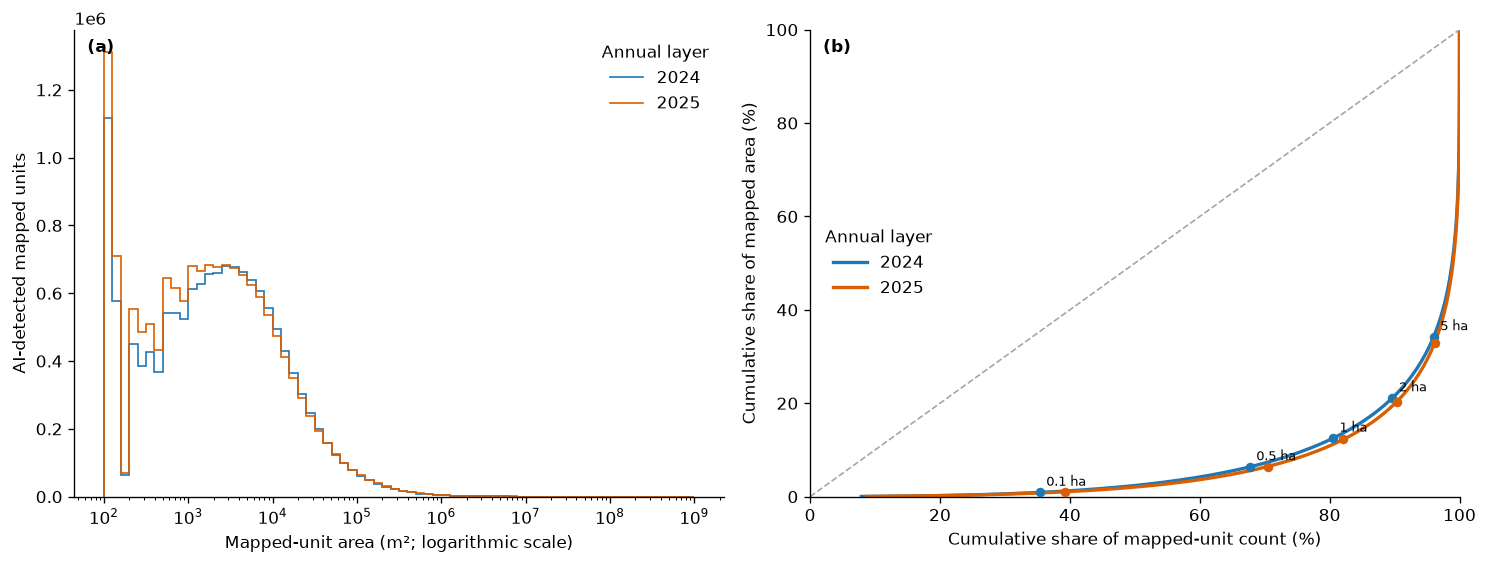

**Figure 1 interpretation.** Both layers have a strongly right-skewed mapped-unit
        area distribution. The 2024 median is 0.213 ha
        and the 2025 median is 0.174 ha,
        while 67.7% of 2024 mapped units are below 0.5 ha. The
        cumulative panel shows why mapped-unit counts and mapped area should be read together:
        small mapped units are numerous but do not necessarily dominate mapped area.

**Empirical left-edge check.** The 130–200 m² interval contains
        643,130 cleaned 2024 units
        (4.55%), while no unit has
        an area exactly equal to 100 m². The requested spike–gap interpretation is
        therefore not supported by this extract; 100 m² is retained as an exact
        histogram edge without making a pixel-quantization inference.

,section,metric,unit,2024,2025
0,National summary,Mapped units,count,1.413979e+07,1.507504e+07
1,National summary,Mapped area,ha,2.107973e+07,2.152963e+07
2,National summary,10th percentile mapped-unit area,ha,1.549817e-02,1.531176e-02
3,National summary,Median mapped-unit area,ha,2.126164e-01,1.742463e-01
4,National summary,Mean mapped-unit area,ha,1.490809e+00,1.428164e+00
5,National summary,90th percentile mapped-unit area,ha,2.069390e+00,1.926551e+00
6,National summary,Median perimeter,m,2.514829e+02,2.257482e+02
7,National summary,Median shape index,ratio,1.477800e+00,1.460782e+00
8,National summary,Mean shape index,ratio,1.637062e+00,1.620727e+00
9,Area threshold shares,Mapped-unit-count share below 0.1 ha,%,3.534141e+01,3.921578e+01


**Table 2 interpretation.** Table 2 is the numerical reference for the national distributions and area-threshold shares. It describes the delivered prediction layers and should not be interpreted as a cadastral area inventory.

In [8]:
thresholds_ha = [0.1, 0.5, 1.0, 2.0, 5.0]
threshold_expressions = []
for threshold in thresholds_ha:
    suffix = str(threshold).replace(".", "_")
    threshold_m2 = threshold * 10000.0
    threshold_expressions.extend(
        [
            f"""sum(CASE WHEN "metrics:area" < {threshold_m2} THEN 1 ELSE 0 END) AS count_lt_{suffix}""",
            f"""sum(CASE WHEN "metrics:area" < {threshold_m2} THEN "metrics:area" ELSE 0 END) AS area_lt_{suffix}""",
        ]
    )
threshold_totals = con.execute(
    f"""SELECT
        layer,
        count(*) AS field_count,
        sum("metrics:area") AS total_area_m2,
        {", ".join(threshold_expressions)}
    FROM ftw_cleaned
    GROUP BY 1
    ORDER BY 1"""
).fetchdf()

threshold_rows = []
for _, record in threshold_totals.iterrows():
    for threshold in thresholds_ha:
        suffix = str(threshold).replace(".", "_")
        threshold_rows.append(
            {
                "layer": int(record["layer"]),
                "area_threshold_ha": threshold,
                "share_of_field_count_below_pct": (
                    100 * record[f"count_lt_{suffix}"] / record["field_count"]
                ),
                "share_of_mapped_area_below_pct": (
                    100 * record[f"area_lt_{suffix}"] / record["total_area_m2"]
                ),
            }
        )
threshold_summary = pd.DataFrame(threshold_rows)
write_table(threshold_summary, "table_s_area_threshold_shares.csv")

size_band_totals = {
    int(record["layer"]): (
        int(record["field_count"]),
        float(record["total_area_m2"]) / 10_000.0,
    )
    for _, record in threshold_totals.iterrows()
}
size_band_summary = size_band_decomposition(threshold_summary, size_band_totals)
write_table(size_band_summary, "table_s_cross_layer_size_band_decomposition.csv")

# Exact national outlier-band accounting and cap sensitivity. These diagnostics
# preserve, rather than silently remove, implausibly large mapped units.
outlier_area_bands = con.execute(
    """WITH banded AS (
        SELECT
            layer,
            CASE
                WHEN "metrics:area" < 1000000 THEN '<100 ha'
                WHEN "metrics:area" < 10000000 THEN '100-<1000 ha'
                WHEN "metrics:area" < 50000000 THEN '1000-<5000 ha'
                ELSE '>=5000 ha'
            END AS area_band,
            CASE
                WHEN "metrics:area" < 1000000 THEN 1
                WHEN "metrics:area" < 10000000 THEN 2
                WHEN "metrics:area" < 50000000 THEN 3
                ELSE 4
            END AS band_order,
            "metrics:area" AS area_m2
        FROM ftw_cleaned
    ), summary AS (
        SELECT layer, area_band, band_order, count(*) AS unit_count, sum(area_m2) AS mapped_area_m2
        FROM banded GROUP BY 1, 2, 3
    )
    SELECT
        layer, area_band, band_order, unit_count, mapped_area_m2 / 10000.0 AS mapped_area_ha,
        100.0 * unit_count / sum(unit_count) OVER (PARTITION BY layer) AS unit_count_share_pct,
        100.0 * mapped_area_m2 / sum(mapped_area_m2) OVER (PARTITION BY layer)
            AS summed_mapped_area_share_pct
    FROM summary ORDER BY layer, band_order"""
).fetchdf()
write_table(outlier_area_bands, "table_s_outlier_area_bands.csv")

outlier_cap_parts = []
for cap_label, cap_m2 in [
    ('none', None),
    ('exclude >=50 ha', 500_000.0),
    ('exclude >=100 ha', 1_000_000.0),
    ('exclude >=500 ha', 5_000_000.0),
    ('exclude >=1000 ha', 10_000_000.0),
]:
    cap_filter = '' if cap_m2 is None else f'WHERE "metrics:area" < {cap_m2}'
    part = con.execute(
        f"""SELECT
            layer, '{cap_label}' AS outlier_cap,
            count(*) AS retained_unit_count,
            sum("metrics:area") / 10000.0 AS summed_mapped_area_ha,
            quantile_cont("metrics:area", 0.50) / 10000.0 AS median_unit_area_ha,
            avg("metrics:area") / 10000.0 AS mean_unit_area_ha
        FROM ftw_cleaned {cap_filter}
        GROUP BY 1 ORDER BY 1"""
    ).fetchdf()
    outlier_cap_parts.append(part)
outlier_cap_sensitivity = pd.concat(outlier_cap_parts, ignore_index=True)
uncapped = outlier_cap_sensitivity.loc[outlier_cap_sensitivity['outlier_cap'].eq('none'), [
    'layer', 'retained_unit_count', 'summed_mapped_area_ha'
]].rename(columns={
    'retained_unit_count': 'uncapped_unit_count',
    'summed_mapped_area_ha': 'uncapped_summed_mapped_area_ha',
})
outlier_cap_sensitivity = outlier_cap_sensitivity.merge(uncapped, on='layer', how='left')
outlier_cap_sensitivity['removed_unit_count'] = (
    outlier_cap_sensitivity['uncapped_unit_count'] - outlier_cap_sensitivity['retained_unit_count']
)
outlier_cap_sensitivity['summed_area_removed_pct'] = 100.0 * (
    1.0 - outlier_cap_sensitivity['summed_mapped_area_ha']
    / outlier_cap_sensitivity['uncapped_summed_mapped_area_ha']
)
write_table(outlier_cap_sensitivity, "table_s_outlier_cap_sensitivity.csv")

# Feasible topology diagnostic: within each selected 0.1-degree midpoint-assignment
# cell, compare the sum of equal-area polygon areas with their GEOS union. Ten
# highest-density and ten deterministic hash-selected occupied cells per layer are
# included. This detects local overlap and near-duplicate candidates; the exhaustive
# national unique-surface calculation below separately handles cross-cell overlap.
TOPOLOGY_HIGH_DENSITY_CELLS_PER_LAYER = 10
TOPOLOGY_HASH_CELLS_PER_LAYER = 10
topology_grid_counts = con.execute(
    f"""SELECT
        layer,
        cast(floor(((bbox.xmin + bbox.xmax) / 2.0) / {GRID_CELL_DEGREES}) AS INTEGER)
            AS longitude_index,
        cast(floor(((bbox.ymin + bbox.ymax) / 2.0) / {GRID_CELL_DEGREES}) AS INTEGER)
            AS latitude_index,
        count(*) AS unit_count
    FROM ftw_cleaned
    GROUP BY 1, 2, 3"""
).fetchdf()
selected_topology_parts = []
for layer, frame in topology_grid_counts.groupby('layer'):
    frame = frame.copy()
    frame['selection_hash'] = [
        hashlib.sha256(f'{SEED}|{int(layer)}|{int(x)}|{int(y)}'.encode()).hexdigest()
        for x, y in zip(frame['longitude_index'], frame['latitude_index'])
    ]
    dense = frame.sort_values(
        ['unit_count', 'selection_hash'],
        ascending=[False, True],
        kind='mergesort',
    ).head(TOPOLOGY_HIGH_DENSITY_CELLS_PER_LAYER).copy()
    dense['sample_stratum'] = 'highest_density'
    random_pool = frame.loc[~frame.index.isin(dense.index)].sort_values('selection_hash')
    hashed = random_pool.head(TOPOLOGY_HASH_CELLS_PER_LAYER).copy()
    hashed['sample_stratum'] = 'deterministic_hash'
    selected_topology_parts.extend([dense, hashed])
selected_topology_cells = pd.concat(selected_topology_parts, ignore_index=True)

topology_records = []
for selected_cell in selected_topology_cells.itertuples(index=False):
    layer = int(selected_cell.layer)
    longitude_index = int(selected_cell.longitude_index)
    latitude_index = int(selected_cell.latitude_index)
    cell_filter = f"""layer = {layer}
        AND cast(floor(((bbox.xmin + bbox.xmax) / 2.0) / {GRID_CELL_DEGREES}) AS INTEGER)
            = {longitude_index}
        AND cast(floor(((bbox.ymin + bbox.ymax) / 2.0) / {GRID_CELL_DEGREES}) AS INTEGER)
            = {latitude_index}"""
    overlap = con.execute(
        f"""WITH selected AS (
            SELECT geometry, "metrics:area" AS provider_area_m2
            FROM ftw_cleaned WHERE {cell_filter}
        ), projected AS (
            SELECT provider_area_m2,
                ST_Transform(geometry, 'EPSG:4326', 'EPSG:6933', always_xy := true) AS geometry_6933
            FROM selected
        )
        SELECT
            count(*) AS unit_count,
            sum(provider_area_m2) AS summed_provider_area_m2,
            sum(ST_Area(geometry_6933)) AS summed_equal_area_m2,
            ST_Area(ST_Union_Agg(geometry_6933)) AS union_equal_area_m2
        FROM projected"""
    ).fetchdf().iloc[0]
    near_duplicate = con.execute(
        f"""WITH selected AS (
            SELECT
                row_number() OVER (
                    ORDER BY md5(cast(id AS VARCHAR)), id, md5(ST_AsWKB(geometry))
                ) AS row_number,
                "metrics:area" AS provider_area_m2,
                round((bbox.xmin + bbox.xmax) / 2.0, 5) AS rounded_center_x,
                round((bbox.ymin + bbox.ymax) / 2.0, 5) AS rounded_center_y,
                ST_Transform(geometry, 'EPSG:4326', 'EPSG:6933', always_xy := true) AS geometry_6933
            FROM ftw_cleaned WHERE {cell_filter}
        ), candidates AS (
            SELECT
                a.geometry_6933 AS geometry_a,
                b.geometry_6933 AS geometry_b,
                ST_Area(a.geometry_6933) AS area_a,
                ST_Area(b.geometry_6933) AS area_b
            FROM selected AS a
            JOIN selected AS b
              ON a.row_number < b.row_number
             AND a.rounded_center_x = b.rounded_center_x
             AND a.rounded_center_y = b.rounded_center_y
             AND b.provider_area_m2 / a.provider_area_m2 BETWEEN 0.95 AND 1.05
        ), measured AS (
            SELECT *, ST_Area(ST_Intersection(geometry_a, geometry_b)) AS intersection_area_m2
            FROM candidates
        )
        SELECT
            count(*) AS candidate_pair_count,
            coalesce(sum(CASE WHEN intersection_area_m2 /
                nullif(area_a + area_b - intersection_area_m2, 0.0) >= 0.95
                THEN 1 ELSE 0 END), 0) AS confirmed_near_duplicate_pair_count
        FROM measured"""
    ).fetchdf().iloc[0]
    summed_equal_area_m2 = float(overlap['summed_equal_area_m2'])
    union_equal_area_m2 = float(overlap['union_equal_area_m2'])
    topology_records.append({
        'layer': layer,
        'sample_stratum': selected_cell.sample_stratum,
        'longitude_index': longitude_index,
        'latitude_index': latitude_index,
        'longitude_min': longitude_index * GRID_CELL_DEGREES,
        'latitude_min': latitude_index * GRID_CELL_DEGREES,
        'grid_cell_degrees': GRID_CELL_DEGREES,
        'unit_count': int(overlap['unit_count']),
        'summed_provider_area_m2': float(overlap['summed_provider_area_m2']),
        'summed_equal_area_m2': summed_equal_area_m2,
        'union_equal_area_m2': union_equal_area_m2,
        'summed_minus_union_m2': summed_equal_area_m2 - union_equal_area_m2,
        'within_cell_overlap_excess_pct_of_sum': max(
            0.0, 100.0 * (summed_equal_area_m2 - union_equal_area_m2) / summed_equal_area_m2
        ),
        'near_duplicate_candidate_pair_count': int(near_duplicate['candidate_pair_count']),
        'confirmed_near_duplicate_pair_count': int(near_duplicate['confirmed_near_duplicate_pair_count']),
        'grid_assignment_rule': (
            'polygon bounding-box midpoint; half-open 0.1-degree bins anchored at (0,0)'
        ),
        'near_duplicate_screen': (
            'centres equal after 5-decimal rounding and provider areas within 5%; confirmed by EPSG:6933 Jaccard >=0.95'
        ),
    })
topology_sample_cells = pd.DataFrame(topology_records)
write_table(topology_sample_cells, 'table_s_topology_sample_cells.csv')
topology_summary_rows = []
for (layer, stratum), frame in topology_sample_cells.groupby(['layer', 'sample_stratum']):
    summed_area = frame['summed_equal_area_m2'].sum()
    union_area = frame['union_equal_area_m2'].sum()
    topology_summary_rows.append({
        'layer': int(layer),
        'sample_stratum': stratum,
        'sampled_cell_count': len(frame),
        'sampled_unit_count': int(frame['unit_count'].sum()),
        'summed_equal_area_m2': summed_area,
        'union_equal_area_m2': union_area,
        'within_cell_overlap_excess_pct_of_sum': max(0.0, 100.0 * (summed_area - union_area) / summed_area),
        'near_duplicate_candidate_pair_count': int(frame['near_duplicate_candidate_pair_count'].sum()),
        'confirmed_near_duplicate_pair_count': int(frame['confirmed_near_duplicate_pair_count'].sum()),
        'scope_limit': 'Selected-cell diagnostic for local concentration and near-duplicates; see the separate exhaustive tiled national union',
    })
topology_summary = pd.DataFrame(topology_summary_rows)
write_table(topology_summary, 'table_s_topology_overlap_near_duplicate_summary.csv')


# The provider bbox drives tile expansion below, so it is first required to equal
# the actual geometry envelope for every retained record.
bbox_geometry_consistency = con.execute(
    """SELECT
        layer,
        count(*) AS unit_count,
        sum(CASE WHEN
            ST_XMin(geometry) != bbox.xmin OR ST_YMin(geometry) != bbox.ymin OR
            ST_XMax(geometry) != bbox.xmax OR ST_YMax(geometry) != bbox.ymax
            THEN 1 ELSE 0 END) AS bbox_geometry_mismatch_count,
        max(abs(ST_XMin(geometry) - bbox.xmin)) AS maximum_xmin_difference_degrees,
        max(abs(ST_YMin(geometry) - bbox.ymin)) AS maximum_ymin_difference_degrees,
        max(abs(ST_XMax(geometry) - bbox.xmax)) AS maximum_xmax_difference_degrees,
        max(abs(ST_YMax(geometry) - bbox.ymax)) AS maximum_ymax_difference_degrees
    FROM ftw_cleaned
    GROUP BY 1 ORDER BY 1"""
).fetchdf()
assert bbox_geometry_consistency["bbox_geometry_mismatch_count"].eq(0).all(), (
    "Provider bbox differs from actual geometry envelope; tiled union would be unsafe"
)
bbox_geometry_consistency["tiled_union_use"] = (
    "Verified exact geometry envelope used to enumerate all intersected 0.1-degree tiles"
)
write_table(bbox_geometry_consistency, "table_s_bbox_geometry_consistency.csv")

# Exhaustive national unique mapped surface. Every geometry is expanded into all
# intersected non-overlapping 0.1-degree tiles from its bounding box, clipped to
# each tile, unioned within the tile, and measured spheroidally. Shared tile edges
# have zero area, so summing tile unions measures the national union without ever
# materialising one unbounded national geometry.
national_union_tile_parts = []
for union_layer in (2024, 2025):
    print(f"Computing exact tiled national union for {union_layer}...")
    union_tiles = con.execute(
        f"""WITH expanded AS (
            SELECT
                field.layer,
                field.geometry,
                x.tile_longitude_index,
                y.tile_latitude_index
            FROM ftw_cleaned AS field
            CROSS JOIN LATERAL range(
                cast(floor(field.bbox.xmin / {NATIONAL_UNION_TILE_DEGREES}) AS BIGINT),
                cast(floor(field.bbox.xmax / {NATIONAL_UNION_TILE_DEGREES}) AS BIGINT) + 1
            ) AS x(tile_longitude_index)
            CROSS JOIN LATERAL range(
                cast(floor(field.bbox.ymin / {NATIONAL_UNION_TILE_DEGREES}) AS BIGINT),
                cast(floor(field.bbox.ymax / {NATIONAL_UNION_TILE_DEGREES}) AS BIGINT) + 1
            ) AS y(tile_latitude_index)
            WHERE field.layer = {union_layer}
        ), clipped AS (
            SELECT
                layer,
                tile_longitude_index,
                tile_latitude_index,
                ST_Intersection(
                    geometry,
                    ST_MakeEnvelope(
                        tile_longitude_index * {NATIONAL_UNION_TILE_DEGREES},
                        tile_latitude_index * {NATIONAL_UNION_TILE_DEGREES},
                        (tile_longitude_index + 1) * {NATIONAL_UNION_TILE_DEGREES},
                        (tile_latitude_index + 1) * {NATIONAL_UNION_TILE_DEGREES}
                    )
                ) AS geometry_piece
            FROM expanded
            WHERE ST_Intersects(
                geometry,
                ST_MakeEnvelope(
                    tile_longitude_index * {NATIONAL_UNION_TILE_DEGREES},
                    tile_latitude_index * {NATIONAL_UNION_TILE_DEGREES},
                    (tile_longitude_index + 1) * {NATIONAL_UNION_TILE_DEGREES},
                    (tile_latitude_index + 1) * {NATIONAL_UNION_TILE_DEGREES}
                )
            )
        ), tile_unions AS (
            SELECT
                layer,
                tile_longitude_index,
                tile_latitude_index,
                count(*) AS clipped_piece_count,
                sum(ST_Area_Spheroid(ST_FlipCoordinates(geometry_piece)))
                    AS summed_clipped_spheroid_area_m2,
                ST_Union_Agg(geometry_piece) AS union_geometry
            FROM clipped
            WHERE NOT ST_IsEmpty(geometry_piece) AND ST_Area(geometry_piece) > 0
            GROUP BY 1, 2, 3
        )
        SELECT
            layer,
            tile_longitude_index,
            tile_latitude_index,
            tile_longitude_index * {NATIONAL_UNION_TILE_DEGREES} AS tile_longitude_min,
            tile_latitude_index * {NATIONAL_UNION_TILE_DEGREES} AS tile_latitude_min,
            {NATIONAL_UNION_TILE_DEGREES}::DOUBLE AS tile_degrees,
            clipped_piece_count,
            summed_clipped_spheroid_area_m2,
            ST_Area_Spheroid(ST_FlipCoordinates(union_geometry))
                AS unique_mapped_surface_m2
        FROM tile_unions
        ORDER BY layer, tile_latitude_index, tile_longitude_index"""
    ).fetchdf()
    union_tiles["summed_minus_union_m2"] = (
        union_tiles["summed_clipped_spheroid_area_m2"]
        - union_tiles["unique_mapped_surface_m2"]
    )
    national_union_tile_parts.append(union_tiles)

national_union_tiles = pd.concat(national_union_tile_parts, ignore_index=True)
write_table(national_union_tiles, "table_s_national_union_overlap_by_tile.csv")

national_union_rows = []
for union_layer, union_tiles in national_union_tiles.groupby("layer", sort=True):
    remeasured_sum_m2 = float(union_tiles["summed_clipped_spheroid_area_m2"].sum())
    unique_surface_m2 = float(union_tiles["unique_mapped_surface_m2"].sum())
    overlap_excess_m2 = remeasured_sum_m2 - unique_surface_m2
    numerical_tolerance_m2 = max(1.0, remeasured_sum_m2 * 1e-8)
    assert overlap_excess_m2 >= -numerical_tolerance_m2
    provider_sum_m2 = float(
        threshold_totals.loc[threshold_totals["layer"].eq(union_layer), "total_area_m2"].iloc[0]
    )
    national_union_rows.append({
        "layer": int(union_layer),
        "tile_degrees": NATIONAL_UNION_TILE_DEGREES,
        "nonempty_tile_count": len(union_tiles),
        "clipped_piece_count": int(union_tiles["clipped_piece_count"].sum()),
        "provider_summed_polygon_area_ha": provider_sum_m2 / 10000.0,
        "remeasured_summed_clipped_spheroid_area_ha": remeasured_sum_m2 / 10000.0,
        "exact_unique_mapped_surface_ha": unique_surface_m2 / 10000.0,
        "spheroid_overlap_excess_ha": max(0.0, overlap_excess_m2) / 10000.0,
        "spheroid_overlap_excess_pct_of_remeasured_sum": (
            100.0 * max(0.0, overlap_excess_m2) / remeasured_sum_m2
        ),
        "provider_sum_minus_unique_surface_ha": (provider_sum_m2 - unique_surface_m2) / 10000.0,
        "method": (
            "all polygons bbox-expanded, clipped and GEOS-unioned within non-overlapping "
            "0.1-degree tiles; tile unions measured with ST_Area_Spheroid after coordinate flip"
        ),
        "interpretation": (
            "unique mapped surface is a geometric product property; it is not validated "
            "agricultural coverage"
        ),
    })
national_union_overlap = pd.DataFrame(national_union_rows)
write_table(national_union_overlap, "table_s_national_union_overlap.csv")

display(outlier_area_bands)
display(outlier_cap_sensitivity)
display(topology_summary)
display(national_union_overlap)

cumulative_bin_count = 300
cumulative_bin_width = (histogram_log_max - histogram_log_min) / cumulative_bin_count
cumulative_bins = con.execute(
    f"""SELECT
        layer,
        least(
            {cumulative_bin_count - 1},
            greatest(
                0,
                cast(floor((log10("metrics:area") - {histogram_log_min}) / {cumulative_bin_width}) AS INTEGER)
            )
        ) AS bin_index,
        count(*) AS field_count,
        sum("metrics:area") AS mapped_area_m2
    FROM ftw_cleaned
    GROUP BY 1, 2
    ORDER BY 1, 2"""
).fetchdf()
write_table(cumulative_bins, "table_s3_cumulative_area_bins.csv")

summary_specs = [
    ("Mapped units", "count", "field_count"),
    ("Mapped area", "ha", "total_mapped_area_ha"),
    ("10th percentile mapped-unit area", "ha", "p10_field_area_ha"),
    ("Median mapped-unit area", "ha", "median_field_area_ha"),
    ("Mean mapped-unit area", "ha", "mean_field_area_ha"),
    ("90th percentile mapped-unit area", "ha", "p90_field_area_ha"),
    ("Median perimeter", "m", "median_perimeter_m"),
    ("Median shape index", "ratio", "median_shape_index"),
    ("Mean shape index", "ratio", "mean_shape_index"),
]
table_2_rows = []
for metric, unit, column in summary_specs:
    row = {"section": "National summary", "metric": metric, "unit": unit}
    for layer in (2024, 2025):
        row[str(layer)] = national_summary.loc[
            national_summary["layer"].eq(layer), column
        ].iloc[0]
    table_2_rows.append(row)
for threshold in thresholds_ha:
    for metric, column in [
        ("Mapped-unit-count share below", "share_of_field_count_below_pct"),
        ("Mapped-area share below", "share_of_mapped_area_below_pct"),
    ]:
        row = {
            "section": "Area threshold shares",
            "metric": f"{metric} {threshold:g} ha",
            "unit": "%",
        }
        for layer in (2024, 2025):
            row[str(layer)] = threshold_summary.loc[
                threshold_summary["layer"].eq(layer)
                & threshold_summary["area_threshold_ha"].eq(threshold),
                column,
            ].iloc[0]
        table_2_rows.append(row)
large_area_threshold_ha = thresholds_ha[-1]
for metric, column in [
    ("Mapped-unit-count share at or above", "share_of_field_count_below_pct"),
    ("Mapped-area share at or above", "share_of_mapped_area_below_pct"),
]:
    row = {
        "section": "Area threshold shares",
        "metric": f"{metric} {large_area_threshold_ha:g} ha",
        "unit": "%",
    }
    for layer in (2024, 2025):
        below_share = threshold_summary.loc[
            threshold_summary["layer"].eq(layer)
            & threshold_summary["area_threshold_ha"].eq(large_area_threshold_ha),
            column,
        ].iloc[0]
        row[str(layer)] = 100.0 - below_share
    table_2_rows.append(row)
table_2 = pd.DataFrame(table_2_rows)
write_table(table_2, "table_2_national_summary_2024_2025.csv")

figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
colours = {2024: "#1f77b4", 2025: "#d95f02"}
axis = axes[0]
for layer in sorted(histogram["layer"].unique()):
    counts = (
        histogram.loc[histogram["layer"].eq(layer)]
        .set_index("bin_index")["field_count"]
        .reindex(range(histogram_bin_count), fill_value=0)
        .to_numpy()
    )
    axis.stairs(counts, histogram_edges, label=str(layer), color=colours.get(layer))
axis.set_xscale("log")
axis.set_xlabel("Mapped-unit area (m²; logarithmic scale)")
axis.set_ylabel("AI-detected mapped units")
axis.legend(title="Annual layer", frameon=False)
axis.text(0.02, 0.98, "(a)", transform=axis.transAxes, va="top", fontweight="bold")

axis = axes[1]
for layer in sorted(cumulative_bins["layer"].unique()):
    frame = cumulative_bins.loc[cumulative_bins["layer"].eq(layer)].sort_values("bin_index").copy()
    frame["count_share_pct"] = 100 * frame["field_count"].cumsum() / frame["field_count"].sum()
    frame["area_share_pct"] = 100 * frame["mapped_area_m2"].cumsum() / frame["mapped_area_m2"].sum()
    axis.plot(
        frame["count_share_pct"],
        frame["area_share_pct"],
        linewidth=2,
        color=colours.get(layer),
        label=str(layer),
    )
for threshold in thresholds_ha:
    for layer in sorted(threshold_summary["layer"].unique()):
        marker_row = threshold_summary.loc[
            threshold_summary["layer"].eq(layer)
            & threshold_summary["area_threshold_ha"].eq(threshold)
        ].iloc[0]
        axis.scatter(
            marker_row["share_of_field_count_below_pct"],
            marker_row["share_of_mapped_area_below_pct"],
            s=22,
            color=colours.get(layer),
            zorder=3,
        )
        if layer == 2024:
            axis.annotate(
                f"{threshold:g} ha",
                (
                    marker_row["share_of_field_count_below_pct"],
                    marker_row["share_of_mapped_area_below_pct"],
                ),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=8,
            )
axis.plot([0, 100], [0, 100], color="0.65", linestyle="--", linewidth=1)
axis.set_xlim(0, 100)
axis.set_ylim(0, 100)
axis.set_xlabel("Cumulative share of mapped-unit count (%)")
axis.set_ylabel("Cumulative share of mapped area (%)")
axis.legend(title="Annual layer", frameon=False)
axis.text(0.02, 0.98, "(b)", transform=axis.transAxes, va="top", fontweight="bold")
figure.tight_layout()
save_figure(figure, "fig_1_national_area_distribution")

national_2024_figure = national_summary.loc[national_summary["layer"].eq(2024)].iloc[0]
national_2025_figure = national_summary.loc[national_summary["layer"].eq(2025)].iloc[0]
half_hectare_threshold = thresholds_ha[1]
half_hectare_2024 = threshold_summary.loc[
    threshold_summary["layer"].eq(2024)
    & threshold_summary["area_threshold_ha"].eq(half_hectare_threshold),
    "share_of_field_count_below_pct",
].iloc[0]
display(
    Markdown(
        f"""**Figure 1 interpretation.** Both layers have a strongly right-skewed mapped-unit
        area distribution. The 2024 median is {float(national_2024_figure['median_field_area_ha']):.3f} ha
        and the 2025 median is {float(national_2025_figure['median_field_area_ha']):.3f} ha,
        while {float(half_hectare_2024):.1f}% of 2024 mapped units are below {half_hectare_threshold:g} ha. The
        cumulative panel shows why mapped-unit counts and mapped area should be read together:
        small mapped units are numerous but do not necessarily dominate mapped area."""
    )
)

quantization_2024 = area_quantization_check.loc[
    area_quantization_check["layer"].eq(2024)
].iloc[0]
display(
    Markdown(
        f"""**Empirical left-edge check.** The 130–200 m² interval contains
        {int(quantization_2024['count_130_to_200m2']):,} cleaned 2024 units
        ({float(quantization_2024['share_130_to_200m2_pct']):.2f}%), while no unit has
        an area exactly equal to 100 m². The requested spike–gap interpretation is
        therefore not supported by this extract; 100 m² is retained as an exact
        histogram edge without making a pixel-quantization inference."""
    )
)
display(table_2)

display(
    Markdown(
        "**Table 2 interpretation.** Table 2 is the numerical reference for the national "
        "distributions and area-threshold shares. It describes the delivered prediction "
        "layers and should not be interpreted as a cadastral area inventory."
    )
)


## Subdivision-code reconciliation, province denominators and regional provenance

Province metrics use only reconciled Turkish province codes. HGM's 2026 province-area
workbook supplies the reproducible density denominator, while Natural Earth is retained
for display and a denominator-sensitivity comparison. The seven-region crosswalk is an
analytical convention rather than an administrative classification.


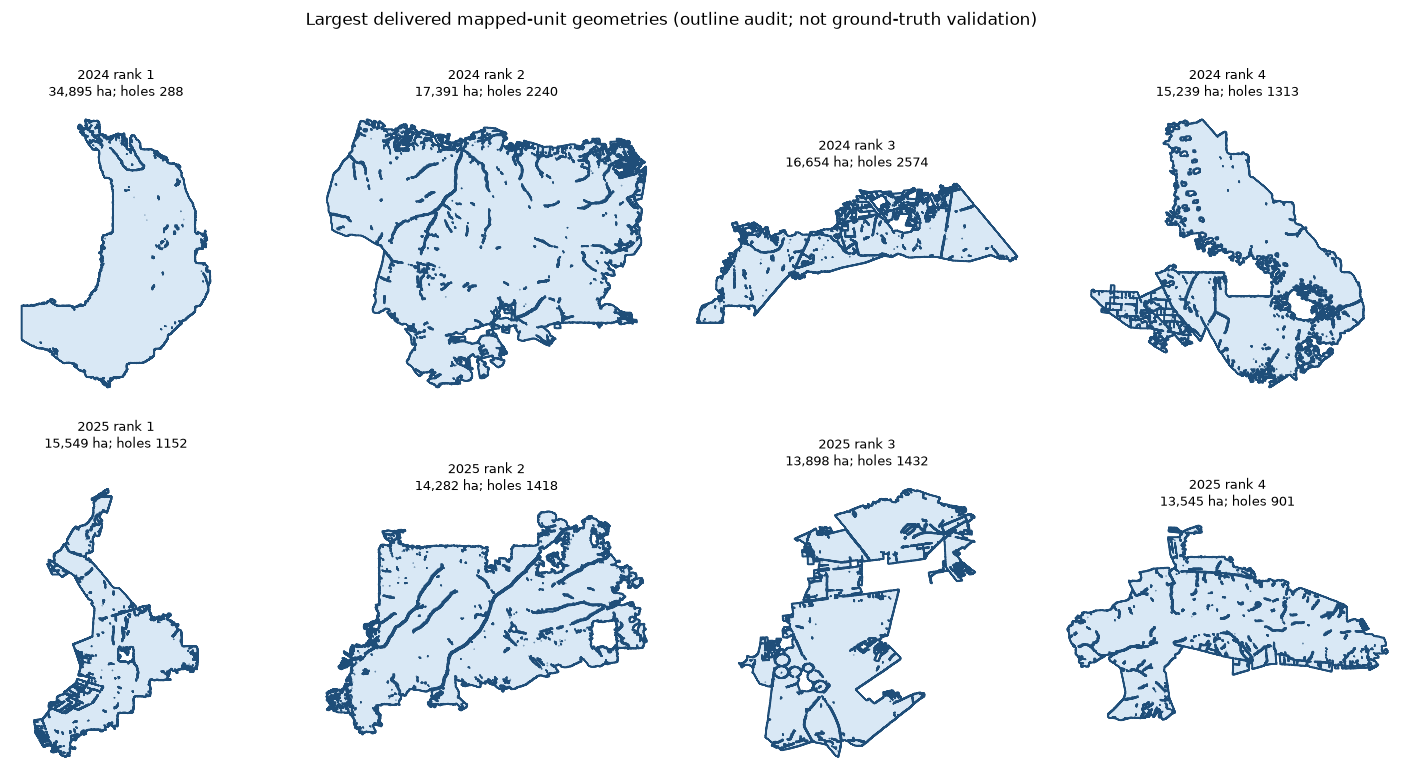

**Outside-Türkiye 2024 records excluded after cleaning:** 12

**Top 10 provinces by median mapped-unit area (2024)**

,province_code,province_name,geographical_region,natural_earth_name,hgm_province_name,hgm_geometry_province_name,hgm_area_km2,hgm_geometry_area_km2,natural_earth_area_km2,denominator_source,official_status,field_count,total_mapped_area_ha,median_field_area_ha,share_fields_lt_1ha_pct,mean_shape_index,field_density_per_km2
39,40,Kırşehir,Central Anatolia,Kirsehir,KIRŞEHİR,Kırşehir,6582.0,6580.858443,6371.496037,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,105059,4.346625e+05,0.695645,57.059367,1.805852,15.961562
62,63,Şanlıurfa,Southeastern Anatolia,Sanliurfa,ŞANLIURFA,Şanlıurfa,19225.0,19226.142853,19934.823659,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,199080,1.299823e+06,0.652201,57.287020,1.799381,10.355267
21,22,Edirne,Marmara,Edirne,EDİRNE,Edirne,6149.0,6149.690459,5370.294836,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,181834,3.377866e+05,0.580230,64.235512,1.758549,29.571312
68,69,Bayburt,Black Sea,Bayburt,BAYBURT,Bayburt,3746.0,3745.851283,3541.500181,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,51967,8.364695e+04,0.543514,65.485789,1.690253,13.872664
3,04,Ağrı,Eastern Anatolia,Agri,AĞRI,Ağrı,11095.0,11095.341250,10013.440595,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,113964,3.065607e+05,0.537594,63.138359,1.748245,10.271654
0,01,Adana,Mediterranean,Adana,ADANA,Adana,13847.0,13846.675096,15351.343505,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,155203,4.395147e+05,0.524396,62.154082,1.744403,11.208421
79,80,Osmaniye,Mediterranean,Osmaniye,OSMANİYE,Osmaniye,3316.0,3316.319981,2910.610683,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,50447,8.686380e+04,0.485115,67.589748,1.709184,15.213209
58,59,Tekirdağ,Marmara,Tekirdag,TEKİRDAĞ,Tekirdağ,6228.0,6228.493605,6993.870928,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,166345,3.512816e+05,0.449656,66.830383,1.785564,26.709216
35,36,Kars,Eastern Anatolia,Kars,KARS,Kars,10200.0,10199.498722,10510.941370,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,145460,3.084559e+05,0.449244,67.887392,1.791228,14.260784
67,68,Aksaray,Central Anatolia,Aksaray,AKSARAY,Aksaray,7671.0,7671.718030,7758.964403,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,110209,5.023209e+05,0.446775,64.841347,1.780042,14.366966


**Bottom 10 provinces by median mapped-unit area (2024)**

,province_code,province_name,geographical_region,natural_earth_name,hgm_province_name,hgm_geometry_province_name,hgm_area_km2,hgm_geometry_area_km2,natural_earth_area_km2,denominator_source,official_status,field_count,total_mapped_area_ha,median_field_area_ha,share_fields_lt_1ha_pct,mean_shape_index,field_density_per_km2
11,12,Bingöl,Eastern Anatolia,Bingöl,BİNGÖL,Bingöl,8015.0,8014.798933,8426.080300,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,98064,33451.552308,0.054171,95.173560,1.437700,12.235059
61,62,Tunceli,Eastern Anatolia,Tunceli,TUNCELİ,Tunceli,7590.0,7589.714782,7902.552179,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,152200,57644.937402,0.062153,93.917871,1.474548,20.052701
29,30,Hakkâri,Eastern Anatolia,Hakkari,HAKKÂRİ,Hakkâri,7094.0,7095.110994,7469.401110,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,10469,7631.829911,0.063688,92.291527,1.455673,1.475754
27,28,Giresun,Black Sea,Giresun,GİRESUN,Giresun,6977.0,6979.080922,6763.997666,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,59233,11798.034480,0.068588,96.888559,1.442117,8.489752
60,61,Trabzon,Black Sea,Trabzon,TRABZON,Trabzon,4627.0,4626.027832,5006.485553,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,1715,283.720938,0.075576,98.250729,1.447487,0.370651
40,41,Kocaeli,Marmara,Kocaeli,KOCAELİ,Kocaeli,3423.0,3424.489333,3989.218720,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,92758,22170.715129,0.097874,95.758856,1.506389,27.098452
22,23,Elazığ,Eastern Anatolia,Elazig,ELAZIĞ,Elazığ,9339.0,9338.938706,9304.210520,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,305929,202715.384837,0.101605,88.734314,1.543493,32.758218
73,74,Bartın,Black Sea,Bartın,BARTIN,Bartın,2329.0,2329.313574,2105.497573,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,3154,826.864208,0.104546,95.244134,1.467941,1.354229
43,44,Malatya,Eastern Anatolia,Malatya,MALATYA,Malatya,12282.0,12280.837060,11831.362082,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,326211,348257.769253,0.108748,87.227899,1.552919,26.560088
1,02,Adıyaman,Southeastern Anatolia,Adiyaman,ADIYAMAN,Adıyaman,7351.0,7350.919328,7170.966853,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,229866,211394.481009,0.125822,85.516779,1.564570,31.270031


,province_code,province_name,geographical_region,natural_earth_name,hgm_province_name,hgm_geometry_province_name,hgm_area_km2,hgm_geometry_area_km2,natural_earth_area_km2,denominator_source,official_status,field_count,total_mapped_area_ha,median_field_area_ha,share_fields_lt_1ha_pct,mean_shape_index,field_density_per_km2
0,01,Adana,Mediterranean,Adana,ADANA,Adana,13847.0,13846.675096,15351.343505,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,155203,439514.721490,0.524396,62.154082,1.744403,11.208421
1,02,Adıyaman,Southeastern Anatolia,Adiyaman,ADIYAMAN,Adıyaman,7351.0,7350.919328,7170.966853,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,229866,211394.481009,0.125822,85.516779,1.564570,31.270031
2,03,Afyonkarahisar,Aegean,Afyonkarahisar,AFYONKARAHİSAR,Afyonkarahisar,14016.0,14016.069864,14758.147964,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,441090,596613.592867,0.257076,81.350291,1.651812,31.470462
3,04,Ağrı,Eastern Anatolia,Agri,AĞRI,Ağrı,11095.0,11095.341250,10013.440595,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,113964,306560.661688,0.537594,63.138359,1.748245,10.271654
4,05,Amasya,Black Sea,Amasya,AMASYA,Amasya,5672.0,5672.307192,6226.390388,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,185348,133131.003548,0.196548,85.788894,1.600706,32.677715
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,77,Yalova,Marmara,Yalova,YALOVA,Yalova,799.0,798.063487,687.714979,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,7159,4004.757194,0.219818,86.143316,1.574844,8.959950
77,78,Karabük,Black Sea,Karabük,KARABÜK,Karabük,4145.0,4145.870158,3965.372648,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,31825,20580.828449,0.240051,84.449332,1.621490,7.677925
78,79,Kilis,Southeastern Anatolia,Kilis,KİLİS,Kilis,1413.0,1412.020339,1352.265342,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,59210,87276.904552,0.280117,77.546023,1.669408,41.903751
79,80,Osmaniye,Mediterranean,Osmaniye,OSMANİYE,Osmaniye,3316.0,3316.319981,2910.610683,"Harita Genel Müdürlüğü 2026 1:1,000,000 admini...",Indicative and reproducible HGM estimate; HGM ...,50447,86863.798017,0.485115,67.589748,1.709184,15.213209


**Table 3 interpretation.** Province patterns are heterogeneous. The largest
        province median is 0.696 ha in
        Kırşehir. Şanlıurfa has a median of
        0.652 ha and ranks
        2 among provinces with mapped units. There are
        1 zero-count provinces in the 2024 HGM-assigned layer
        (Rize). FTW targets
        seasonal/annual-crop mapped units and excludes perennial/tree crops, pasture and
        orchards. Zero or low mapped-unit counts therefore cannot be interpreted as the
        absence of agriculture, and no causal terrain, cloud or land-use explanation is
        tested here.

In [9]:
province_lookup = pd.DataFrame(
    [
        ("01", "Adana", "Mediterranean"),
        ("02", "Adıyaman", "Southeastern Anatolia"),
        ("03", "Afyonkarahisar", "Aegean"),
        ("04", "Ağrı", "Eastern Anatolia"),
        ("05", "Amasya", "Black Sea"),
        ("06", "Ankara", "Central Anatolia"),
        ("07", "Antalya", "Mediterranean"),
        ("08", "Artvin", "Black Sea"),
        ("09", "Aydın", "Aegean"),
        ("10", "Balıkesir", "Marmara"),
        ("11", "Bilecik", "Marmara"),
        ("12", "Bingöl", "Eastern Anatolia"),
        ("13", "Bitlis", "Eastern Anatolia"),
        ("14", "Bolu", "Black Sea"),
        ("15", "Burdur", "Mediterranean"),
        ("16", "Bursa", "Marmara"),
        ("17", "Çanakkale", "Marmara"),
        ("18", "Çankırı", "Central Anatolia"),
        ("19", "Çorum", "Black Sea"),
        ("20", "Denizli", "Aegean"),
        ("21", "Diyarbakır", "Southeastern Anatolia"),
        ("22", "Edirne", "Marmara"),
        ("23", "Elazığ", "Eastern Anatolia"),
        ("24", "Erzincan", "Eastern Anatolia"),
        ("25", "Erzurum", "Eastern Anatolia"),
        ("26", "Eskişehir", "Central Anatolia"),
        ("27", "Gaziantep", "Southeastern Anatolia"),
        ("28", "Giresun", "Black Sea"),
        ("29", "Gümüşhane", "Black Sea"),
        ("30", "Hakkâri", "Eastern Anatolia"),
        ("31", "Hatay", "Mediterranean"),
        ("32", "Isparta", "Mediterranean"),
        ("33", "Mersin", "Mediterranean"),
        ("34", "İstanbul", "Marmara"),
        ("35", "İzmir", "Aegean"),
        ("36", "Kars", "Eastern Anatolia"),
        ("37", "Kastamonu", "Black Sea"),
        ("38", "Kayseri", "Central Anatolia"),
        ("39", "Kırklareli", "Marmara"),
        ("40", "Kırşehir", "Central Anatolia"),
        ("41", "Kocaeli", "Marmara"),
        ("42", "Konya", "Central Anatolia"),
        ("43", "Kütahya", "Aegean"),
        ("44", "Malatya", "Eastern Anatolia"),
        ("45", "Manisa", "Aegean"),
        ("46", "Kahramanmaraş", "Mediterranean"),
        ("47", "Mardin", "Southeastern Anatolia"),
        ("48", "Muğla", "Aegean"),
        ("49", "Muş", "Eastern Anatolia"),
        ("50", "Nevşehir", "Central Anatolia"),
        ("51", "Niğde", "Central Anatolia"),
        ("52", "Ordu", "Black Sea"),
        ("53", "Rize", "Black Sea"),
        ("54", "Sakarya", "Marmara"),
        ("55", "Samsun", "Black Sea"),
        ("56", "Siirt", "Southeastern Anatolia"),
        ("57", "Sinop", "Black Sea"),
        ("58", "Sivas", "Central Anatolia"),
        ("59", "Tekirdağ", "Marmara"),
        ("60", "Tokat", "Black Sea"),
        ("61", "Trabzon", "Black Sea"),
        ("62", "Tunceli", "Eastern Anatolia"),
        ("63", "Şanlıurfa", "Southeastern Anatolia"),
        ("64", "Uşak", "Aegean"),
        ("65", "Van", "Eastern Anatolia"),
        ("66", "Yozgat", "Central Anatolia"),
        ("67", "Zonguldak", "Black Sea"),
        ("68", "Aksaray", "Central Anatolia"),
        ("69", "Bayburt", "Black Sea"),
        ("70", "Karaman", "Central Anatolia"),
        ("71", "Kırıkkale", "Central Anatolia"),
        ("72", "Batman", "Southeastern Anatolia"),
        ("73", "Şırnak", "Southeastern Anatolia"),
        ("74", "Bartın", "Black Sea"),
        ("75", "Ardahan", "Eastern Anatolia"),
        ("76", "Iğdır", "Eastern Anatolia"),
        ("77", "Yalova", "Marmara"),
        ("78", "Karabük", "Black Sea"),
        ("79", "Kilis", "Southeastern Anatolia"),
        ("80", "Osmaniye", "Mediterranean"),
        ("81", "Düzce", "Black Sea"),
    ],
    columns=["province_code", "province_name", "geographical_region"],
)
assert len(province_lookup) == 81
assert province_lookup["province_code"].is_unique
assert province_lookup['province_name'].is_unique
assert province_lookup['geographical_region'].nunique() == 7
write_table(province_lookup, "table_s4_province_lookup.csv")
region_crosswalk = province_lookup.copy()
region_crosswalk['classification'] = 'Seven geographical regions of Türkiye'
region_crosswalk['assignment_basis'] = (
    'Author-compiled province crosswalk to the conventional predominant geographical region'
)
region_crosswalk['administrative_status'] = 'Analytical convention; not an administrative classification'
region_crosswalk['historical_basis'] = 'Seven-region division associated with the 1941 First Geography Congress'
region_crosswalk['provenance_url'] = REGION_PROVENANCE_URL
region_crosswalk['access_date'] = ACCESS_DATE
assert region_crosswalk.groupby('province_code').size().eq(1).all()
write_table(region_crosswalk, 'table_s_region_crosswalk.csv')

def ensure_natural_earth_provinces() -> None:
    # Create the compact Natural Earth Türkiye Admin-1 extract if it is absent.
    if NE_PROVINCES.exists():
        return
    archive = EXTERNAL_DIR / "ne_10m_admin_1_states_provinces.zip"
    download_file(NATURAL_EARTH_URL, archive)
    world_admin1 = gpd.read_file(f"zip://{archive}")
    turkey_admin1 = world_admin1.loc[world_admin1["adm0_a3"].eq("TUR")].copy()
    turkey_admin1.to_crs("EPSG:4326").to_file(NE_PROVINCES, driver="GeoJSON")
    archive.unlink(missing_ok=True)


ensure_natural_earth_provinces()
ne_provinces = gpd.read_file(NE_PROVINCES)
ne_provinces["province_code"] = ne_provinces["iso_3166_2"].str.replace("TR-", "", regex=False)
ne_provinces["natural_earth_area_km2"] = ne_provinces.to_crs("EPSG:6933").geometry.area / 1_000_000.0
assert len(ne_provinces) == 81, "Natural Earth must provide 81 Türkiye Admin-1 features."
assert set(ne_provinces["province_code"]) == set(province_lookup["province_code"])
hgm_reporting_provinces = gpd.read_file(HGM_PROVINCES)
assert file_sha256(HGM_PROVINCES) == HGM_PROVINCES_SHA256
assert len(hgm_reporting_provinces) == 81 and hgm_reporting_provinces.is_valid.all()
assert set(hgm_reporting_provinces['province_code']) == set(province_lookup['province_code'])
hgm_reporting_provinces['hgm_geometry_area_km2'] = (
    hgm_reporting_provinces.to_crs('EPSG:6933').geometry.area / 1_000_000.0
)

if not HGM_AREA_XLSX.exists():
    download_file(HGM_AREA_XLSX_URL, HGM_AREA_XLSX, HGM_AREA_XLSX_SHA256)
assert hashlib.sha256(HGM_AREA_XLSX.read_bytes()).hexdigest() == HGM_AREA_XLSX_SHA256
hgm_rows = read_xlsx_cell_rows(HGM_AREA_XLSX)
hgm_note = next(row['A'] for row in hgm_rows if row.get('A', '').startswith('AÇIKLAMA:'))
hgm_province_rows = []
for row in hgm_rows:
    try:
        area_km2 = float(row.get('D', ''))
    except ValueError:
        continue
    if not row.get('A') and not row.get('B') and row.get('C'):
        hgm_province_rows.append({'hgm_province_name': row['C'], 'hgm_area_km2': area_km2})
hgm_areas = pd.DataFrame(hgm_province_rows)
assert len(hgm_areas) == 81, f'Expected 81 HGM province rows, found {len(hgm_areas)}.'
assert math.isclose(hgm_areas['hgm_area_km2'].sum(), 780043.0), 'HGM national area total changed.'

def province_name_key(value: str) -> str:
    normalized = unicodedata.normalize('NFKD', str(value).replace('ı', 'i').replace('I', 'i'))
    return ''.join(character for character in normalized.casefold() if character.isalnum())

hgm_areas['province_name_key'] = hgm_areas['hgm_province_name'].map(province_name_key)
province_name_keys = province_lookup[['province_code', 'province_name']].copy()
province_name_keys['province_name_key'] = province_name_keys['province_name'].map(province_name_key)
hgm_areas = hgm_areas.merge(province_name_keys, on='province_name_key', how='left', validate='one_to_one')
assert hgm_areas['province_code'].notna().all(), 'At least one HGM province name did not reconcile.'
hgm_areas['denominator_source'] = 'Harita Genel Müdürlüğü 2026 1:1,000,000 administrative map'
hgm_areas['source_url'] = HGM_AREA_PAGE_URL
hgm_areas['access_date'] = HGM_AREA_ACCESS_DATE
hgm_areas['official_status'] = (
    'Indicative and reproducible HGM estimate; HGM states that the values are not legally official'
)
ne_area_reference = ne_provinces[['province_code', 'name', 'natural_earth_area_km2']].rename(
    columns={'name': 'natural_earth_name'}
)
hgm_geometry_reference = hgm_reporting_provinces[[
    'province_code', 'province_name', 'hgm_geometry_area_km2', 'boundary_source', 'legal_status'
]].rename(columns={'province_name': 'hgm_geometry_province_name'})
province_area_comparison = province_lookup.merge(
    hgm_areas[['province_code', 'hgm_province_name', 'hgm_area_km2', 'denominator_source', 'source_url', 'access_date', 'official_status']],
    on='province_code', how='left', validate='one_to_one',
).merge(hgm_geometry_reference, on='province_code', how='left', validate='one_to_one'
).merge(ne_area_reference, on='province_code', how='left', validate='one_to_one')
province_area_comparison['hgm_geometry_minus_published_hgm_km2'] = (
    province_area_comparison['hgm_geometry_area_km2'] - province_area_comparison['hgm_area_km2']
)
province_area_comparison['hgm_geometry_minus_published_hgm_pct'] = (
    100.0 * province_area_comparison['hgm_geometry_minus_published_hgm_km2']
    / province_area_comparison['hgm_area_km2']
)
province_area_comparison['natural_earth_minus_hgm_km2'] = (
    province_area_comparison['natural_earth_area_km2'] - province_area_comparison['hgm_area_km2']
)
province_area_comparison['natural_earth_minus_hgm_pct'] = (
    100.0 * province_area_comparison['natural_earth_minus_hgm_km2']
    / province_area_comparison['hgm_area_km2']
)
write_table(province_area_comparison, 'table_s_province_area_denominator_comparison.csv')

con.register("province_lookup_sql", province_lookup)
province_metrics_raw = con.execute(
    '''SELECT
        cleaned.layer,
        cleaned."admin:subdivision_code" AS province_code,
        count(*) AS field_count,
        sum(cleaned."metrics:area") / 10000.0 AS total_mapped_area_ha,
        quantile_cont(cleaned."metrics:area", 0.50) / 10000.0 AS median_field_area_ha,
        100.0 * sum(CASE WHEN cleaned."metrics:area" < 10000.0 THEN 1 ELSE 0 END) / count(*) AS share_fields_lt_1ha_pct,
        avg(
            CASE
                WHEN cleaned."metrics:area" > 0 AND cleaned."metrics:perimeter" > 0
                THEN cleaned."metrics:perimeter" / (2.0 * sqrt(pi() * cleaned."metrics:area"))
            END
        ) AS mean_shape_index
    FROM ftw_cleaned AS cleaned
    INNER JOIN province_lookup_sql AS lookup
        ON cleaned."admin:subdivision_code" = lookup.province_code
    GROUP BY 1, 2
    ORDER BY 1, 2'''
).fetchdf()

province_metrics_all = []
ne_attributes = province_area_comparison[[
    'province_code', 'natural_earth_name', 'natural_earth_area_km2',
    'hgm_province_name', 'hgm_area_km2', 'hgm_geometry_province_name',
    'hgm_geometry_area_km2', 'boundary_source', 'legal_status',
    'denominator_source', 'official_status',
]]
for layer in sorted(national_summary["layer"].astype(int).tolist()):
    layer_metrics = province_lookup.merge(
        province_metrics_raw.loc[province_metrics_raw["layer"].eq(layer)].drop(columns="layer"),
        on="province_code",
        how="left",
    ).merge(ne_attributes, on="province_code", how="left")
    layer_metrics["layer"] = layer
    layer_metrics["field_count"] = layer_metrics["field_count"].fillna(0).astype("int64")
    layer_metrics["total_mapped_area_ha"] = layer_metrics["total_mapped_area_ha"].fillna(0.0)
    layer_metrics["field_density_per_km2"] = (
        layer_metrics["field_count"] / layer_metrics["hgm_area_km2"]
    )
    province_metrics_all.append(layer_metrics)
province_metrics_all = pd.concat(province_metrics_all, ignore_index=True)
for layer in (2024, 2025):
    province_layer = province_metrics_all.loc[province_metrics_all['layer'].eq(layer)]
    national_layer = national_summary.loc[national_summary['layer'].eq(layer)].iloc[0]
    assert int(province_layer['field_count'].sum()) == int(national_layer['field_count'])
    assert math.isclose(
        float(province_layer['total_mapped_area_ha'].sum()),
        float(national_layer['total_mapped_area_ha']),
        rel_tol=0.0, abs_tol=0.01,
    )
zero_count_provinces_by_layer = province_metrics_all.loc[
    province_metrics_all['field_count'].eq(0),
    ['layer', 'province_code', 'province_name', 'geographical_region'],
].copy()
write_table(zero_count_provinces_by_layer, 'table_s_zero_count_provinces_by_layer.csv')
write_table(province_metrics_all, "table_s5_province_metrics_all_layers.csv")

province_metrics_2024 = province_metrics_all.loc[
    province_metrics_all["layer"].eq(2024)
].copy()
table_3_columns = [
    "province_code",
    "province_name",
    "geographical_region",
    "natural_earth_name",
    "hgm_province_name",
    "hgm_geometry_province_name",
    "hgm_area_km2",
    "hgm_geometry_area_km2",
    "natural_earth_area_km2",
    "denominator_source",
    "official_status",
    "field_count",
    "total_mapped_area_ha",
    "median_field_area_ha",
    "share_fields_lt_1ha_pct",
    "mean_shape_index",
    "field_density_per_km2",
]
table_3 = province_metrics_2024[table_3_columns].sort_values("province_code")
write_table(table_3, "table_3_province_metrics_2024.csv")

# Province summed-area ranking sensitivity to explicit extreme-unit caps.
# Every scenario retains the complete 81-province frame, including zero totals.
PROVINCE_RANK_CAPS_HA = (50.0, 100.0, 500.0, 1000.0)
province_rank_cap_parts = []
province_rank_cap_summary_rows = []
for rank_layer in (2024, 2025):
    uncapped_rank = province_metrics_all.loc[
        province_metrics_all['layer'].eq(rank_layer),
        ['province_code', 'province_name', 'total_mapped_area_ha'],
    ].rename(columns={'total_mapped_area_ha': 'uncapped_summed_mapped_area_ha'})
    uncapped_rank['uncapped_rank_desc'] = uncapped_rank[
        'uncapped_summed_mapped_area_ha'
    ].rank(method='min', ascending=False)
    for cap_ha in PROVINCE_RANK_CAPS_HA:
        capped_raw = con.execute(
            f'''SELECT
                "admin:subdivision_code" AS province_code,
                count(*) AS retained_unit_count,
                sum("metrics:area") / 10000.0 AS capped_summed_mapped_area_ha
            FROM ftw_cleaned
            WHERE layer = {rank_layer}
              AND "metrics:area" < {cap_ha * 10000.0}
            GROUP BY 1'''
        ).fetchdf()
        capped_rank = uncapped_rank.merge(
            capped_raw, on='province_code', how='left', validate='one_to_one'
        )
        capped_rank['retained_unit_count'] = (
            capped_rank['retained_unit_count'].fillna(0).astype('int64')
        )
        capped_rank['capped_summed_mapped_area_ha'] = (
            capped_rank['capped_summed_mapped_area_ha'].fillna(0.0)
        )
        capped_rank['capped_rank_desc'] = capped_rank[
            'capped_summed_mapped_area_ha'
        ].rank(method='min', ascending=False)
        capped_rank['rank_shift_capped_minus_uncapped'] = (
            capped_rank['capped_rank_desc'] - capped_rank['uncapped_rank_desc']
        )
        capped_rank['absolute_rank_shift'] = capped_rank[
            'rank_shift_capped_minus_uncapped'
        ].abs()
        capped_rank = capped_rank.sort_values(
            ['absolute_rank_shift', 'province_code'], ascending=[False, True]
        ).reset_index(drop=True)
        capped_rank['largest_shift_order'] = np.arange(1, len(capped_rank) + 1)
        capped_rank.insert(0, 'layer', rank_layer)
        capped_rank.insert(1, 'excluded_unit_area_at_or_above_ha', cap_ha)
        spearman_rho = capped_rank['uncapped_summed_mapped_area_ha'].corr(
            capped_rank['capped_summed_mapped_area_ha'], method='spearman'
        )
        capped_rank['province_rank_spearman_rho'] = spearman_rho
        province_rank_cap_parts.append(capped_rank)
        top_shifts = capped_rank.head(5)
        province_rank_cap_summary_rows.append({
            'layer': rank_layer,
            'excluded_unit_area_at_or_above_ha': cap_ha,
            'province_count': len(capped_rank),
            'province_rank_spearman_rho': spearman_rho,
            'median_absolute_rank_shift': capped_rank['absolute_rank_shift'].median(),
            'maximum_absolute_rank_shift': capped_rank['absolute_rank_shift'].max(),
            'five_largest_shifts': '; '.join(
                f"{row.province_name} ({row.rank_shift_capped_minus_uncapped:+.0f})"
                for row in top_shifts.itertuples(index=False)
            ),
            'interpretation': (
                'descriptive cap sensitivity of province summed-area ordering; '
                'not evidence that any capped unit is erroneous'
            ),
        })
province_rank_cap_sensitivity = pd.concat(province_rank_cap_parts, ignore_index=True)
province_rank_cap_sensitivity_summary = pd.DataFrame(province_rank_cap_summary_rows)
write_table(
    province_rank_cap_sensitivity,
    'table_s_province_summed_area_rank_cap_sensitivity.csv',
)
write_table(
    province_rank_cap_sensitivity_summary,
    'table_s_province_summed_area_rank_cap_sensitivity_summary.csv',
)

alpha_iso_lookup = pd.DataFrame(
    [
        ('A', 'GR-A', 'Greece', 'Anatoliki Makedonia kai Thraki'),
        ('AG', 'AM-AG', 'Armenia', 'Aragacotn'),
        ('AJ', 'GE-AJ', 'Georgia', 'Ajaria'),
        ('AR', 'IQ-AR', 'Iraq', 'Arbil'),
        ('DA', 'IQ-DA', 'Iraq', 'Dahuk'),
        ('HA', 'SY-HA', 'Syria', 'Al Hasakah'),
        ('HL', 'SY-HL', 'Syria', 'Halab'),
        ('ID', 'SY-ID', 'Syria', 'Idlib'),
        ('RA', 'SY-RA', 'Syria', 'Ar Raqqah'),
        ('SH', 'AM-SH', 'Armenia', 'Shirak'),
        ('SJ', 'GE-SJ', 'Georgia', 'Samtskhe-Javakheti'),
    ],
    columns=[
        'subdivision_suffix', 'spatially_corresponding_iso_3166_2',
        'spatially_corresponding_country', 'spatially_corresponding_subdivision',
    ],
)
assert set(alpha_iso_lookup['subdivision_suffix']) == EXPECTED_ALPHA_SUBDIVISION_CODES
subdivision_code_reconciliation = con.execute(
    f"""SELECT
        'Source extract' AS processing_stage, layer,
        "admin:subdivision_code" AS subdivision_suffix,
        count(*) AS field_count,
        sum("metrics:area") / 10000.0 AS mapped_area_ha,
        min(bbox.xmin) AS min_xmin, min(bbox.ymin) AS min_ymin,
        max(bbox.xmax) AS max_xmax, max(bbox.ymax) AS max_ymax
    FROM ftw_source
    WHERE NOT regexp_full_match("admin:subdivision_code", '{VALID_TR_PROVINCE_REGEX}')
    GROUP BY 1, 2, 3
    UNION ALL
    SELECT
        'After exact-WKB deduplication (no analyst area floor)' AS processing_stage, layer,
        "admin:subdivision_code" AS subdivision_suffix,
        count(*) AS field_count,
        sum("metrics:area") / 10000.0 AS mapped_area_ha,
        min(bbox.xmin) AS min_xmin, min(bbox.ymin) AS min_ymin,
        max(bbox.xmax) AS max_xmax, max(bbox.ymax) AS max_ymax
    FROM ftw_cleaned_all
    WHERE NOT regexp_full_match("admin:subdivision_code", '{VALID_TR_PROVINCE_REGEX}')
    GROUP BY 1, 2, 3
    ORDER BY 1 DESC, 2, 3"""
).fetchdf().merge(alpha_iso_lookup, on='subdivision_suffix', how='left', validate='many_to_one')
source_reassignment_status = source_subdivision_reassignment.rename(
    columns={'original_subdivision_suffix': 'subdivision_suffix'}
)
source_reassignment_summary = source_reassignment_status.groupby(
    ['layer', 'subdivision_suffix'], as_index=False
).agg(
    representative_point_inside_turkiye_count=('representative_point_inside_turkiye', 'sum'),
    source_geometry_count=('id', 'size'),
)
source_reassignment_summary['processing_stage'] = 'Source extract'
cleaned_alpha_ids = con.execute(
    f"""SELECT id, layer, "admin:subdivision_code" AS subdivision_suffix,
        "metrics:area" AS mapped_area_m2,
        bbox.xmin AS bbox_xmin, bbox.ymin AS bbox_ymin,
        bbox.xmax AS bbox_xmax, bbox.ymax AS bbox_ymax
    FROM ftw_cleaned_all
    WHERE NOT regexp_full_match("admin:subdivision_code", '{VALID_TR_PROVINCE_REGEX}')"""
).fetchdf()
cleaned_reassignment_status = cleaned_alpha_ids.merge(
    source_reassignment_status[[
        'layer', 'subdivision_suffix', 'bbox_xmin', 'bbox_ymin', 'bbox_xmax', 'bbox_ymax',
        'representative_point_inside_turkiye', 'reconciled_province_code',
    ]],
    on=[
        'layer', 'subdivision_suffix', 'bbox_xmin', 'bbox_ymin', 'bbox_xmax', 'bbox_ymax',
    ], how='left', validate='one_to_one',
)
cleaned_reassignment_summary = cleaned_reassignment_status.groupby(
    ['layer', 'subdivision_suffix'], as_index=False
).agg(
    representative_point_inside_turkiye_count=('representative_point_inside_turkiye', 'sum'),
    source_geometry_count=('id', 'size'),
)
cleaned_reassignment_summary['processing_stage'] = 'After exact-WKB deduplication (no analyst area floor)'
reassignment_summary = pd.concat(
    [source_reassignment_summary, cleaned_reassignment_summary], ignore_index=True
)
reassignment_summary['representative_point_outside_turkiye_count'] = (
    reassignment_summary['source_geometry_count']
    - reassignment_summary['representative_point_inside_turkiye_count']
)
subdivision_code_reconciliation = subdivision_code_reconciliation.merge(
    reassignment_summary,
    on=['processing_stage', 'layer', 'subdivision_suffix'],
    how='left', validate='one_to_one',
)
subdivision_code_reconciliation['reconciliation_basis'] = (
    'Alphabetic suffix identifies adjacent-country ISO 3166-2 spillover; point-on-surface assigns Turkish-side records to a province'
)
subdivision_code_reconciliation['final_analysis_action'] = (
    'Reassign when point-on-surface is within a Turkish province; otherwise exclude'
)
assert subdivision_code_reconciliation['spatially_corresponding_iso_3166_2'].notna().all()
write_table(subdivision_code_reconciliation, 'table_s_subdivision_code_reconciliation.csv')
reassignment_detail_parts = []
for processing_stage, frame in [
    ('Source extract', source_reassignment_status),
    ('After exact-WKB deduplication (no analyst area floor)', cleaned_reassignment_status),
]:
    detail = frame.copy()
    detail['reconciled_province_code'] = detail['reconciled_province_code'].fillna('OUTSIDE_TR')
    detail = detail.groupby(
        ['layer', 'subdivision_suffix', 'reconciled_province_code'], as_index=False
    ).agg(field_count=('id', 'size'), mapped_area_m2=('mapped_area_m2', 'sum'))
    detail['mapped_area_ha'] = detail.pop('mapped_area_m2') / 10000.0
    detail['processing_stage'] = processing_stage
    reassignment_detail_parts.append(detail)
subdivision_reassignment_detail = pd.concat(reassignment_detail_parts, ignore_index=True).merge(
    province_lookup[['province_code', 'province_name', 'geographical_region']].rename(
        columns={'province_code': 'reconciled_province_code'}
    ),
    on='reconciled_province_code', how='left', validate='many_to_one',
)
subdivision_reassignment_detail['province_name'] = subdivision_reassignment_detail['province_name'].fillna(
    'Outside Türkiye by point-on-surface rule'
)
subdivision_reassignment_detail['geographical_region'] = subdivision_reassignment_detail['geographical_region'].fillna(
    'Outside Türkiye'
)
subdivision_reassignment_detail['mapping_status'] = np.where(
    subdivision_reassignment_detail['reconciled_province_code'].eq('OUTSIDE_TR'),
    'Excluded after point-on-surface audit',
    'Reassigned to Turkish province by point-on-surface',
)
subdivision_reassignment_detail = subdivision_reassignment_detail.rename(columns={
    'subdivision_suffix': 'original_code',
    'reconciled_province_code': 'interpreted_code',
})[[
    'processing_stage', 'layer', 'original_code', 'interpreted_code', 'province_name',
    'geographical_region', 'field_count', 'mapped_area_ha', 'mapping_status',
]]
write_table(subdivision_reassignment_detail, 'table_s_subdivision_reassignment_summary.csv')
subdivision_reconciliation_summary = pd.DataFrame([
    {
        'category': 'Observed valid Turkish numeric codes',
        'distinct_code_count': len(observed_codes & expected_codes),
        'codes': ', '.join(sorted(observed_codes & expected_codes)),
        'analysis_action': 'Audited against point-on-surface assignment; provider code preserved but not used for aggregation',
    },
    {
        'category': 'Expected Turkish numeric code absent',
        'distinct_code_count': len(missing_expected_codes),
        'codes': '53 (Rize)',
        'analysis_action': 'Provider label absent; exhaustive HGM point-on-surface assignment independently determines the final count',
    },
    {
        'category': 'Observed cross-border alphabetic suffixes',
        'distinct_code_count': len(unexpected_codes),
        'codes': ', '.join(unexpected_codes),
        'analysis_action': 'Point-on-surface reassignment to a Turkish province when inside; outside records excluded',
    },
])
write_table(subdivision_reconciliation_summary, 'table_s_subdivision_reconciliation_summary.csv')

unmatched_subdivision_codes = con.execute(
    f'''SELECT
        cleaned.layer,
        cleaned."admin:subdivision_code" AS subdivision_code,
        count(*) AS field_count
    FROM ftw_cleaned_all AS cleaned
    LEFT JOIN source_subdivision_reassignment_sql AS reassignment
      ON cleaned.layer = reassignment.layer
     AND cleaned."admin:subdivision_code" = reassignment.original_subdivision_suffix
     AND cleaned.bbox.xmin = reassignment.bbox_xmin
     AND cleaned.bbox.ymin = reassignment.bbox_ymin
     AND cleaned.bbox.xmax = reassignment.bbox_xmax
     AND cleaned.bbox.ymax = reassignment.bbox_ymax
    WHERE NOT regexp_full_match(cleaned."admin:subdivision_code", '{VALID_TR_PROVINCE_REGEX}')
      AND reassignment.reconciled_province_code IS NULL
    GROUP BY 1, 2
    ORDER BY 1, 2'''
).fetchdf()
write_table(unmatched_subdivision_codes, "table_s6_excluded_cross_border_subdivision_codes.csv")
unmatched_2024_count = int(
    unmatched_subdivision_codes.loc[
        unmatched_subdivision_codes["layer"].eq(2024), "field_count"
    ].sum()
)


largest_polygon_rows = con.execute(
    """WITH ranked AS (
        SELECT
            layer,
            id,
            "metrics:area" / 10000.0 AS area_ha,
            "metrics:perimeter" AS perimeter_m,
            "metrics:perimeter" / (2.0 * sqrt(pi() * "metrics:area")) AS shape_index,
            "admin:subdivision_code" AS province_code,
            confidence,
            bbox.xmin AS bbox_xmin,
            bbox.ymin AS bbox_ymin,
            bbox.xmax AS bbox_xmax,
            bbox.ymax AS bbox_ymax,
            ST_NPoints(geometry) AS vertex_count,
            ST_NumInteriorRings(geometry) AS interior_ring_count,
            ST_NumGeometries(geometry) AS component_count,
            ST_AsWKB(geometry) AS geometry_wkb,
            row_number() OVER (
                PARTITION BY layer
                ORDER BY "metrics:area" DESC, id, md5(ST_AsWKB(geometry))
            ) AS rank_within_layer
        FROM ftw_cleaned
    )
    SELECT *
    FROM ranked
    WHERE rank_within_layer <= 10
    ORDER BY layer, rank_within_layer"""
).fetchdf()
largest_geometry = gpd.GeoSeries(
    [from_wkb(bytes(value)) for value in largest_polygon_rows.pop('geometry_wkb')],
    crs='EPSG:4326',
)
largest_polygon_gdf = gpd.GeoDataFrame(largest_polygon_rows, geometry=largest_geometry, crs='EPSG:4326')
largest_polygon_gdf['geometry_wkt'] = largest_polygon_gdf.geometry.to_wkt(rounding_precision=7)
largest_polygons = pd.DataFrame(largest_polygon_gdf.drop(columns='geometry')).merge(
    province_lookup[["province_code", "province_name"]],
    on="province_code", how="left",
)
largest_polygons['visual_audit_status'] = (
    'Outline exported in fig_s_extreme_mapped_unit_exemplars; no ground-truth adjudication'
)
largest_polygons = largest_polygons[[
    'layer', 'rank_within_layer', 'id', 'area_ha', 'perimeter_m', 'shape_index',
    'province_code', 'province_name', 'confidence', 'vertex_count',
    'interior_ring_count', 'component_count', 'bbox_xmin', 'bbox_ymin',
    'bbox_xmax', 'bbox_ymax', 'geometry_wkt', 'visual_audit_status',
]]
write_table(largest_polygons, "table_s14_largest_polygons_by_layer.csv")

figure, axes = plt.subplots(2, 4, figsize=(12.5, 6.6))
for row_index, layer in enumerate((2024, 2025)):
    examples = largest_polygon_gdf.loc[largest_polygon_gdf['layer'].eq(layer)].nsmallest(
        4, 'rank_within_layer'
    ).to_crs('EPSG:6933')
    for axis, example in zip(axes[row_index], examples.itertuples(index=False)):
        geometry_frame = gpd.GeoSeries([example.geometry], crs='EPSG:6933')
        geometry_frame.plot(ax=axis, facecolor='#d9e8f5', edgecolor='#1f4e79', linewidth=0.8)
        geometry_frame.boundary.plot(ax=axis, color='#1f4e79', linewidth=0.9)
        axis.set_aspect('equal')
        axis.set_axis_off()
        axis.set_title(
            f"{layer} rank {int(example.rank_within_layer)}\n{float(example.area_ha):,.0f} ha; "
            f"holes {int(example.interior_ring_count)}",
            fontsize=8,
        )
figure.suptitle(
    'Largest delivered mapped-unit geometries (outline audit; not ground-truth validation)',
    fontsize=10,
)
figure.tight_layout()
save_figure(figure, 'fig_s_extreme_mapped_unit_exemplars')

top_10 = table_3.dropna(subset=["median_field_area_ha"]).nlargest(10, "median_field_area_ha")
bottom_10 = table_3.dropna(subset=["median_field_area_ha"]).nsmallest(10, "median_field_area_ha")
display(Markdown(f"**Outside-Türkiye 2024 records excluded after cleaning:** {unmatched_2024_count:,}"))
display(Markdown("**Top 10 provinces by median mapped-unit area (2024)**"))
display(top_10)
display(Markdown("**Bottom 10 provinces by median mapped-unit area (2024)**"))
display(bottom_10)

zero_2024_count = int((table_3['field_count'] == 0).sum())
zero_2024_names = table_3.loc[table_3['field_count'].eq(0), 'province_name'].tolist()
sanliurfa_metrics = table_3.loc[table_3["province_name"].eq("Şanlıurfa")].iloc[0]
sanliurfa_median_rank = int(
    table_3["median_field_area_ha"].rank(method="min", ascending=False).loc[
        table_3["province_name"].eq("Şanlıurfa")
    ].iloc[0]
)
largest_median_province = top_10.iloc[0]
display(table_3)
display(
    Markdown(
        f"""**Table 3 interpretation.** Province patterns are heterogeneous. The largest
        province median is {float(largest_median_province['median_field_area_ha']):.3f} ha in
        {largest_median_province['province_name']}. Şanlıurfa has a median of
        {float(sanliurfa_metrics['median_field_area_ha']):.3f} ha and ranks
        {sanliurfa_median_rank} among provinces with mapped units. There are
        {zero_2024_count} zero-count provinces in the 2024 HGM-assigned layer
        ({', '.join(zero_2024_names) if zero_2024_names else 'none'}). FTW targets
        seasonal/annual-crop mapped units and excludes perennial/tree crops, pasture and
        orchards. Zero or low mapped-unit counts therefore cannot be interpreted as the
        absence of agriculture, and no causal terrain, cloud or land-use explanation is
        tested here."""
    )
)


In [10]:
# Published maps use only Natural Earth generalized boundaries. HGM-derived
# geometry remains the primary assignment and denominator framework but is not
# redistributed in figure files.
province_display_provinces = ne_provinces[['province_code', 'geometry']].copy()
province_map = province_display_provinces.merge(
    table_3,
    on="province_code",
    how="left",
    suffixes=("", "_table"),
)


In [11]:
region_metrics = con.execute(
    '''SELECT
        lookup.geographical_region,
        count(*) AS field_count,
        sum(cleaned."metrics:area") / 10000.0 AS total_mapped_area_ha,
        quantile_cont(cleaned."metrics:area", 0.50) / 10000.0 AS median_field_area_ha,
        100.0 * sum(CASE WHEN cleaned."metrics:area" < 10000.0 THEN 1 ELSE 0 END) / count(*) AS share_fields_lt_1ha_pct,
        avg(
            CASE
                WHEN cleaned."metrics:area" > 0 AND cleaned."metrics:perimeter" > 0
                THEN cleaned."metrics:perimeter" / (2.0 * sqrt(pi() * cleaned."metrics:area"))
            END
        ) AS mean_shape_index
    FROM ftw_cleaned AS cleaned
    INNER JOIN province_lookup_sql AS lookup
        ON cleaned."admin:subdivision_code" = lookup.province_code
    WHERE cleaned.layer = 2024
    GROUP BY 1
    ORDER BY 1'''
).fetchdf()
region_land_area = (
    province_lookup.merge(ne_attributes[["province_code", "hgm_area_km2"]], on="province_code", how="left")
    .groupby("geographical_region", as_index=False)["hgm_area_km2"]
    .sum()
)
region_metrics = region_metrics.merge(region_land_area, on="geographical_region", how="left")
region_metrics["field_density_per_km2"] = region_metrics["field_count"] / region_metrics["hgm_area_km2"]
write_table(region_metrics, "table_s7_region_metrics_2024.csv")
display(region_metrics)


,geographical_region,field_count,total_mapped_area_ha,median_field_area_ha,share_fields_lt_1ha_pct,mean_shape_index,hgm_area_km2,field_density_per_km2
0,Aegean,2181797,2.014873e+06,0.228233,82.368341,1.626227,89350.0,24.418545
1,Black Sea,1803293,1.167406e+06,0.212201,85.544002,1.601100,116386.0,15.494071
2,Central Anatolia,4178049,8.805870e+06,0.222135,77.972518,1.663228,187234.0,22.314585
3,Eastern Anatolia,1786847,2.355549e+06,0.153259,80.891033,1.606131,148961.0,11.995401
4,Marmara,1439764,1.595395e+06,0.282102,78.510298,1.665020,72643.0,19.819721
5,Mediterranean,1301226,1.649054e+06,0.191385,81.716627,1.628969,89516.0,14.536239
6,Southeastern Anatolia,1448812,3.491582e+06,0.188825,79.012460,1.640315,75953.0,19.075112


## Results: confidence coverage and sensitivity

The vector confidence field is a provider-derived reliability value sampled from a
coverage layer. A null value represents missing coverage, not low confidence. The
threshold exercise therefore characterises the covered subset and does not validate
predictions in Türkiye.


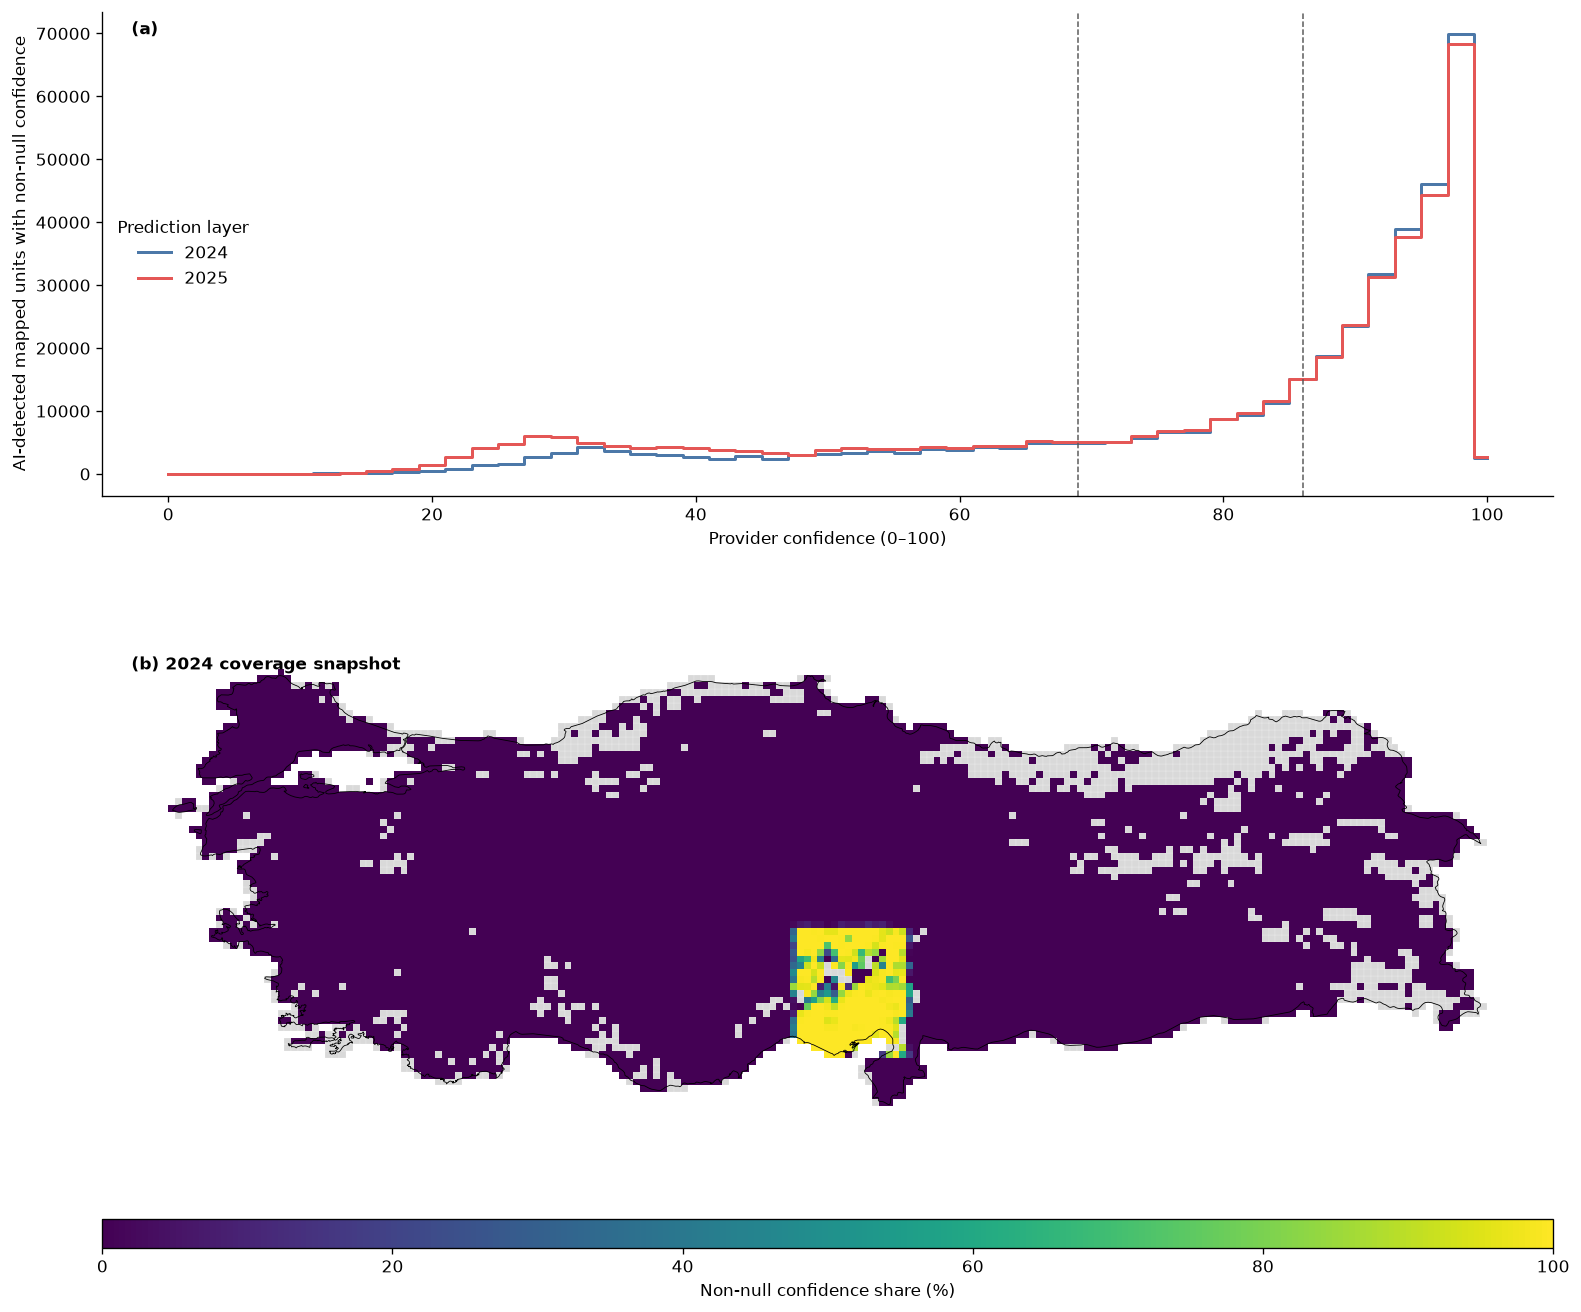

**Figure 3 interpretation.** Non-null confidence coverage is 2024: 2.71%, 2025: 2.70%.
    The histogram compares both layers; the map is explicitly the 2024 grid snapshot. Confidence
    describes a narrow covered subset and does not provide polygon-level correctness in Türkiye.
    HGM-derived assignments underlie the statistics; the generalized Natural Earth outline is used
    only for display and no HGM-derived geometry is redistributed in the figure.

,layer,field_count,non_null_confidence_count,null_confidence_count,null_confidence_share_pct,min_non_null_confidence,p10_non_null_confidence,median_non_null_confidence,p90_non_null_confidence,max_non_null_confidence
0,2024,14139788,382944,13756844,97.291727,11.552222,49.957943,91.842697,98.932610,100.0
1,2025,15075042,407060,14667982,97.299775,7.669921,38.345432,90.416977,98.887459,100.0


,attribute_or_claim,verification,provider_semantics,source_url,source_commit,source_last_modified,source_etag_prefix,access_date,canonical_json_sha256
0,confidence field present,Confirmed in distributed GeoParquet schema and...,Derived 0 to 100 reliability value; not an ups...,https://raw.githubusercontent.com/fieldsofthew...,e4f15533987340d0937f6b4b7463a4691e18f46b,26 June 2026 19:44:13 GMT,4a1247cc,2026-07-18,f4378de157228b9c59ca06591040b305832e6e279d609e...
1,sampling and rescaling,Confirmed in pinned vector STAC metadata,Point-on-surface sample from 500 m COG; raw / ...,https://raw.githubusercontent.com/fieldsofthew...,e4f15533987340d0937f6b4b7463a4691e18f46b,26 June 2026 19:44:13 GMT,4a1247cc,2026-07-18,f4378de157228b9c59ca06591040b305832e6e279d609e...
2,null confidence,Confirmed in pinned vector STAC metadata,Outside modelled-confidence coverage; no value...,https://raw.githubusercontent.com/fieldsofthew...,e4f15533987340d0937f6b4b7463a4691e18f46b,26 June 2026 19:44:13 GMT,4a1247cc,2026-07-18,f4378de157228b9c59ca06591040b305832e6e279d609e...
3,interpretation limit,Confirmed in pinned vector STAC metadata,"500 m cell reliability, not individual-polygon...",https://raw.githubusercontent.com/fieldsofthew...,e4f15533987340d0937f6b4b7463a4691e18f46b,26 June 2026 19:44:13 GMT,4a1247cc,2026-07-18,f4378de157228b9c59ca06591040b305832e6e279d609e...
4,raw probability attribute,Absent from both the distributed schema and pi...,Threshold equivalents are documentation consta...,https://raw.githubusercontent.com/fieldsofthew...,e4f15533987340d0937f6b4b7463a4691e18f46b,26 June 2026 19:44:13 GMT,4a1247cc,2026-07-18,f4378de157228b9c59ca06591040b305832e6e279d609e...


,layer,grid_cell_count,rook_neighbour_pair_count,median_absolute_neighbour_difference_pct,share_neighbour_pairs_within_10pp_pct,morans_i_null_share,fully_non_null_cell_count,mixed_cell_count,fully_null_cell_count,interpretation
0,2024,7490,13958,0.0,98.431007,0.947788,70,237,7183,Positive neighbour similarity supports coheren...
1,2025,7522,14084,0.0,99.353877,0.968776,261,57,7204,Positive neighbour similarity supports coheren...


In [12]:
vector_metadata = fetch_json(FTW_VECTOR_METADATA_URL)
vector_columns = {item['name']: item for item in vector_metadata['table:columns']}
assert 'confidence' in vector_columns
assert not any('probability' in name.lower() for name in vector_columns)
confidence_definition = vector_columns['confidence']['description']
for required_phrase in [
    'Derived; not part of the upstream model output',
    '0–100 scale',
    'point-on-surface',
    'raw / 0.578178 * 100',
    'null where the field falls outside',
    'not a low score',
    'not individual-polygon geometric accuracy',
]:
    assert required_phrase in confidence_definition, f'Missing provider phrase: {required_phrase}'
confidence_metadata_verification = pd.DataFrame([
    {
        'attribute_or_claim': 'confidence field present',
        'verification': 'Confirmed in distributed GeoParquet schema and pinned vector STAC metadata',
        'provider_semantics': 'Derived 0 to 100 reliability value; not an upstream raw model field',
    },
    {
        'attribute_or_claim': 'sampling and rescaling',
        'verification': 'Confirmed in pinned vector STAC metadata',
        'provider_semantics': 'Point-on-surface sample from 500 m COG; raw / 0.578178 x 100 and clamped to 100',
    },
    {
        'attribute_or_claim': 'null confidence',
        'verification': 'Confirmed in pinned vector STAC metadata',
        'provider_semantics': 'Outside modelled-confidence coverage; no value rather than a low score',
    },
    {
        'attribute_or_claim': 'interpretation limit',
        'verification': 'Confirmed in pinned vector STAC metadata',
        'provider_semantics': '500 m cell reliability, not individual-polygon geometric accuracy',
    },
    {
        'attribute_or_claim': 'raw probability attribute',
        'verification': 'Absent from both the distributed schema and pinned table:columns',
        'provider_semantics': 'Threshold equivalents are documentation constants, not a column analysed here',
    },
])
confidence_metadata_verification['source_url'] = FTW_VECTOR_METADATA_URL
confidence_metadata_verification['source_commit'] = FTW_VECTOR_METADATA_COMMIT
confidence_metadata_verification['source_last_modified'] = FTW_VECTOR_METADATA_LAST_MODIFIED
confidence_metadata_verification['source_etag_prefix'] = FTW_VECTOR_METADATA_ETAG
confidence_metadata_verification['access_date'] = ACCESS_DATE
confidence_metadata_verification['canonical_json_sha256'] = hashlib.sha256(
    json.dumps(vector_metadata, sort_keys=True).encode('utf-8')
).hexdigest()
write_table(confidence_metadata_verification, 'table_s_confidence_metadata_verification.csv')

confidence_national = con.execute(
    """SELECT
        layer,
        count(*) AS field_count,
        count(confidence) AS non_null_confidence_count,
        count(*) - count(confidence) AS null_confidence_count,
        100.0 * (count(*) - count(confidence)) / count(*) AS null_confidence_share_pct,
        min(confidence) AS min_non_null_confidence,
        quantile_cont(confidence, 0.10) AS p10_non_null_confidence,
        quantile_cont(confidence, 0.50) AS median_non_null_confidence,
        quantile_cont(confidence, 0.90) AS p90_non_null_confidence,
        max(confidence) AS max_non_null_confidence
    FROM ftw_cleaned
    GROUP BY 1 ORDER BY 1"""
).fetchdf()
assert set(confidence_national['layer']) == {2024, 2025}

province_confidence_raw = con.execute(
    """SELECT
        layer,
        "admin:subdivision_code" AS province_code,
        count(*) AS field_count,
        count(confidence) AS non_null_confidence_count,
        count(*) - count(confidence) AS null_confidence_count,
        100.0 * (count(*) - count(confidence)) / count(*) AS null_confidence_share_pct
    FROM ftw_cleaned
    WHERE regexp_full_match("admin:subdivision_code", '^(0[1-9]|[1-7][0-9]|8[0-1])$')
    GROUP BY 1, 2"""
).fetchdf()
province_layer_index = pd.MultiIndex.from_product(
    [[2024, 2025], province_lookup['province_code']], names=['layer', 'province_code']
).to_frame(index=False)
province_confidence = (
    province_layer_index
    .merge(province_lookup, on='province_code', how='left')
    .merge(province_confidence_raw, on=['layer', 'province_code'], how='left')
)
for count_column in ['field_count', 'non_null_confidence_count', 'null_confidence_count']:
    province_confidence[count_column] = province_confidence[count_column].fillna(0).astype('int64')
province_confidence.loc[
    province_confidence['field_count'].eq(0), 'null_confidence_share_pct'
] = np.nan
write_table(confidence_national, 'table_s8_national_confidence_coverage_2024_2025.csv')
write_table(province_confidence, 'table_s9_province_confidence_coverage_2024_2025.csv')

confidence_grid = con.execute(
    f"""SELECT
        layer,
        cast(floor(((bbox.xmin + bbox.xmax) / 2.0) / {GRID_CELL_DEGREES}) AS INTEGER) AS longitude_index,
        cast(floor(((bbox.ymin + bbox.ymax) / 2.0) / {GRID_CELL_DEGREES}) AS INTEGER) AS latitude_index,
        count(*) AS field_count,
        count(confidence) AS non_null_confidence_count,
        count(*) - count(confidence) AS null_confidence_count,
        100.0 * (count(*) - count(confidence)) / count(*) AS null_confidence_share_pct
    FROM ftw_cleaned
    GROUP BY 1, 2, 3 ORDER BY 1, 3, 2"""
).fetchdf()
confidence_grid['coverage_state'] = np.select(
    [
        confidence_grid['null_confidence_count'].eq(0),
        confidence_grid['non_null_confidence_count'].eq(0),
    ],
    ['fully_non_null', 'fully_null'],
    default='mixed',
)
confidence_grid['grid_cell_degrees'] = GRID_CELL_DEGREES
confidence_grid['grid_assignment_geometry'] = 'polygon bounding-box midpoint'
confidence_grid['grid_origin'] = '(0 degrees longitude, 0 degrees latitude)'
confidence_grid['grid_boundary_rule'] = 'half-open [minimum, maximum) bins via floor'
write_table(confidence_grid, 'table_s_confidence_grid_2024_2025.csv')
diagnostic_parts = []
for layer, layer_grid in confidence_grid.groupby('layer'):
    diagnostic = grid_neighbour_diagnostic(
        layer_grid,
        x_column='longitude_index',
        y_column='latitude_index',
        value_column='null_confidence_share_pct',
    )
    diagnostic.insert(0, 'layer', int(layer))
    coverage_state_counts = layer_grid['coverage_state'].value_counts()
    for coverage_state in ['fully_non_null', 'mixed', 'fully_null']:
        diagnostic[f'{coverage_state}_cell_count'] = int(coverage_state_counts.get(coverage_state, 0))
    diagnostic_parts.append(diagnostic)
confidence_spatial_diagnostic = pd.concat(diagnostic_parts, ignore_index=True)
confidence_spatial_diagnostic['interpretation'] = (
    'Positive neighbour similarity supports coherent coverage zones; provider metadata, not this diagnostic, establishes null semantics'
)
write_table(confidence_spatial_diagnostic, 'table_s_confidence_spatial_diagnostic_2024_2025.csv')

confidence_histogram = con.execute(
    """SELECT
        layer,
        least(100, cast(floor(confidence / 2.0) * 2 AS INTEGER)) AS confidence_bin,
        count(*) AS field_count
    FROM ftw_cleaned
    WHERE confidence IS NOT NULL
    GROUP BY 1, 2 ORDER BY 1, 2"""
).fetchdf()
write_table(confidence_histogram, 'table_s10_confidence_histogram_2024_2025.csv')

figure = plt.figure(figsize=(13, 11.2))
layout = figure.add_gridspec(2, 1, height_ratios=(0.82, 1.10), hspace=0.18)
axis = figure.add_subplot(layout[0])
confidence_colours = {2024: '#4c78a8', 2025: '#e45756'}
for layer, frame in confidence_histogram.groupby('layer'):
    bins = np.arange(0, 102, 2)
    counts = frame.set_index('confidence_bin')['field_count'].reindex(bins, fill_value=0).to_numpy()
    axis.step(bins, counts, where='mid', linewidth=1.8, color=confidence_colours[int(layer)], label=str(int(layer)))
for threshold in CONFIDENCE_THRESHOLDS:
    axis.axvline(threshold, color='0.35', linestyle='--', linewidth=0.9)
axis.set_xlabel('Provider confidence (0–100)')
axis.set_ylabel('AI-detected mapped units with non-null confidence')
axis.legend(title='Prediction layer', frameon=False)
axis.text(0.02, 0.98, '(a)', transform=axis.transAxes, va='top', fontweight='bold')

# The map panel is explicitly a 2024 snapshot; both layers are analysed in tables.
confidence_grid_2024 = confidence_grid.loc[confidence_grid['layer'].eq(2024)].copy()
map_layout = layout[1].subgridspec(2, 1, height_ratios=(20, 1), hspace=0.14)
axis = figure.add_subplot(map_layout[0])
colour_axis = figure.add_subplot(map_layout[1])
confidence_norm = Normalize(vmin=0, vmax=100)
confidence_country_outline = ne_provinces.dissolve()
confidence_land = ne_provinces.dissolve().geometry.iloc[0]
occupied_confidence_cells = gpd.GeoDataFrame(
    confidence_grid_2024.assign(
        non_null_confidence_share_pct=100.0
        * confidence_grid_2024['non_null_confidence_count']
        / confidence_grid_2024['field_count'],
        geometry=[
            box(
                longitude_index * GRID_CELL_DEGREES,
                latitude_index * GRID_CELL_DEGREES,
                (longitude_index + 1) * GRID_CELL_DEGREES,
                (latitude_index + 1) * GRID_CELL_DEGREES,
            )
            for longitude_index, latitude_index in zip(
                confidence_grid_2024['longitude_index'], confidence_grid_2024['latitude_index']
            )
        ],
    ),
    geometry='geometry', crs='EPSG:4326',
)
occupied_index = set(zip(confidence_grid_2024['longitude_index'], confidence_grid_2024['latitude_index']))
land_minx, land_miny, land_maxx, land_maxy = confidence_land.bounds
empty_land_cells = [
    box(
        longitude_index * GRID_CELL_DEGREES,
        latitude_index * GRID_CELL_DEGREES,
        (longitude_index + 1) * GRID_CELL_DEGREES,
        (latitude_index + 1) * GRID_CELL_DEGREES,
    )
    for longitude_index in range(int(np.floor(land_minx / GRID_CELL_DEGREES)), int(np.floor(land_maxx / GRID_CELL_DEGREES)) + 1)
    for latitude_index in range(int(np.floor(land_miny / GRID_CELL_DEGREES)), int(np.floor(land_maxy / GRID_CELL_DEGREES)) + 1)
    if (longitude_index, latitude_index) not in occupied_index
    and box(
        longitude_index * GRID_CELL_DEGREES,
        latitude_index * GRID_CELL_DEGREES,
        (longitude_index + 1) * GRID_CELL_DEGREES,
        (latitude_index + 1) * GRID_CELL_DEGREES,
    ).intersects(confidence_land)
]
empty_confidence_cells = gpd.GeoDataFrame(geometry=empty_land_cells, crs='EPSG:4326')
if not empty_confidence_cells.empty:
    empty_confidence_cells.plot(ax=axis, color='#d9d9d9', edgecolor='white', linewidth=0.1)
occupied_confidence_cells.plot(
    column='non_null_confidence_share_pct', cmap='viridis', norm=confidence_norm,
    linewidth=0.0, edgecolor='none', ax=axis,
)
confidence_country_outline.boundary.plot(ax=axis, color='black', linewidth=0.5)
axis.set_aspect('equal')
axis.set_axis_off()
axis.text(0.02, 0.98, '(b) 2024 coverage snapshot', transform=axis.transAxes, va='top', fontweight='bold')
colourbar = figure.colorbar(
    plt.cm.ScalarMappable(norm=confidence_norm, cmap='viridis'),
    cax=colour_axis, orientation='horizontal',
)
colourbar.set_label('Non-null confidence share (%)')
figure.subplots_adjust(left=0.055, right=0.985, top=0.98, bottom=0.06)
save_figure(figure, 'fig_3_confidence_2024_2025')

coverage_text = []
for record in confidence_national.itertuples(index=False):
    coverage_text.append(
        f"{int(record.layer)}: {100.0 * record.non_null_confidence_count / record.field_count:.2f}%"
    )
display(Markdown(
    f"""**Figure 3 interpretation.** Non-null confidence coverage is {', '.join(coverage_text)}.
    The histogram compares both layers; the map is explicitly the 2024 grid snapshot. Confidence
    describes a narrow covered subset and does not provide polygon-level correctness in Türkiye.
    HGM-derived assignments underlie the statistics; the generalized Natural Earth outline is used
    only for display and no HGM-derived geometry is redistributed in the figure."""
))
display(confidence_national)
display(confidence_metadata_verification)
display(confidence_spatial_diagnostic)


In [13]:
confidence_sensitivity_parts = []
confidence_sensitivity_specs = [
    (1, 'Non-null confidence, unfiltered', np.nan, np.nan),
    (2, 'conf >= 69 (raw >= 0.4)', 0.4, 69.0),
    (3, 'conf >= 86 (raw >= 0.5)', 0.5, 86.0),
]
for layer in (2024, 2025):
    for display_order, filter_label, raw_threshold, confidence_threshold in confidence_sensitivity_specs:
        threshold_filter = '' if np.isnan(confidence_threshold) else f'AND confidence >= {confidence_threshold}'
        row = con.execute(
            f"""SELECT
                {layer}::INTEGER AS layer,
                {display_order}::INTEGER AS display_order,
                '{filter_label}' AS filter_label,
                {('NULL' if np.isnan(raw_threshold) else raw_threshold)}::DOUBLE AS documented_raw_threshold_equivalent,
                {('NULL' if np.isnan(confidence_threshold) else confidence_threshold)}::DOUBLE AS confidence_threshold,
                count(*) AS field_count,
                sum("metrics:area") / 10000.0 AS total_mapped_area_ha,
                quantile_cont("metrics:area", 0.50) / 10000.0 AS median_field_area_ha
            FROM ftw_cleaned
            WHERE layer = {layer} AND confidence IS NOT NULL {threshold_filter}"""
        ).fetchdf()
        confidence_sensitivity_parts.append(row)
confidence_sensitivity = pd.concat(confidence_sensitivity_parts, ignore_index=True)
write_table(confidence_sensitivity, 'table_s_confidence_sensitivity_2024_2025.csv')

coverage_rows = []
for national_record in confidence_national.itertuples(index=False):
    layer = int(national_record.layer)
    coverage_rows.extend([
        (layer, 'Coverage', 'Cleaned mapped units', None, None, int(national_record.field_count), None, None, None, 'count'),
        (layer, 'Coverage', 'Non-null confidence', None, None, int(national_record.non_null_confidence_count), None, None,
         100.0 * national_record.non_null_confidence_count / national_record.field_count, '% of layer'),
        (layer, 'Coverage', 'Null confidence', None, None, int(national_record.null_confidence_count), None, None,
         float(national_record.null_confidence_share_pct), '% of layer'),
        (layer, 'Distribution', 'Median non-null confidence', None, None, None, None, None,
         float(national_record.median_non_null_confidence), '0-100'),
        (layer, 'Distribution', '10th-90th percentile non-null confidence', None, None, None, None, None,
         f"{float(national_record.p10_non_null_confidence):.2f}-{float(national_record.p90_non_null_confidence):.2f}", '0-100'),
    ])
table_4_coverage = pd.DataFrame(
    coverage_rows,
    columns=[
        'layer', 'section', 'measure_or_filter', 'documented_raw_threshold_equivalent',
        'confidence_threshold', 'field_count', 'total_mapped_area_ha',
        'median_field_area_ha', 'value', 'unit',
    ],
)
table_4_sensitivity = confidence_sensitivity.assign(
    section='Sensitivity',
    measure_or_filter=confidence_sensitivity['filter_label'],
    value=np.nan,
    unit='',
)[[
    'layer', 'section', 'measure_or_filter', 'documented_raw_threshold_equivalent',
    'confidence_threshold', 'field_count', 'total_mapped_area_ha',
    'median_field_area_ha', 'value', 'unit',
]]
table_4 = pd.concat([table_4_coverage, table_4_sensitivity], ignore_index=True)
write_table(table_4, 'table_4_confidence_coverage_sensitivity_2024_2025.csv')

raw_default, raw_conservative = RAW_CONFIDENCE_THRESHOLDS
displayed_default, displayed_conservative = CONFIDENCE_THRESHOLDS
scaled_default = raw_default / CONFIDENCE_RESCALE_DENOMINATOR * 100.0
scaled_conservative = raw_conservative / CONFIDENCE_RESCALE_DENOMINATOR * 100.0
retained_text = []
for layer in (2024, 2025):
    layer_rows = confidence_sensitivity.loc[confidence_sensitivity['layer'].eq(layer)]
    retained_text.append(
        f"{layer}: {int(layer_rows.loc[layer_rows['display_order'].eq(2), 'field_count'].iloc[0]):,} / "
        f"{int(layer_rows.loc[layer_rows['display_order'].eq(3), 'field_count'].iloc[0]):,}"
    )
display(Markdown(
    f"""**Confidence method and Table 4 interpretation.** Provider rescaling converts raw
    screens {raw_default:.1f}/{raw_conservative:.1f} to {scaled_default:.2f}/{scaled_conservative:.2f},
    reported using rounded displays {displayed_default:g}/{displayed_conservative:g}. Retained
    counts at those screens are {'; '.join(retained_text)}. Null means outside coverage, so these
    are coverage/sensitivity diagnostics for both layers, not prediction accuracy estimates."""
))
display(table_4)


**Confidence method and Table 4 interpretation.** Provider rescaling converts raw
    screens 0.4/0.5 to 69.18/86.48,
    reported using rounded displays 69/86. Retained
    counts at those screens are 2024: 307,668 / 246,750; 2025: 304,156 / 241,501. Null means outside coverage, so these
    are coverage/sensitivity diagnostics for both layers, not prediction accuracy estimates.

,layer,section,measure_or_filter,documented_raw_threshold_equivalent,confidence_threshold,field_count,total_mapped_area_ha,median_field_area_ha,value,unit
0,2024,Coverage,Cleaned mapped units,None,None,14139788.0,None,None,None,count
1,2024,Coverage,Non-null confidence,None,None,382944.0,None,None,2.708273,% of layer
2,2024,Coverage,Null confidence,None,None,13756844.0,None,None,97.291727,% of layer
3,2024,Distribution,Median non-null confidence,None,None,NaN,None,None,91.842697,0-100
4,2024,Distribution,10th-90th percentile non-null confidence,None,None,NaN,None,None,49.96-98.93,0-100
5,2025,Coverage,Cleaned mapped units,None,None,15075042.0,None,None,None,count
6,2025,Coverage,Non-null confidence,None,None,407060.0,None,None,2.700225,% of layer
7,2025,Coverage,Null confidence,None,None,14667982.0,None,None,97.299775,% of layer
8,2025,Distribution,Median non-null confidence,None,None,NaN,None,None,90.416977,0-100
9,2025,Distribution,10th-90th percentile non-null confidence,None,None,NaN,None,None,38.35-98.89,0-100


## Results: cross-layer consistency between annual prediction layers

Province-level correspondence is reported as consistency between annual model-output
layers. It does not infer agricultural change or land-use transition.


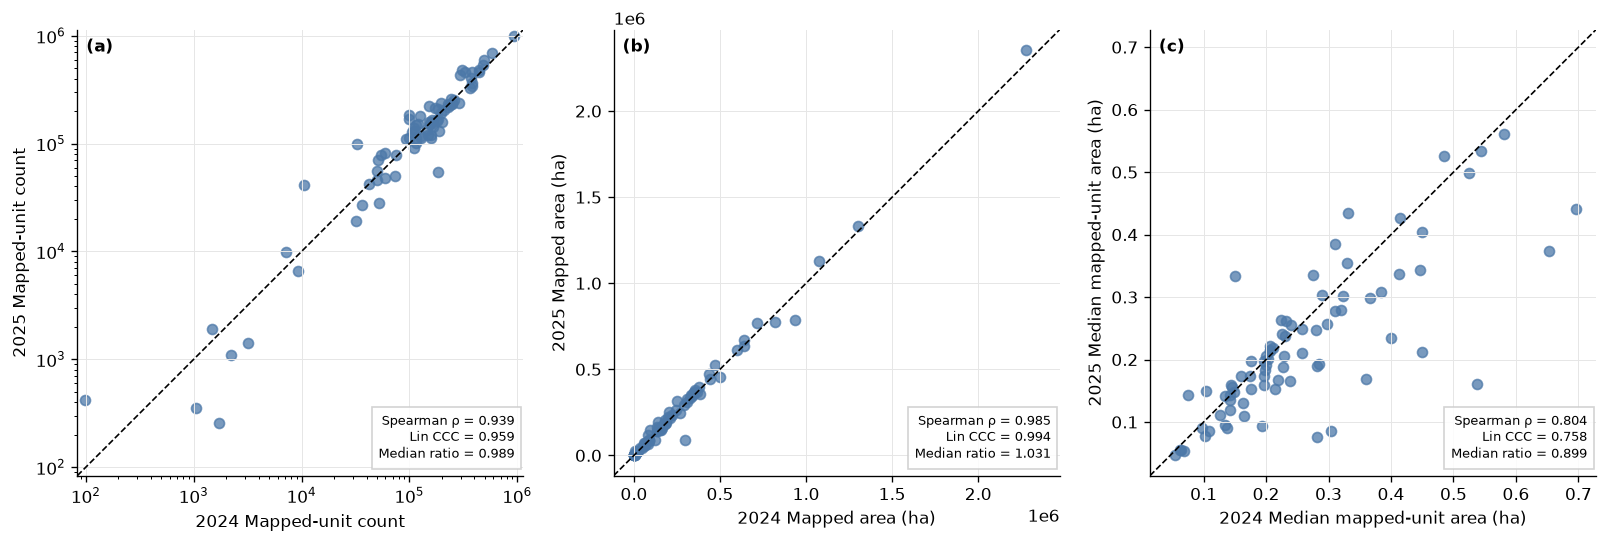

Türkiye's cleaned 2025 layer contains +6.61% mapped units
        relative to the cleaned 2024 layer. Total mapped area differs by
        +2.13% and the national median unit area by
        -18.05%. These are model-output level offsets only;
        it is not interpreted as agricultural change.

,metric,metric_label,province_count,pearson_r,spearman_rho,lin_concordance_ccc,national_2024,national_2025,national_absolute_difference,national_difference_pct,province_ratio_count,province_ratio_p25,province_ratio_median,province_ratio_p75
0,field_count,Mapped-unit count,81,0.968200,0.938528,0.959144,1.413979e+07,1.507504e+07,935254.000000,6.614342,80,0.882288,0.988726,1.223121
1,total_mapped_area_ha,Mapped area (ha),81,0.994339,0.984914,0.994022,2.107973e+07,2.152963e+07,449905.734748,2.134305,80,0.978506,1.031165,1.077898
2,median_field_area_ha,Median mapped-unit area (ha),80,0.794032,0.803962,0.758253,2.126164e-01,1.742463e-01,-0.038370,-18.046648,80,0.784849,0.898685,1.039101


**Table 5 interpretation.** Province-level correspondence is high for mapped-unit count
        (Pearson r = 0.968) and mapped area
        (Pearson r = 0.994) across the two layers.
        Spearman statistics describe rank stability, Pearson statistics describe linear
        association, and Lin CCC plus the ratio distributions describe level agreement.
        These are descriptive statistics over the complete 81-province reporting frame;
        no bootstrap interval or null-hypothesis significance claim is attached to them.
        High association does not remove the systematic offsets and does not establish
        agricultural stability or change. Any zero-count province has an undefined median
        and is excluded pairwise from median-area statistics.

In [14]:
comparison_metrics = [
    ("field_count", "Mapped-unit count"),
    ("total_mapped_area_ha", "Mapped area (ha)"),
    ("median_field_area_ha", "Median mapped-unit area (ha)"),
]
comparison_wide = province_metrics_all.pivot(
    index="province_code", columns="layer", values=[metric for metric, _ in comparison_metrics]
)
comparison_wide.columns = [f"{metric}_{layer}" for metric, layer in comparison_wide.columns]
comparison_wide = comparison_wide.reset_index().merge(
    province_lookup[["province_code", "province_name"]], on="province_code", how="left"
)
for metric, _ in comparison_metrics:
    denominator = comparison_wide[f'{metric}_2024']
    comparison_wide[f'{metric}_ratio_2025_to_2024'] = np.where(
        denominator.gt(0), comparison_wide[f'{metric}_2025'] / denominator, np.nan
    )
write_table(comparison_wide, "table_s12_province_cross_layer_comparison_wide.csv")
province_ratio_columns = ['province_code', 'province_name'] + [
    f'{metric}_ratio_2025_to_2024' for metric, _ in comparison_metrics
]
write_table(comparison_wide[province_ratio_columns], 'table_s_province_cross_layer_ratios.csv')

national_consistency_values = {
    'field_count': dict(zip(national_summary['layer'], national_summary['field_count'])),
    'total_mapped_area_ha': dict(zip(national_summary['layer'], national_summary['total_mapped_area_ha'])),
    'median_field_area_ha': dict(zip(national_summary['layer'], national_summary['median_field_area_ha'])),
}
consistency_rows = []
for metric, label in comparison_metrics:
    subset = comparison_wide[[f"{metric}_2024", f"{metric}_2025"]].dropna()
    ratio_values = comparison_wide[f'{metric}_ratio_2025_to_2024'].dropna()
    national_2024_value = float(national_consistency_values[metric][2024])
    national_2025_value = float(national_consistency_values[metric][2025])
    consistency_row = {
        "metric": metric,
        "metric_label": label,
        "province_count": len(subset),
        "pearson_r": subset[f"{metric}_2024"].corr(subset[f"{metric}_2025"], method="pearson"),
        "spearman_rho": subset[f"{metric}_2024"].corr(subset[f"{metric}_2025"], method="spearman"),
        "lin_concordance_ccc": lin_concordance(subset[f'{metric}_2024'], subset[f'{metric}_2025']),
        "national_2024": national_2024_value,
        "national_2025": national_2025_value,
        "national_absolute_difference": national_2025_value - national_2024_value,
        "national_difference_pct": 100.0 * (national_2025_value / national_2024_value - 1.0),
        "province_ratio_count": len(ratio_values),
        "province_ratio_p25": ratio_values.quantile(0.25),
        "province_ratio_median": ratio_values.median(),
        "province_ratio_p75": ratio_values.quantile(0.75),
    }
    consistency_rows.append(consistency_row)
table_5 = pd.DataFrame(consistency_rows)
write_table(table_5, "table_5_cross_layer_consistency_2024_2025.csv")
figure, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
for panel_label, axis, (metric, label) in zip(["(a)", "(b)", "(c)"], axes, comparison_metrics):
    x_column = f"{metric}_2024"
    y_column = f"{metric}_2025"
    subset = comparison_wide[[x_column, y_column]].dropna()
    plot_subset = subset.loc[subset[x_column].gt(0) & subset[y_column].gt(0)]
    if metric == "field_count":
        axis.set_xscale("log")
        axis.set_yscale("log")
    else:
        plot_subset = subset
    axis.scatter(plot_subset[x_column], plot_subset[y_column], color="#4c78a8", alpha=0.75)
    lower = min(plot_subset[x_column].min(), plot_subset[y_column].min())
    upper = max(plot_subset[x_column].max(), plot_subset[y_column].max())
    if metric == "field_count":
        lower *= 0.85
        upper *= 1.15
    else:
        padding = max((upper - lower) * 0.05, 1e-9)
        lower -= padding
        upper += padding
    axis.plot([lower, upper], [lower, upper], color="black", linestyle="--", linewidth=1)
    axis.set_xlim(lower, upper)
    axis.set_ylim(lower, upper)
    axis.set_aspect("equal", adjustable="box")
    axis.set_xlabel(f"2024 {label}")
    axis.set_ylabel(f"2025 {label}")
    axis.grid(color="0.9", linewidth=0.6)
    axis.text(0.02, 0.98, panel_label, transform=axis.transAxes, va="top", fontweight="bold")
    consistency_row = table_5.loc[table_5['metric'].eq(metric)].iloc[0]
    axis.text(
        0.98, 0.03,
        (f"Spearman ρ = {consistency_row['spearman_rho']:.3f}\n"
         f"Lin CCC = {consistency_row['lin_concordance_ccc']:.3f}\n"
         f"Median ratio = {consistency_row['province_ratio_median']:.3f}"),
        transform=axis.transAxes, ha='right', va='bottom', fontsize=8,
        bbox={'facecolor': 'white', 'edgecolor': '0.8', 'alpha': 0.85},
    )
figure.tight_layout()
save_figure(figure, "fig_4_cross_layer_consistency_2024_2025")

national_2024 = national_summary.loc[national_summary["layer"].eq(2024)].iloc[0]
national_2025 = national_summary.loc[national_summary["layer"].eq(2025)].iloc[0]
field_count_difference_pct = 100 * (
    national_2025["field_count"] - national_2024["field_count"]
) / national_2024["field_count"]
mapped_area_difference_pct = 100 * (
    national_2025['total_mapped_area_ha'] - national_2024['total_mapped_area_ha']
) / national_2024['total_mapped_area_ha']
median_area_difference_pct = 100 * (
    national_2025['median_field_area_ha'] - national_2024['median_field_area_ha']
) / national_2024['median_field_area_ha']
display(
    Markdown(
        f"""Türkiye's cleaned 2025 layer contains {field_count_difference_pct:+.2f}% mapped units
        relative to the cleaned 2024 layer. Total mapped area differs by
        {mapped_area_difference_pct:+.2f}% and the national median unit area by
        {median_area_difference_pct:+.2f}%. These are model-output level offsets only;
        it is not interpreted as agricultural change."""
    )
)
display(table_5)

field_count_consistency = table_5.loc[table_5["metric"].eq("field_count")].iloc[0]
area_consistency = table_5.loc[table_5["metric"].eq("total_mapped_area_ha")].iloc[0]
display(
    Markdown(
        f"""**Table 5 interpretation.** Province-level correspondence is high for mapped-unit count
        (Pearson r = {float(field_count_consistency['pearson_r']):.3f}) and mapped area
        (Pearson r = {float(area_consistency['pearson_r']):.3f}) across the two layers.
        Spearman statistics describe rank stability, Pearson statistics describe linear
        association, and Lin CCC plus the ratio distributions describe level agreement.
        These are descriptive statistics over the complete 81-province reporting frame;
        no bootstrap interval or null-hypothesis significance claim is attached to them.
        High association does not remove the systematic offsets and does not establish
        agricultural stability or change. Any zero-count province has an undefined median
        and is excluded pairwise from median-area statistics."""
    )
)


## Results: spatial patterns

The national density visualization bins bounding-box centres only for cartography. It is
not used to calculate national or province metrics.


,metric,grid_cell_degrees,union_of_occupied_cell_count,both_layers_positive_cell_count,zero_2024_cell_count,zero_2025_cell_count,ratio_defined_cell_count,pearson_r,spearman_rho,lin_concordance_ccc,median_ratio_2025_to_2024_where_2024_positive,assignment_rule,interpretation
0,field_count,0.1,7758,7254,268,236,7490,0.905861,0.904622,0.899992,1.017288,polygon bounding-box midpoint; half-open 0.1-d...,finite-population aggregation-scale sensitivit...
1,summed_mapped_area_ha,0.1,7758,7254,268,236,7490,0.894552,0.929993,0.894316,1.028153,polygon bounding-box midpoint; half-open 0.1-d...,finite-population aggregation-scale sensitivit...


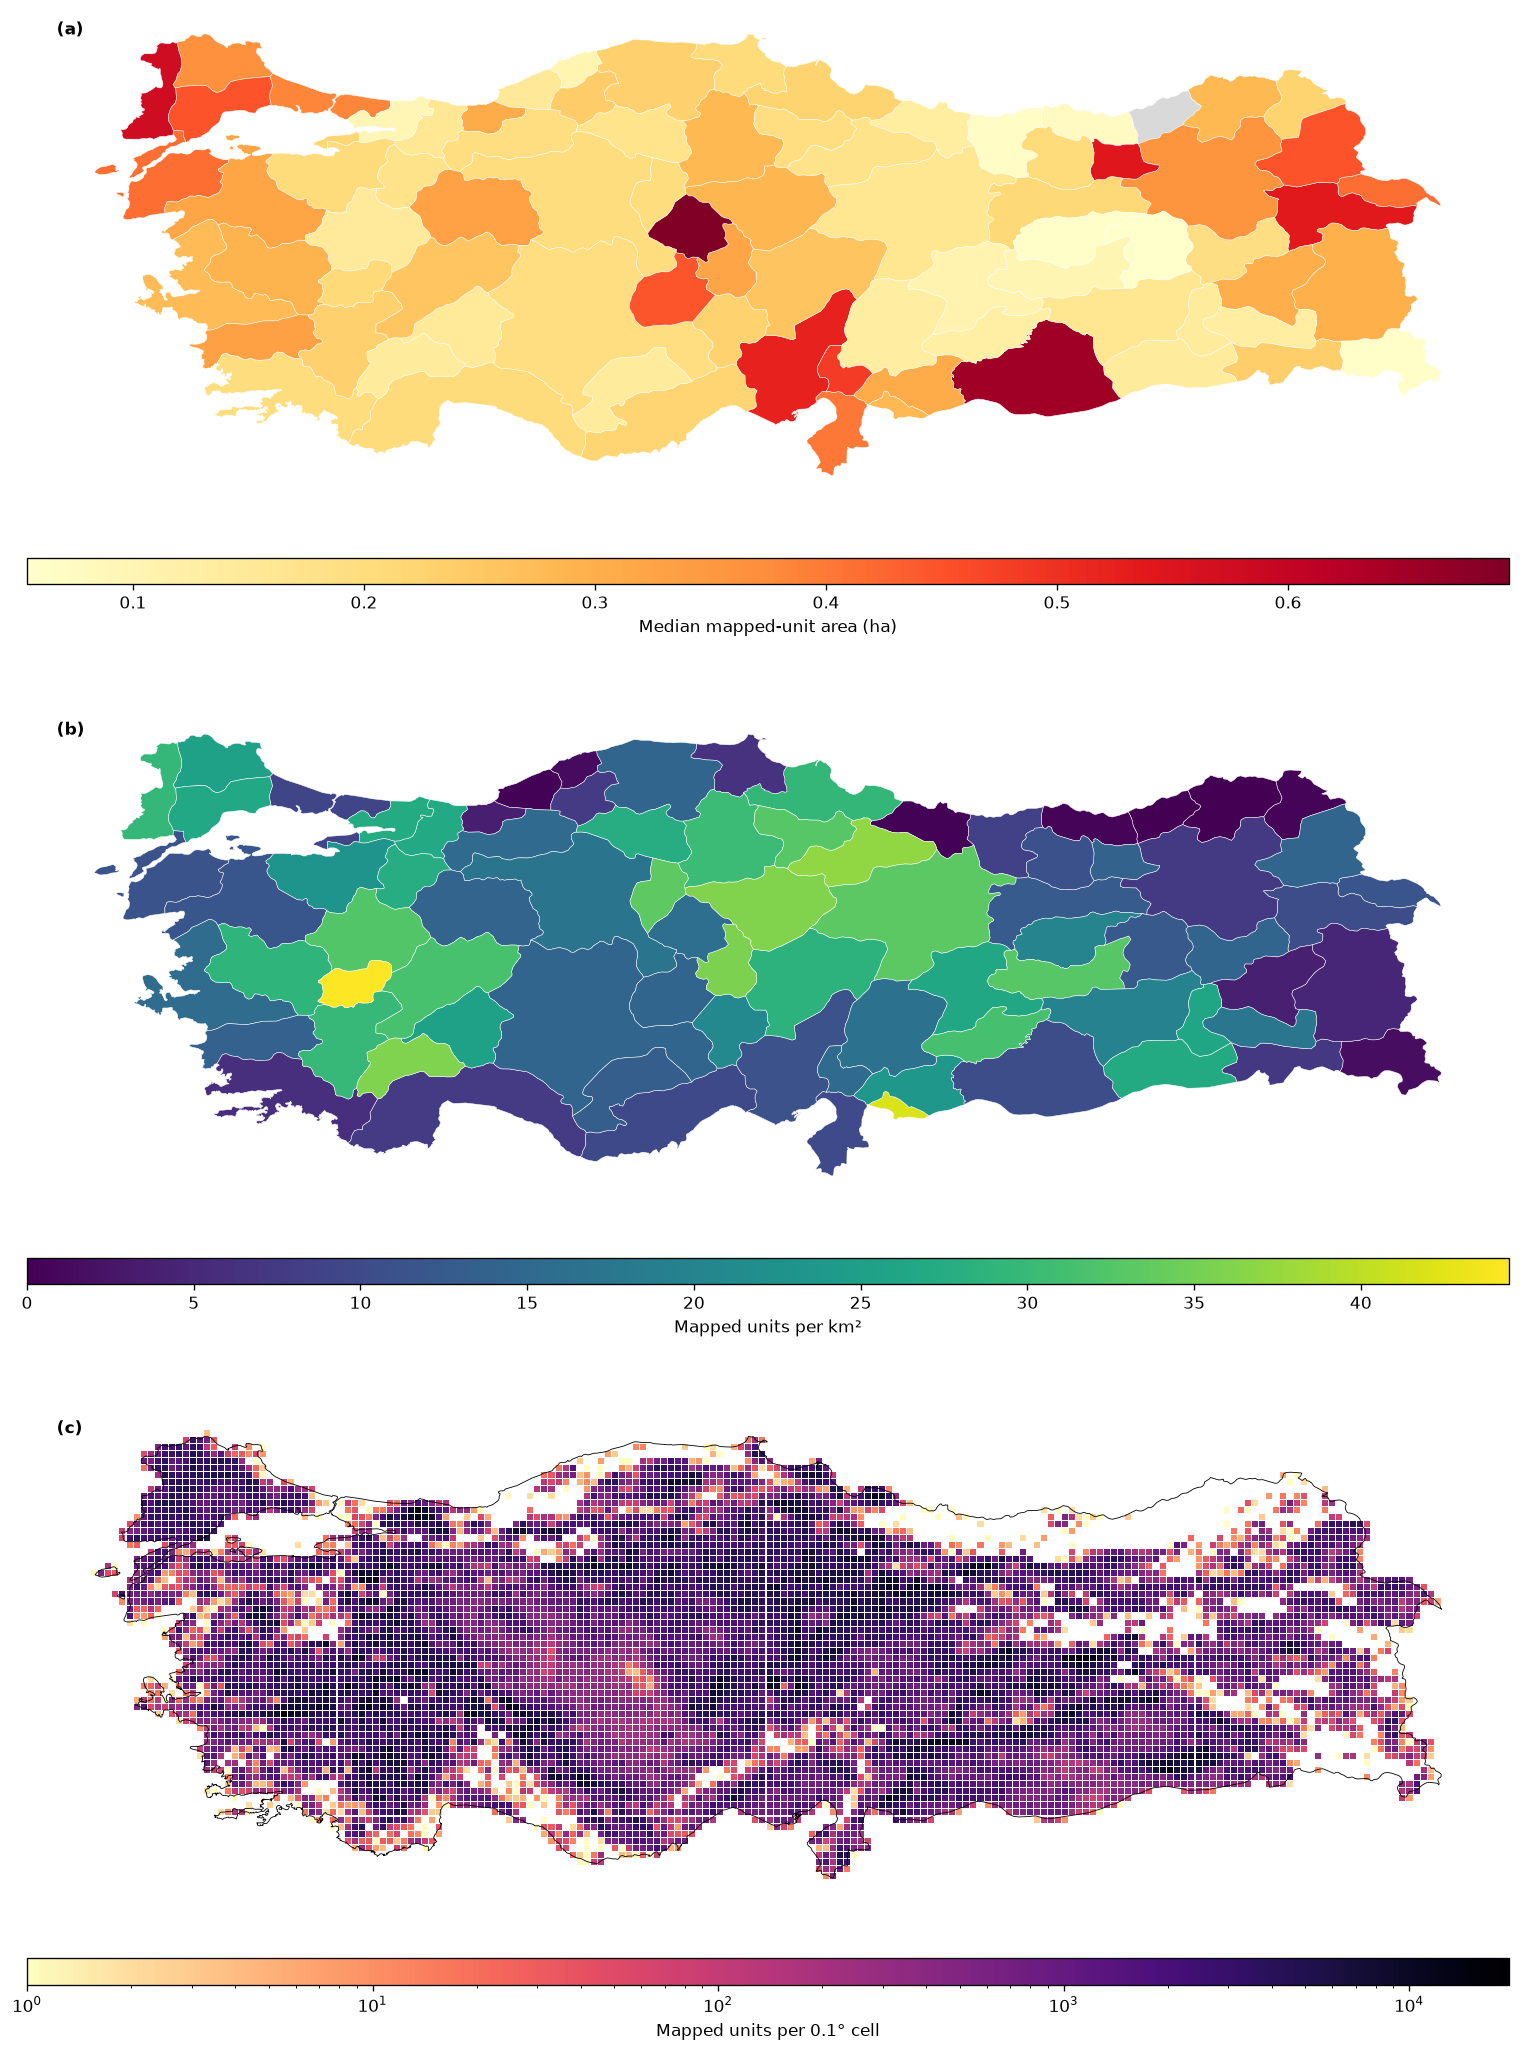

**Figure 2 interpretation.** The province maps and centre-based density grid show
        marked spatial heterogeneity in the distributed prediction product. The highest
        province density is 44.44
        mapped units per km² in Uşak. The grid is a
        visualization of bounding-box centres, not an estimate of field coverage or ground truth.
        HGM-derived assignments and HGM tabular areas underlie the statistics; generalized Natural
        Earth province and national outlines are used only for display, and no HGM-derived geometry
        is redistributed in the figure.

In [15]:
density_grid_all = con.execute(
    f"""SELECT
        layer,
        cast(floor(((bbox.xmin + bbox.xmax) / 2.0) / {GRID_CELL_DEGREES}) AS INTEGER)
            AS longitude_index,
        cast(floor(((bbox.ymin + bbox.ymax) / 2.0) / {GRID_CELL_DEGREES}) AS INTEGER)
            AS latitude_index,
        count(*) AS field_count,
        sum("metrics:area") / 10000.0 AS summed_mapped_area_ha
    FROM ftw_cleaned
    GROUP BY 1, 2, 3
    ORDER BY 1, 3, 2"""
).fetchdf()
density_grid_all["longitude_bin"] = density_grid_all["longitude_index"] * GRID_CELL_DEGREES
density_grid_all["latitude_bin"] = density_grid_all["latitude_index"] * GRID_CELL_DEGREES
density_grid_all["longitude_center"] = density_grid_all["longitude_bin"] + GRID_CELL_DEGREES / 2.0
density_grid_all["latitude_center"] = density_grid_all["latitude_bin"] + GRID_CELL_DEGREES / 2.0
density_grid_all["grid_cell_degrees"] = GRID_CELL_DEGREES
density_grid_all["grid_assignment_geometry"] = "polygon bounding-box midpoint"
density_grid_all["grid_origin"] = "(0 degrees longitude, 0 degrees latitude)"
density_grid_all["grid_boundary_rule"] = "half-open [minimum, maximum) bins via floor"
write_table(density_grid_all, "table_s13_density_grid_2024_2025.csv")
density_grid = density_grid_all.loc[density_grid_all["layer"].eq(2024)].copy()
write_table(density_grid, "table_s13_density_grid_2024.csv")

grid_wide = density_grid_all.pivot(
    index=["longitude_index", "latitude_index"],
    columns="layer",
    values=["field_count", "summed_mapped_area_ha"],
).fillna(0.0)
grid_wide.columns = [f"{metric}_{int(layer)}" for metric, layer in grid_wide.columns]
grid_wide = grid_wide.reset_index()
grid_cross_layer_rows = []
for grid_metric in ("field_count", "summed_mapped_area_ha"):
    early = grid_wide[f"{grid_metric}_2024"].astype(float)
    late = grid_wide[f"{grid_metric}_2025"].astype(float)
    baseline_positive = early.gt(0)
    both_positive = baseline_positive & late.gt(0)
    ratios = late.loc[baseline_positive] / early.loc[baseline_positive]
    grid_cross_layer_rows.append({
        "metric": grid_metric,
        "grid_cell_degrees": GRID_CELL_DEGREES,
        "union_of_occupied_cell_count": len(grid_wide),
        "both_layers_positive_cell_count": int(both_positive.sum()),
        "zero_2024_cell_count": int(early.eq(0).sum()),
        "zero_2025_cell_count": int(late.eq(0).sum()),
        "ratio_defined_cell_count": int(baseline_positive.sum()),
        "pearson_r": early.corr(late, method="pearson"),
        "spearman_rho": early.corr(late, method="spearman"),
        "lin_concordance_ccc": lin_concordance(early, late),
        "median_ratio_2025_to_2024_where_2024_positive": ratios.median(),
        "assignment_rule": (
            "polygon bounding-box midpoint; half-open 0.1-degree bins anchored at (0,0)"
        ),
        "interpretation": (
            "finite-population aggregation-scale sensitivity; zeros retained on the union "
            "of occupied cells; not agricultural change"
        ),
    })
grid_cross_layer_consistency = pd.DataFrame(grid_cross_layer_rows)
write_table(
    grid_cross_layer_consistency,
    "table_s_grid_cross_layer_consistency_0_1deg.csv",
)
display(grid_cross_layer_consistency)

country_outline = ne_provinces.dissolve()

figure = plt.figure(figsize=(13, 17.4))
layout = figure.add_gridspec(3, 1, hspace=0.18)

median_norm = Normalize(
    vmin=float(province_map["median_field_area_ha"].min()),
    vmax=float(province_map["median_field_area_ha"].max()),
)
density_norm = Normalize(
    vmin=float(province_map["field_density_per_km2"].min()),
    vmax=float(province_map["field_density_per_km2"].max()),
)

map_layout = layout[0].subgridspec(2, 1, height_ratios=(20, 1), hspace=0.14)
axis = figure.add_subplot(map_layout[0])
colour_axis = figure.add_subplot(map_layout[1])
province_map.plot(
    column="median_field_area_ha",
    cmap="YlOrRd",
    norm=median_norm,
    linewidth=0.3,
    edgecolor="white",
    legend=False,
    missing_kwds={"color": "#d9d9d9", "label": "No mapped units"},
    ax=axis,
)
axis.set_aspect("equal")
axis.set_axis_off()
axis.text(0.02, 0.98, "(a)", transform=axis.transAxes, va="top", fontweight="bold")
colourbar = figure.colorbar(
    plt.cm.ScalarMappable(norm=median_norm, cmap="YlOrRd"),
    cax=colour_axis,
    orientation="horizontal",
)
colourbar.set_label("Median mapped-unit area (ha)")

map_layout = layout[1].subgridspec(2, 1, height_ratios=(20, 1), hspace=0.14)
axis = figure.add_subplot(map_layout[0])
colour_axis = figure.add_subplot(map_layout[1])
province_map.plot(
    column="field_density_per_km2",
    cmap="viridis",
    norm=density_norm,
    linewidth=0.3,
    edgecolor="white",
    legend=False,
    missing_kwds={"color": "#d9d9d9", "label": "No mapped units"},
    ax=axis,
)
axis.set_aspect("equal")
axis.set_axis_off()
axis.text(0.02, 0.98, "(b)", transform=axis.transAxes, va="top", fontweight="bold")
colourbar = figure.colorbar(
    plt.cm.ScalarMappable(norm=density_norm, cmap="viridis"),
    cax=colour_axis,
    orientation="horizontal",
)
colourbar.set_label("Mapped units per km²")

map_layout = layout[2].subgridspec(2, 1, height_ratios=(20, 1), hspace=0.14)
axis = figure.add_subplot(map_layout[0])
colour_axis = figure.add_subplot(map_layout[1])
country_outline.boundary.plot(ax=axis, color="black", linewidth=0.5)
colour_norm = LogNorm(
    vmin=max(1, density_grid["field_count"].min()), vmax=density_grid["field_count"].max()
)
points = axis.scatter(
    density_grid["longitude_center"],
    density_grid["latitude_center"],
    c=density_grid["field_count"],
    s=13,
    marker="s",
    cmap="magma_r",
    norm=colour_norm,
    linewidths=0,
)
axis.set_aspect("equal")
axis.set_axis_off()
axis.text(0.02, 0.98, "(c)", transform=axis.transAxes, va="top", fontweight="bold")
colourbar = figure.colorbar(points, cax=colour_axis, orientation="horizontal")
colourbar.set_label("Mapped units per 0.1° cell")

figure.subplots_adjust(left=0.04, right=0.99, top=0.99, bottom=0.035)
save_figure(figure, "fig_2_spatial_patterns_2024")

highest_density_province = table_3.nlargest(1, "field_density_per_km2").iloc[0]
display(
    Markdown(
        f"""**Figure 2 interpretation.** The province maps and centre-based density grid show
        marked spatial heterogeneity in the distributed prediction product. The highest
        province density is {float(highest_density_province['field_density_per_km2']):.2f}
        mapped units per km² in {highest_density_province['province_name']}. The grid is a
        visualization of bounding-box centres, not an estimate of field coverage or ground truth.
        HGM-derived assignments and HGM tabular areas underlie the statistics; generalized Natural
        Earth province and national outlines are used only for display, and no HGM-derived geometry
        is redistributed in the figure."""
    )
)



## Discussion, conclusion, data availability, and references

The final section brings together product-specific limitations, source documentation,
availability information, and references. It does not add a separate paper-draft
artefact.


In [16]:
external_structural_context = pd.DataFrame([
    {
        'source': 'FTW Türkiye analysis', 'reference_year_or_layer': 2024,
        'measure': 'Median AI-detected mapped-unit area',
        'value': float(national_summary.loc[national_summary['layer'].eq(2024), 'median_field_area_ha'].iloc[0]),
        'unit': 'ha',
        'population_or_scope': 'Cleaned FTW mapped units in the reconciled Turkish province scope',
        'comparability_guardrail': 'Remote-sensing mapped-unit median; not a cadastral parcel or holding statistic',
        'source_url': FTW_PRODUCT_URL,
    },
    {
        'source': 'FTW Türkiye analysis', 'reference_year_or_layer': 2025,
        'measure': 'Median AI-detected mapped-unit area',
        'value': float(national_summary.loc[national_summary['layer'].eq(2025), 'median_field_area_ha'].iloc[0]),
        'unit': 'ha',
        'population_or_scope': 'Cleaned FTW mapped units in the reconciled Turkish province scope',
        'comparability_guardrail': 'Remote-sensing mapped-unit median; not a cadastral parcel or holding statistic',
        'source_url': FTW_PRODUCT_URL,
    },
    {
        'source': 'TUIK Agricultural Holdings Structure Survey', 'reference_year_or_layer': 2016,
        'measure': 'Mean agricultural land parcel area', 'value': TUIK_MEAN_PARCEL_AREA_HA,
        'unit': 'ha', 'population_or_scope': 'Agricultural land parcels reported by surveyed holdings',
        'comparability_guardrail': 'Independent structural context; mean parcel and FTW median mapped unit are not equivalent estimands',
        'source_url': TUIK_HOLDING_SURVEY_URL,
    },
    {
        'source': 'TUIK Agricultural Holdings Structure Survey', 'reference_year_or_layer': 2016,
        'measure': 'Mean agricultural land parcels per holding', 'value': TUIK_MEAN_PARCELS_PER_HOLDING,
        'unit': 'parcels per holding', 'population_or_scope': 'Agricultural holdings',
        'comparability_guardrail': 'Holding structure only; no holding-level FTW comparison is made',
        'source_url': TUIK_HOLDING_SURVEY_URL,
    },
])
external_structural_context['access_date'] = ACCESS_DATE
write_table(external_structural_context, 'table_s_external_structural_context.csv')

# The paper claim is recorded with an immutable arXiv version URL. No gitignored
# local full-text snapshot is required for a clean clone to execute.
FTW_PAPER_VERSION_URL = 'https://arxiv.org/abs/2605.11055v1'
provider_recipe_provenance = pd.DataFrame([
    {
        'source': 'Source Cooperative root README',
        'version_pin': f'S3 version {FTW_README_S3_VERSION_ID}; ETag {FTW_README_ETAG}; last modified {FTW_README_LAST_MODIFIED}',
        'documented_recipe': 'Threshold three-class softmax outputs at 0.5 and polygonise',
        'source_url': FTW_README_URL,
    },
    {
        'source': 'Pinned FTW vector STAC metadata',
        'version_pin': f'Git commit {FTW_VECTOR_METADATA_COMMIT}',
        'documented_recipe': 'Threshold three-class softmax outputs at 0.5 and polygonise',
        'source_url': FTW_VECTOR_METADATA_URL,
    },
    {
        'source': 'Robinson et al. dataset paper v1',
        'version_pin': 'arXiv:2605.11055v1',
        'documented_recipe': 'Argmax of stitched three-class probabilities, connected field-interior components, minimum four pixels (about 400 m2)',
        'source_url': FTW_PAPER_VERSION_URL,
    },
])
provider_recipe_provenance['access_date'] = ACCESS_DATE
provider_recipe_provenance['resolution_status'] = (
    'Unresolved documentation ambiguity; does not alter characterisation of the distributed polygons'
)
write_table(provider_recipe_provenance, 'table_s_provider_recipe_provenance.csv')

discussion_2024 = national_summary.loc[national_summary["layer"].eq(2024)].iloc[0]
discussion_confidence_2024 = confidence_national.loc[confidence_national['layer'].eq(2024)].iloc[0]
discussion_confidence_2025 = confidence_national.loc[confidence_national['layer'].eq(2025)].iloc[0]
discussion_largest_area = float(largest_polygons["area_ha"].max())
discussion_quantization = area_quantization_check.loc[
    area_quantization_check["layer"].eq(2024)
].iloc[0]
discussion_unexpected_source_rows = int(
    subdivision_values.loc[
        subdivision_values["subdivision_code"].isin(unexpected_codes), "field_count"
    ].sum()
)
discussion_excluded_cleaned_rows = int(
    unmatched_subdivision_codes.loc[
        unmatched_subdivision_codes["layer"].eq(2024), "field_count"
    ].sum()
)
discussion_reassigned_cleaned_rows = int(
    subdivision_code_reconciliation.loc[
        subdivision_code_reconciliation['processing_stage'].eq(
            'After exact-WKB deduplication (no analyst area floor)'
        )
        & subdivision_code_reconciliation['layer'].eq(2024),
        'representative_point_inside_turkiye_count',
    ].sum()
)
access_date_long = date.fromisoformat(ACCESS_DATE).strftime("%d %B %Y")

display(Markdown("## Discussion and limitations"))
display(
    Markdown(
        f"""The annual-crop scope provides a documented explanation for an important regional
        limitation: perennial crops, orchards, vineyards, pasture, and other tree-crop systems
        are outside the model's intended target. It is therefore important not to treat
        absence of mapped units as absence of agriculture. The confidence layer has coverage
        for only {100.0 * float(discussion_confidence_2024['non_null_confidence_count']) / float(discussion_confidence_2024['field_count']):.2f}%
        of cleaned 2024 units and
        {100.0 * float(discussion_confidence_2025['non_null_confidence_count']) / float(discussion_confidence_2025['field_count']):.2f}%
        of cleaned 2025 units, so its threshold results are not representative of the full
        national layer."""
    )
)
display(
    Markdown(
        f"""The largest mapped unit covers {discussion_largest_area:,.0f} ha, far above the
        national 2024 mean of {float(discussion_2024['mean_field_area_ha']):.2f} ha. This does
        not on its own establish an error, but it makes means sensitive to extreme mapped units;
        medians are therefore the primary size summary. The empirical left-edge check found
        {int(discussion_quantization['count_130_to_200m2']):,} units between 130 and 200 m²
        and none exactly at 100 m². The data do not support a pixel-quantization spike--gap
        interpretation."""
    )
)
display(
    Markdown(
        f"""Source quality control found {len(unexpected_codes)} non-province subdivision codes
        ({', '.join(unexpected_codes)}) in {discussion_unexpected_source_rows:,} source rows.
        The suffixes correspond to adjacent-country ISO subdivisions, but point-on-surface
        HGM-derived point-on-surface assignment places some provider spillovers inside Türkiye.
        In the cleaned 2024 layer, {discussion_reassigned_cleaned_rows:,} such rows are
        reassigned to the containing Turkish province and {discussion_excluded_cleaned_rows:,}
        outside rows are excluded. No suffix is assigned wholesale to a province."""
    )
)
display(
    Markdown(
        """**Method-documentation note.** Robinson et al. (2026) describes the canonical
        global-product procedure as an argmax of the stitched three-class probability map,
        followed by connected components of the field-interior class. The Source Cooperative
        README instead describes a softmax threshold of 0.5 followed by polygonisation. The
        available documentation does not resolve this difference in the complete vectorisation
        recipe. None of this notebook's results depends on resolving it: the analysis
        characterises the polygons as distributed.[^polygonisation]"""
    )
)
display(
    Markdown(
        f"""**Transferability note.** The provider's labelled training/evaluation set contains
        {len(FTW_EVALUATION_COUNTRIES)} countries: {', '.join(FTW_EVALUATION_COUNTRIES)}.
        Türkiye is not among them. The provider-reported mean pixel recall of
        {PROVIDER_MEAN_PIXEL_RECALL:.3f} and leave-one-country-out AUC of
        {PROVIDER_LOCO_AUC:.3f} therefore describe provider training/evaluation settings and
        are not transferred here as performance estimates for Türkiye."""
    )
)

display(Markdown("## Conclusion"))
display(
    Markdown(
        f"""The cleaned FTW layers provide a transparent national baseline of
        {int(discussion_2024['field_count']):,} mapped units in the 2024 prediction
        layer. Their value here is descriptive: the notebook makes the product's spatial
        patterns, confidence coverage, and cross-layer consistency inspectable while retaining
        clear limits on what the polygons can mean."""
    )
)

display(Markdown("## Data availability, licence, and ethics"))
display(
    Markdown(
        f"""The source FTW country partition is available from
        [{FTW_PRODUCT_URL}]({FTW_PRODUCT_URL}) under CC-BY-4.0. This repository contains the
        reproducible notebook, derived tables and figures, and cleaning metadata; the large raw
        and cleaned GeoParquet files are reproduced from the documented source product rather
        than stored as project artefacts. The HGM-derived reporting geometry is used under its attribution/non-commercial terms and is indicative rather than legally official; Natural Earth is public domain and used only for sensitivity.
        The analysis uses openly
        distributed geospatial prediction and administrative-boundary data and contains no
        human-participant or personal data."""
    )
)

display(Markdown("## References"))
display(
    Markdown(
        f"""- Robinson, C., Muhawenayo, G., Khanal, S., Fang, Z., Corley, I., Tárano, A. M.,
        Estes, L., Marcus, J., Jacobs, N., Kerner, H., Becker-Reshef, I., and Lavista Ferres,
        J. (2026). *The first global agricultural field boundary map at 10 m resolution*.
        arXiv:2605.11055.
        - Kerner, H., Chaudhari, S., Ghosh, A., Robinson, C., Ahmad, A., Choi, E., Jacobs, N.,
        Holmes, C., Mohr, M., Dodhia, R., and others (2025). *Fields of the World: A machine
        learning benchmark dataset for global agricultural field boundary segmentation*.
        AAAI, 39(27), 28151--28159.
        - Muhawenayo, G., Robinson, C., Khanal, S., Fang, Z., Corley, I., Wollam, A., Gao, T.,
        Strnad, L., Avery, R., Estes, L., and others (2026). *PRUE: A Practical Recipe for
        Field Boundary Segmentation at Scale*. arXiv:2603.27101.
        - Corley, I., Kerner, H., Robinson, C., and Marcus, J. (2026). *Fields of The World:
        A Field Guide for Extracting Agricultural Field Boundaries*. arXiv:2602.08131.
        - Source Cooperative (2026). *Global Fields of The World catalog metadata*.
        [{FTW_CATALOG_URL}]({FTW_CATALOG_URL}) (accessed {access_date_long}).
        - Source Cooperative (2026). *Global Fields of The World README*.
        [{FTW_README_URL}]({FTW_README_URL}) (accessed {access_date_long}).
        - Natural Earth (2026). *Admin 1 – States, Provinces, 1:10m*.
        [{NATURAL_EARTH_URL}]({NATURAL_EARTH_URL}) (accessed {access_date_long}).

        [^polygonisation]: The README wording is recorded as a documentation ambiguity, not a
        claim that the distributed polygons have been reprocessed here."""
    )
)


## Discussion and limitations

The annual-crop scope provides a documented explanation for an important regional
        limitation: perennial crops, orchards, vineyards, pasture, and other tree-crop systems
        are outside the model's intended target. It is therefore important not to treat
        absence of mapped units as absence of agriculture. The confidence layer has coverage
        for only 2.71%
        of cleaned 2024 units and
        2.70%
        of cleaned 2025 units, so its threshold results are not representative of the full
        national layer.

The largest mapped unit covers 34,895 ha, far above the
        national 2024 mean of 1.49 ha. This does
        not on its own establish an error, but it makes means sensitive to extreme mapped units;
        medians are therefore the primary size summary. The empirical left-edge check found
        643,130 units between 130 and 200 m²
        and none exactly at 100 m². The data do not support a pixel-quantization spike--gap
        interpretation.

Source quality control found 11 non-province subdivision codes
        (A, AG, AJ, AR, DA, HA, HL, ID, RA, SH, SJ) in 948 source rows.
        The suffixes correspond to adjacent-country ISO subdivisions, but point-on-surface
        HGM-derived point-on-surface assignment places some provider spillovers inside Türkiye.
        In the cleaned 2024 layer, 0 such rows are
        reassigned to the containing Turkish province and 12
        outside rows are excluded. No suffix is assigned wholesale to a province.

**Method-documentation note.** Robinson et al. (2026) describes the canonical
        global-product procedure as an argmax of the stitched three-class probability map,
        followed by connected components of the field-interior class. The Source Cooperative
        README instead describes a softmax threshold of 0.5 followed by polygonisation. The
        available documentation does not resolve this difference in the complete vectorisation
        recipe. None of this notebook's results depends on resolving it: the analysis
        characterises the polygons as distributed.[^polygonisation]

...

The cleaned FTW layers provide a transparent national baseline of
        14,139,788 mapped units in the 2024 prediction
        layer. Their value here is descriptive: the notebook makes the product's spatial
        patterns, confidence coverage, and cross-layer consistency inspectable while retaining
        clear limits on what the polygons can mean.

## Data availability, licence, and ethics

The source FTW country partition is available from
        [https://source.coop/ftw/global-data](https://source.coop/ftw/global-data) under CC-BY-4.0. This repository contains the
        reproducible notebook, derived tables and figures, and cleaning metadata; the large raw
        and cleaned GeoParquet files are reproduced from the documented source product rather
        than stored as project artefacts. The HGM-derived reporting geometry is used under its attribution/non-commercial terms and is indicative rather than legally official; Natural Earth is public domain and used only for sensitivity.
        The analysis uses openly
        distributed geospatial prediction and administrative-boundary data and contains no
        human-participant or personal data.

## References

- Robinson, C., Muhawenayo, G., Khanal, S., Fang, Z., Corley, I., Tárano, A. M.,
        Estes, L., Marcus, J., Jacobs, N., Kerner, H., Becker-Reshef, I., and Lavista Ferres,
        J. (2026). *The first global agricultural field boundary map at 10 m resolution*.
        arXiv:2605.11055.
        - Kerner, H., Chaudhari, S., Ghosh, A., Robinson, C., Ahmad, A., Choi, E., Jacobs, N.,
        Holmes, C., Mohr, M., Dodhia, R., and others (2025). *Fields of the World: A machine
        learning benchmark dataset for global agricultural field boundary segmentation*.
        AAAI, 39(27), 28151--28159.
        - Muhawenayo, G., Robinson, C., Khanal, S., Fang, Z., Corley, I., Wollam, A., Gao, T.,
        Strnad, L., Avery, R., Estes, L., and others (2026). *PRUE: A Practical Recipe for
        Field Boundary Segmentation at Scale*. arXiv:2603.27101.
        - Corley, I., Kerner, H., Robinson, C., and Marcus, J. (2026). *Fields of The World:
        A Field Guide for Extracting Agricultural Field Boundaries*. arXiv:2602.08131.
        - Source Cooperative (2026). *Global Fields of The World catalog metadata*.
        [https://data.source.coop/ftw/global-data/catalog.json](https://data.source.coop/ftw/global-data/catalog.json) (accessed 18 July 2026).
        - Source Cooperative (2026). *Global Fields of The World README*.
        [https://data.source.coop/ftw/global-data/README.md](https://data.source.coop/ftw/global-data/README.md) (accessed 18 July 2026).
        - Natural Earth (2026). *Admin 1 – States, Provinces, 1:10m*.
        [https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces.zip](https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces.zip) (accessed 18 July 2026).

        [^polygonisation]: The README wording is recorded as a documentation ambiguity, not a
        claim that the distributed polygons have been reprocessed here.

In [17]:
expected_figure_stems = {
    "fig_1_national_area_distribution",
    "fig_2_spatial_patterns_2024",
    "fig_3_confidence_2024_2025",
    "fig_4_cross_layer_consistency_2024_2025",
    "fig_s_extreme_mapped_unit_exemplars",
}
expected_figure_paths = {
    (FIGURES_DIR / f"{stem}{extension}").resolve()
    for stem in expected_figure_stems
    for extension in (".png", ".pdf")
}
for figure_path in FIGURES_DIR.glob("*"):
    if figure_path.suffix.lower() in {".png", ".pdf"} and figure_path.resolve() not in expected_figure_paths:
        figure_path.unlink()
assert expected_figure_paths == {
    path.resolve()
    for path in FIGURES_DIR.glob("*")
    if path.suffix.lower() in {".png", ".pdf"}
}, "The figure directory must contain exactly four main figures plus the extreme-unit supplement in PNG and PDF."

documented_floor = area_floor_sensitivity.loc[
    area_floor_sensitivity['area_floor_m2'].eq(DOCUMENTED_MINIMUM_MAPPING_UNIT_M2)
]
confidence_2024_record = confidence_national.loc[confidence_national['layer'].eq(2024)].iloc[0]
confidence_2025_record = confidence_national.loc[confidence_national['layer'].eq(2025)].iloc[0]
metric_ratio_max_deviation = max(
    abs(provider_metric_check['median_area_ratio'] - 1.0).max(),
    abs(provider_metric_check['median_perimeter_ratio'] - 1.0).max(),
)
protocol_decision_record = pd.DataFrame([
    {
        'stage_number': 0,
        'stage_name': 'Intended-use and risk gate',
        'intended_use_or_risk': 'Pre-validation descriptive audit and research prioritisation; no operational allocation, legal, subsidy, insurance, or enforcement use',
        'evidence_required': 'Named decision, affected users, error costs, and acceptable residual uncertainty',
        'predeclared_criterion': 'Use is reversible and explicitly excludes high-consequence decisions without local validation',
        'observed_evidence': 'Notebook and README limit every result to descriptive product characterisation',
        'outcome': 'pass',
        'allowed_action': 'Proceed with due diligence; retain all use restrictions',
        'evidence_artifact': 'README.md; ftw_turkiye_eda.ipynb',
    },
    {
        'stage_number': 1,
        'stage_name': 'Discovery, ontology, and provenance',
        'intended_use_or_risk': 'Risk of treating target-specific annual/seasonal crop detections as all agriculture or parcels',
        'evidence_required': 'Immutable source, licence, target ontology, exclusions, spatial/temporal scope, evaluation domain',
        'predeclared_criterion': 'All required provenance fields are recorded and target exclusions constrain interpretation',
        'observed_evidence': f'Raw SHA-256 {RAW_PARQUET_SHA256}; Türkiye absent from 24 evaluation countries; perennial/tree crops, pasture, and orchards excluded by target ontology',
        'outcome': 'pass',
        'allowed_action': 'Characterise annual/seasonal-crop mapped units only; do not infer total agriculture or completeness',
        'evidence_artifact': 'tables/table_s_product_extract_characteristics.csv; tables/table_s_provider_recipe_provenance.csv',
    },
    {
        'stage_number': 2,
        'stage_name': 'Schema, scope, and geometry integrity',
        'intended_use_or_risk': 'Silent schema drift, invalid geometry, cross-border administrative spillover',
        'evidence_required': 'Row/schema assertions, exhaustive validity audit, deterministic administrative reconciliation',
        'predeclared_criterion': 'Expected rows/layers/fields; no null/empty/invalid analysis geometry; every retained row resolves to a Turkish province',
        'observed_evidence': f'{row_count:,} expected source rows; validity assertions passed; every final row assigned by point-on-surface; provider numeric codes disagreed for {int(subdivision_spatial_assignment_summary.provider_code_mismatch_count.sum()):,} assigned rows and were not used for aggregation',
        'outcome': 'pass',
        'allowed_action': 'Use the pinned HGM-derived 2026 province framework for descriptive aggregation; preserve provider-code crosswalk, Natural Earth sensitivity, and exclusion ledger; prohibit operational boundary decisions',
        'evidence_artifact': 'tables/table_s0_schema.csv; tables/table_s_geometry_type_qc.csv; tables/table_s_geometry_quality.csv; tables/table_s_subdivision_spatial_assignment_summary.csv; tables/table_s_provider_to_spatial_subdivision_crosswalk.csv',
    },
    {
        'stage_number': 3,
        'stage_name': 'Metric semantics and ring-aware verification',
        'intended_use_or_risk': 'Incorrect CRS, geodesic area, or perimeter treatment of interior rings',
        'evidence_required': 'Deterministic spheroidal remeasurement including holes, stratified by layer and hole status',
        'predeclared_criterion': 'Median remeasured/provider area and perimeter ratios within 0.1% of one',
        'observed_evidence': f'Maximum median-ratio deviation {metric_ratio_max_deviation:.3g}; {int(polygon_holes.polygons_with_interior_rings.sum()):,} retained polygons contain interior rings',
        'outcome': 'pass',
        'allowed_action': 'Use provider area and perimeter for aggregate shape summaries',
        'evidence_artifact': 'tables/table_s1_provider_metric_spot_check.csv; tables/table_s_polygon_holes_by_layer.csv',
    },
    {
        'stage_number': 4,
        'stage_name': 'Population definition, thresholds, duplicates, and topology',
        'intended_use_or_risk': 'Arbitrary area floors, extreme merged components, overlap inflation, duplicate geometries',
        'evidence_required': '0/50/100/200/400/800 m2 sensitivity, exact duplicates, outlier bands/caps, province-rank cap sensitivity, exhaustive tiled national union, and selected-cell near-duplicate screen',
        'predeclared_criterion': 'Headline distribution levels remain within declared tolerances and summed area is distinguished from exact unique mapped surface',
        'observed_evidence': f'As-distributed population is primary. At 400 m2 retained counts are {int(documented_floor.loc[documented_floor.layer.eq(2024), "retained_unit_count"].iloc[0]):,}/{int(documented_floor.loc[documented_floor.layer.eq(2025), "retained_unit_count"].iloc[0]):,}; count and median shifts exceed 5% case tolerances; total-area shift is evaluated against 0.1% and small-unit share against 3 percentage points; >=100 ha components carry large summed-area shares',
        'outcome': 'fail',
        'allowed_action': 'Report threshold scenarios and robust ordering only; do not present threshold-sensitive medians or uncapped summed areas as invariant truth',
        'evidence_artifact': 'tables/table_s_exact_wkb_duplicate_digest_audit.csv; tables/table_s_exact_wkb_duplicate_provider_code_conflicts.csv; tables/table_s_area_floor_sensitivity.csv; tables/table_s_outlier_area_bands.csv; tables/table_s_province_summed_area_rank_cap_sensitivity_summary.csv; tables/table_s_bbox_geometry_consistency.csv; tables/table_s_national_union_overlap.csv; tables/table_s_topology_overlap_near_duplicate_summary.csv',
    },
    {
        'stage_number': 5,
        'stage_name': 'Spatial aggregation and denominator provenance',
        'intended_use_or_risk': 'Ecological overinterpretation and confusing mapped-unit density with agricultural coverage',
        'evidence_required': 'Complete province lookup, authoritative denominator, alternative-boundary sensitivity, explicit grid assignment',
        'predeclared_criterion': 'All aggregation keys and denominators resolve; maps remain descriptive of target-specific predictions',
        'observed_evidence': '81-province HGM-derived reporting geometry and HGM area-workbook denominator reconcile; Natural Earth sensitivity is exported; grid uses bbox midpoint in half-open 0.1-degree bins; no external crop mask establishes completeness',
        'outcome': 'indeterminate',
        'allowed_action': 'Use province/grid patterns descriptively; require independent reference data for omission or coverage claims',
        'evidence_artifact': 'tables/table_3_province_metrics_2024.csv; tables/table_s_province_area_denominator_comparison.csv; tables/table_s13_density_grid_2024_2025.csv',
    },
    {
        'stage_number': 6,
        'stage_name': 'Confidence semantics and coverage',
        'intended_use_or_risk': 'Treating null as low confidence or filtering the full country with a spatially sparse derived layer',
        'evidence_required': 'Pinned metadata semantics, coverage for every layer, spatial diagnostic, threshold sensitivity',
        'predeclared_criterion': 'A national confidence filter is allowed only if coverage is representative and null semantics are resolved',
        'observed_evidence': f'Non-null coverage is {100.0 * confidence_2024_record.non_null_confidence_count / confidence_2024_record.field_count:.2f}% (2024) and {100.0 * confidence_2025_record.non_null_confidence_count / confidence_2025_record.field_count:.2f}% (2025); null means outside coverage',
        'outcome': 'fail',
        'allowed_action': 'Report coverage and covered-subset sensitivity only; prohibit national confidence filtering',
        'evidence_artifact': 'tables/table_4_confidence_coverage_sensitivity_2024_2025.csv; tables/table_s_confidence_metadata_verification.csv',
    },
    {
        'stage_number': 7,
        'stage_name': 'Cross-layer consistency',
        'intended_use_or_risk': 'Misreading two prediction layers as observed agricultural change',
        'evidence_required': 'Province- and 0.1-degree-grid-level association, agreement, offsets, ratios, and size bands',
        'predeclared_criterion': 'Change inference requires observation dates and independent temporal reference; descriptive census statistics carry no bootstrap significance claim',
        'observed_evidence': f'National count offset {field_count_difference_pct:+.2f}% and summed-area offset {mapped_area_difference_pct:+.2f}%; province and occupied-grid descriptive agreement statistics generated',
        'outcome': 'indeterminate',
        'allowed_action': 'Describe cross-layer consistency/offsets only; prohibit agricultural-change attribution',
        'evidence_artifact': 'tables/table_5_cross_layer_consistency_2024_2025.csv; tables/table_s_grid_cross_layer_consistency_0_1deg.csv; tables/table_s_cross_layer_size_band_decomposition.csv',
    },
    {
        'stage_number': 8,
        'stage_name': 'Reproducibility and decision hand-off',
        'intended_use_or_risk': 'Mutable inputs, stale notebook outputs, undocumented artifacts, or non-executable clean clone',
        'evidence_required': 'Immutable hashes/version IDs, fixed access date, clean execution, deterministic seeds, complete artifact manifest, and distributable dependencies',
        'predeclared_criterion': 'All assertions pass in one fresh run, every generated artifact is hashed, and public redistribution rights are documented',
        'observed_evidence': f'Immutable FTW input SHA verified; access date fixed at {ACCESS_DATE}; HGM-derived reporting geometry is reproducible and hashed, but its non-commercial/attribution terms make public redistribution conditional on written permission or user-supplied derivation',
        'outcome': 'indeterminate',
        'allowed_action': 'Share a review snapshot only subject to HGM terms/permission; for a public archive obtain written permission or require users to derive the HGM input locally',
        'evidence_artifact': 'data/download_tr.sh; data/external/README.md; tables/table_s0_reproducibility_environment.csv; tables/artifact_manifest.csv',
    },
])
assert protocol_decision_record['stage_number'].tolist() == list(range(9))
assert set(protocol_decision_record['outcome']).issubset({'pass', 'fail', 'indeterminate'})
protocol_decision_record.insert(0, 'stage_id', protocol_decision_record['stage_number'])
protocol_decision_record.insert(2, 'applicability', 'mandatory')
schema_allowed_actions = {
    0: 'continue',
    1: 'continue_with_restriction',
    2: 'continue_with_restriction',
    3: 'continue',
    4: 'continue_with_restriction',
    5: 'continue_with_restriction',
    6: 'continue_with_restriction',
    7: 'continue_with_restriction',
    8: 'continue_with_restriction',
}
protocol_decision_record['schema_allowed_action'] = (
    protocol_decision_record['stage_id'].map(schema_allowed_actions)
)
write_table(protocol_decision_record, 'table_0_protocol_decision_record.csv')

protocol_stages = []
for stage in protocol_decision_record.to_dict(orient='records'):
    evidence_artifacts = [
        artifact.strip() for artifact in stage['evidence_artifact'].split(';')
        if artifact.strip()
    ]
    protocol_stages.append({
        'stage_id': int(stage['stage_id']),
        'stage_name': stage['stage_name'],
        'applicability': stage['applicability'],
        'evidence_required': stage['evidence_required'],
        'acceptance_criterion': stage['predeclared_criterion'],
        'observed_evidence': stage['observed_evidence'],
        'outcome': stage['outcome'],
        'allowed_action': stage['schema_allowed_action'],
        'evidence_artifacts': evidence_artifacts,
        'notes': stage['allowed_action'],
    })
protocol_json_record = {
    'protocol_version': '1.1.0',
    'record_id': 'ftw-turkiye-alpha-descriptive-audit-2026-08-01',
    'created_at': DECISION_RECORD_CREATED_AT,
    'code_revision': (
        f'{CODE_REVISION};notebook-source-sha256:{ANALYSIS_NOTEBOOK_SOURCE_SHA256};'
        f'helpers-sha256:{HELPERS_SHA256};requirements-lock-sha256:'
        f'{REQUIREMENTS_LOCK_SHA256};protocol-schema-sha256:{PROTOCOL_SCHEMA_SHA256}'
    ),
    'product': {
        'name': 'Fields of The World Türkiye nominal 2024/2025 seasonal/annual-crop mapped-unit predictions',
        'version': DATA_VERSION,
        'immutable_input_identifier': (
            f's3-version:{RAW_PARQUET_S3_VERSION_ID};sha256:{RAW_PARQUET_SHA256}'
        ),
        'target_ontology': 'AI-detected seasonal/annual-crop mapped units',
        'included_classes': ['seasonal crop fields', 'annual crop fields'],
        'excluded_classes': [
            'cadastral parcels', 'holdings', 'farms', 'ownership units',
            'permanent grassland', 'pasture', 'orchards', 'vineyards',
            'fallow', 'forestry', 'perennial crops', 'tree crops',
        ],
    },
    'intended_use': {
        'use_statement': (
            'Pre-validation descriptive product audit and research prioritisation '
            'for the Türkiye extract'
        ),
        'decision_context': (
            'Low-stakes, reversible characterisation of distributed model outputs; do '
            'not make operational, legal, subsidy, insurance or enforcement decisions'
        ),
        'risk_level': 'low',
        'mandatory_requirements': [
            'immutable source provenance',
            'explicit target ontology and use restrictions',
            'exhaustive geometry and administrative-scope audit',
            'threshold, topology, confidence and cross-layer sensitivity evidence',
        ],
        'prohibited_inferences': [
            'cadastral or legal parcel status',
            'complete agricultural area or omission rate',
            'observed agricultural change between layers',
            'high-consequence decisions without independent local validation',
        ],
    },
    'stages': protocol_stages,
    'final_action': 'adopt_with_restrictions',
    'final_rationale': (
        'The pinned extract and executable audit support descriptive characterisation '
        'of the delivered annual/seasonal-crop mapped units only. Threshold sensitivity, '
        'sparse confidence coverage, absent Türkiye ground truth, cross-layer offsets and '
        'conditional HGM redistribution prohibit completeness, change or operational claims.'
    ),
    'restrictions': [
        'Characterise the pinned distributed output only; do not infer ground accuracy or completeness',
        'Report all area-floor and topology scenarios; do not treat absolute count or median as threshold-invariant',
        'Apply confidence thresholds only within the documented non-null coverage subset',
        'Do not infer agricultural change, cadastral status, registry status or rights-affecting eligibility',
        'Do not redistribute HGM-dependent material through a commercial publisher until written rights clearance',
    ],
    'unresolved_evidence_gaps': [
        'No independent Türkiye field-boundary ground truth or completeness reference',
        'Provider extraction-recipe wording remains internally inconsistent',
        'Confidence coverage is sparse and null outside modelled-confidence coverage',
        'Observation dates needed for agricultural-change inference are unavailable',
        'Public redistribution of the HGM-derived boundary input remains permission-conditioned',
    ],
}
protocol_schema = json.loads(PROTOCOL_SCHEMA_PATH.read_text(encoding='utf-8'))
Draft202012Validator(
    protocol_schema, format_checker=FormatChecker()
).validate(protocol_json_record)

def validate_protocol_semantics(record: dict) -> None:
    stages = record['stages']
    final_action = record['final_action']
    restrictions = record['restrictions']
    assert [stage['stage_id'] for stage in stages] == list(range(9))
    for stage in stages:
        if stage['outcome'] in {'fail', 'indeterminate'}:
            assert stage['allowed_action'] != 'continue'
        if stage['allowed_action'] == 'stop':
            assert stage['outcome'] == 'fail'
        if stage['allowed_action'] == 'external_validation_required':
            assert stage['outcome'] in {'fail', 'indeterminate'}
        if stage['applicability'] == 'not_applicable':
            assert stage['outcome'] == stage['allowed_action'] == 'not_applicable'
            assert not stage['evidence_artifacts']
    if any(stage['allowed_action'] == 'stop' for stage in stages):
        assert final_action == 'reject_for_declared_use'
    if any(stage['allowed_action'] == 'external_validation_required' for stage in stages):
        assert final_action in {'external_validation_required', 'reject_for_declared_use'}
    if final_action == 'adopt':
        assert not restrictions and not record['unresolved_evidence_gaps']
        assert all(
            stage['outcome'] in {'pass', 'not_applicable'}
            and stage['allowed_action'] in {'continue', 'not_applicable'}
            for stage in stages
        )
    if final_action == 'adopt_with_restrictions':
        assert restrictions
        assert all(
            stage['allowed_action'] not in {'stop', 'external_validation_required'}
            for stage in stages
        )

validate_protocol_semantics(protocol_json_record)
PROTOCOL_RECORD_PATH.write_text(
    json.dumps(protocol_json_record, ensure_ascii=False, sort_keys=True, indent=2) + '\n',
    encoding='utf-8',
)

# Keep the output directory exact: only tables written during this execution and
# the manifest itself survive. This prevents a stale CSV from being silently
# presented as part of the current run.
manifest_path = (TABLES_DIR / 'artifact_manifest.csv').resolve()
for table_path in TABLES_DIR.glob('*.csv'):
    if table_path.resolve() not in GENERATED_TABLE_PATHS | {manifest_path}:
        table_path.unlink()

output_paths = sorted(
    GENERATED_TABLE_PATHS | expected_figure_paths | {PROTOCOL_RECORD_PATH.resolve()}
)
assert all(path.exists() for path in output_paths)
artifact_manifest = pd.DataFrame({
    'path': [str(path.relative_to(PROJECT_ROOT)) for path in output_paths],
    'artifact_type': [
        'table' if path.suffix.lower() == '.csv'
        else 'protocol_record' if path == PROTOCOL_RECORD_PATH.resolve()
        else 'figure'
        for path in output_paths
    ],
    'size_bytes': [path.stat().st_size for path in output_paths],
    'sha256': [file_sha256(path) for path in output_paths],
    'source_input_sha256': RAW_PARQUET_SHA256,
    'analysis_notebook_source_sha256': ANALYSIS_NOTEBOOK_SOURCE_SHA256,
    'helpers_sha256': HELPERS_SHA256,
    'requirements_lock_sha256': REQUIREMENTS_LOCK_SHA256,
    'protocol_schema_sha256': PROTOCOL_SCHEMA_SHA256,
    'fixed_source_access_date': ACCESS_DATE,
    'fixed_hgm_area_access_date': HGM_AREA_ACCESS_DATE,
    'fixed_hgm_boundary_access_date': HGM_BOUNDARY_ACCESS_DATE,
})
write_table(artifact_manifest, 'artifact_manifest.csv')
print(f"Produced {len(artifact_manifest)} hashed analytical artefacts; manifest excludes itself by design.")
display(protocol_decision_record)
display(artifact_manifest)
con.close()
shutil.rmtree(DUCKDB_TEMP_DIR, ignore_errors=True)


Produced 80 hashed analytical artefacts; manifest excludes itself by design.


,stage_id,stage_number,applicability,stage_name,intended_use_or_risk,evidence_required,predeclared_criterion,observed_evidence,outcome,allowed_action,evidence_artifact,schema_allowed_action
0,0,0,mandatory,Intended-use and risk gate,Pre-validation descriptive audit and research ...,"Named decision, affected users, error costs, a...",Use is reversible and explicitly excludes high...,Notebook and README limit every result to desc...,pass,Proceed with due diligence; retain all use res...,README.md; ftw_turkiye_eda.ipynb,continue
1,1,1,mandatory,"Discovery, ontology, and provenance",Risk of treating target-specific annual/season...,"Immutable source, licence, target ontology, ex...",All required provenance fields are recorded an...,Raw SHA-256 423c5e780d26c2bfc0a1c84bcf9b680294...,pass,Characterise annual/seasonal-crop mapped units...,tables/table_s_product_extract_characteristics...,continue_with_restriction
2,2,2,mandatory,"Schema, scope, and geometry integrity","Silent schema drift, invalid geometry, cross-b...","Row/schema assertions, exhaustive validity aud...",Expected rows/layers/fields; no null/empty/inv...,"29,258,428 expected source rows; validity asse...",pass,Use the pinned HGM-derived 2026 province frame...,tables/table_s0_schema.csv; tables/table_s_geo...,continue_with_restriction
3,3,3,mandatory,Metric semantics and ring-aware verification,"Incorrect CRS, geodesic area, or perimeter tre...",Deterministic spheroidal remeasurement includi...,Median remeasured/provider area and perimeter ...,"Maximum median-ratio deviation 2.38e-09; 3,552...",pass,Use provider area and perimeter for aggregate ...,tables/table_s1_provider_metric_spot_check.csv...,continue
4,4,4,mandatory,"Population definition, thresholds, duplicates,...","Arbitrary area floors, extreme merged componen...","0/50/100/200/400/800 m2 sensitivity, exact dup...",Headline distribution levels remain within dec...,As-distributed population is primary. At 400 m...,fail,Report threshold scenarios and robust ordering...,tables/table_s_exact_wkb_duplicate_digest_audi...,continue_with_restriction
5,5,5,mandatory,Spatial aggregation and denominator provenance,Ecological overinterpretation and confusing ma...,"Complete province lookup, authoritative denomi...",All aggregation keys and denominators resolve;...,81-province HGM-derived reporting geometry and...,indeterminate,Use province/grid patterns descriptively; requ...,tables/table_3_province_metrics_2024.csv; tabl...,continue_with_restriction
6,6,6,mandatory,Confidence semantics and coverage,Treating null as low confidence or filtering t...,"Pinned metadata semantics, coverage for every ...",A national confidence filter is allowed only i...,Non-null coverage is 2.71% (2024) and 2.70% (2...,fail,Report coverage and covered-subset sensitivity...,tables/table_4_confidence_coverage_sensitivity...,continue_with_restriction
7,7,7,mandatory,Cross-layer consistency,Misreading two prediction layers as observed a...,Province- and 0.1-degree-grid-level associatio...,Change inference requires observation dates an...,National count offset +6.61% and summed-area o...,indeterminate,Describe cross-layer consistency/offsets only;...,tables/table_5_cross_layer_consistency_2024_20...,continue_with_restriction
8,8,8,mandatory,Reproducibility and decision hand-off,"Mutable inputs, stale notebook outputs, undocu...","Immutable hashes/version IDs, fixed access dat...","All assertions pass in one fresh run, every ge...",Immutable FTW input SHA verified; access date ...,indeterminate,Share a review snapshot only subject to HGM te...,data/download_tr.sh; data/external/README.md; ...,continue_with_restriction


,path,artifact_type,size_bytes,sha256,source_input_sha256,analysis_notebook_source_sha256,helpers_sha256,requirements_lock_sha256,protocol_schema_sha256,fixed_source_access_date,fixed_hgm_area_access_date,fixed_hgm_boundary_access_date
0,figures/fig_1_national_area_distribution.pdf,figure,24593,5dfd2eefc79625c9851827f078f13804b18e9a134dfcc3...,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,aeaa2dd72f621e8cfe2504ebe99440dccacaea717397b6...,d84cfca6bef42b37690d1845dfbf5652a13f6d6cd250ce...,21dea57ffcc964bb20e0cd06d6f98cbf7cdb2878cc0a94...,7c15033edecd8fa29a7d0049c49a613a38cdab36cd83a5...,2026-07-18,2026-07-18,2026-07-31
1,figures/fig_1_national_area_distribution.png,figure,240176,b9f8bbb6ffd47ee28a0b63fdb3d7cf822560b25aa69a86...,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,aeaa2dd72f621e8cfe2504ebe99440dccacaea717397b6...,d84cfca6bef42b37690d1845dfbf5652a13f6d6cd250ce...,21dea57ffcc964bb20e0cd06d6f98cbf7cdb2878cc0a94...,7c15033edecd8fa29a7d0049c49a613a38cdab36cd83a5...,2026-07-18,2026-07-18,2026-07-31
2,figures/fig_2_spatial_patterns_2024.pdf,figure,288165,76017f04d08d606ba393e79bb50f63dfb77052ffac3203...,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,aeaa2dd72f621e8cfe2504ebe99440dccacaea717397b6...,d84cfca6bef42b37690d1845dfbf5652a13f6d6cd250ce...,21dea57ffcc964bb20e0cd06d6f98cbf7cdb2878cc0a94...,7c15033edecd8fa29a7d0049c49a613a38cdab36cd83a5...,2026-07-18,2026-07-18,2026-07-31
3,figures/fig_2_spatial_patterns_2024.png,figure,1262716,e94c053f17fae0cb7a3285fe842ad25aa4eb21a8964d37...,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,aeaa2dd72f621e8cfe2504ebe99440dccacaea717397b6...,d84cfca6bef42b37690d1845dfbf5652a13f6d6cd250ce...,21dea57ffcc964bb20e0cd06d6f98cbf7cdb2878cc0a94...,7c15033edecd8fa29a7d0049c49a613a38cdab36cd83a5...,2026-07-18,2026-07-18,2026-07-31
4,figures/fig_3_confidence_2024_2025.pdf,figure,145612,5c57515a6814fae0d9d2bf29c80d56e71422833d3b8312...,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,aeaa2dd72f621e8cfe2504ebe99440dccacaea717397b6...,d84cfca6bef42b37690d1845dfbf5652a13f6d6cd250ce...,21dea57ffcc964bb20e0cd06d6f98cbf7cdb2878cc0a94...,7c15033edecd8fa29a7d0049c49a613a38cdab36cd83a5...,2026-07-18,2026-07-18,2026-07-31
...,...,...,...,...,...,...,...,...,...,...,...,...
75,tables/table_s_subdivision_reconciliation_summ...,table,845,80660d93fa7dd43e7105ead873c9e1f6b479f80523b71a...,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,aeaa2dd72f621e8cfe2504ebe99440dccacaea717397b6...,d84cfca6bef42b37690d1845dfbf5652a13f6d6cd250ce...,21dea57ffcc964bb20e0cd06d6f98cbf7cdb2878cc0a94...,7c15033edecd8fa29a7d0049c49a613a38cdab36cd83a5...,2026-07-18,2026-07-18,2026-07-31
76,tables/table_s_subdivision_spatial_assignment_...,table,991,e50cab7018b85f7854d447d1fcdb5b3e92ac7dbd9b4136...,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,aeaa2dd72f621e8cfe2504ebe99440dccacaea717397b6...,d84cfca6bef42b37690d1845dfbf5652a13f6d6cd250ce...,21dea57ffcc964bb20e0cd06d6f98cbf7cdb2878cc0a94...,7c15033edecd8fa29a7d0049c49a613a38cdab36cd83a5...,2026-07-18,2026-07-18,2026-07-31
77,tables/table_s_topology_overlap_near_duplicate...,table,1041,1f4e0bda222f26629e9f4c9f6bf24dc3109c511f3ab80b...,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,aeaa2dd72f621e8cfe2504ebe99440dccacaea717397b6...,d84cfca6bef42b37690d1845dfbf5652a13f6d6cd250ce...,21dea57ffcc964bb20e0cd06d6f98cbf7cdb2878cc0a94...,7c15033edecd8fa29a7d0049c49a613a38cdab36cd83a5...,2026-07-18,2026-07-18,2026-07-31
78,tables/table_s_topology_sample_cells.csv,table,13904,952187678c0647c84c949e6f61b862cb82906d9b93e09e...,423c5e780d26c2bfc0a1c84bcf9b68029452be8a0e524a...,aeaa2dd72f621e8cfe2504ebe99440dccacaea717397b6...,d84cfca6bef42b37690d1845dfbf5652a13f6d6cd250ce...,21dea57ffcc964bb20e0cd06d6f98cbf7cdb2878cc0a94...,7c15033edecd8fa29a7d0049c49a613a38cdab36cd83a5...,2026-07-18,2026-07-18,2026-07-31
